# Fine-Tuning of Sentiment Analysis in Taglish E-Commerce Reviews: A Comparison of LoRA and QLoRA

**REVISED EXPERIMENT (post-defense, "approved with revision")** — Gemma-2-2B QLoRA vs Gemma-2-9B QLoRA

**Bautista, Candado & Monteon** — CSS200-1 Thesis 2
Mapua University, School of Information Technology

---

## What changed after the defense

| # | Change | Where |
|---|---|---|
| 1 | Labels are no longer the star rating alone. Each review gets a **star label**, a **criteria label** (rule-based text labeler built from the two experts' interview answers) and a **final label** | Sections 2.3 - 2.5 |
| 2 | The experiment is **2B QLoRA vs 9B QLoRA only**. LoRA, the LoRA-vs-QLoRA comparison and the Disagreement Rate are dropped. Zero-shot baselines, 3 seeds, class-weighted loss, global and per-class metrics, the Challenger Set and McNemar's test are kept | Sections 5 - 12 |
| 3 | The Challenger Set (244 `sample_id`s) and the discordance sample (150) are **reused from the old annotation files**. Nothing is re-annotated. The Challenger Set is scored against the new `final_label` | Sections 3.4, 11 |
| 4 | Every figure goes through one helper: PNG at 300 dpi to `figures/`, source CSV to `tables/` | Section 0.6 |
| 5 | Everything is retrained and saved to a **new** Drive folder, `Thesis_Revised`. The old folder is only read (two annotation files) | Section 0.4 |
| 6 | The Gradio app (Section 14) shows the new results and can classify a typed review with the 2B or 9B QLoRA adapter | Section 14 |

The paper title and Chapter 3/4 text still describe LoRA vs QLoRA; they need to be revised to match this notebook.

---

## Notebook Organization

The notebook follows the Input-Process-Output framework of Paper Section 3.4 (Figure 3.1), and
within each stage the sections run in the order Chapter 3 presents them.

| Stage | Sections | Paper |
|---|---|---|
| Setup | Section 0 | Infrastructure (outside the IPO model) |
| **INPUT** | Sections 1-4 | 3.1 Gathering, 3.2 Pre-processing (3.2.1 labels, revised), 3.3 EDA |
| **PROCESS** | Sections 5-8 | 3.5 Modelling, 3.6 Evaluation |
| **OUTPUT** | Sections 9-13 | 3.6 metrics, then 3.7.1 / 3.7.3 |
| Demo | Section 14 | Defense artifact (outside the paper) |

One departure from the paper's order is deliberate. Dataset Encoding is Phase 3 of Paper Section
3.2, but it consumes the `MAX_LEN` derived in Section 3.2 of this notebook, so it runs after
exploratory data analysis as Section 4. Each cell names the paper section it implements.

---

## The Two Configurations

| ID | Base model | Adaptation |
|---|---|---|
| `2b_qlora` | `google/gemma-2-2b-it` | 4-bit QLoRA (NF4, double quantization) |
| `9b_qlora` | `google/gemma-2-9b-it` | 4-bit QLoRA (NF4, double quantization) |

Three seeds per configuration (42, 1337, 2024; Paper Section 3.7.3) gives 6 training runs, plus 2
zero-shot baselines.

---

## Before You Run

1. **Runtime > Change runtime type > A100 GPU**, and enable **High RAM**.
2. Keep `SMOKE_TEST = True` in Section 0.5 and run Sections 0 to 6.4. The smoke test takes about
   ten minutes and validates the whole pipeline cheaply.
3. Set `SMOKE_TEST = False`, re-run Section 0.5, then continue from Section 6.5.
4. Everything is resumable from Drive: re-running a section skips what is already saved.

Every code cell is followed by an explanation cell naming the code cell it belongs to.

# Section 0: Environment and Configuration

Infrastructure setup. Not part of the IPO model.

In [ ]:
# Section 0.1 - Dependency installation
# Hold pandas at whatever Colab preinstalls; constrain numpy to a RANGE because 2.3
# removed numpy._no_nep50_warning, which torch still calls into.
import importlib.metadata as _md
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, cohen_kappa_score)
HOLD = ["pandas"]
NUMPY_PIN = "numpy>=2.0,<2.3"
_pins = []
for _p in HOLD:
    try: _pins.append(f"{_p}=={_md.version(_p)}")
    except Exception: pass
_pins.append(NUMPY_PIN)
with open("/content/constraints.txt", "w") as _f:
    _f.write("\n".join(_pins))
print("Constraints:", _pins)

!pip install -q -U -c /content/constraints.txt \
                   "transformers>=4.42.0" "peft>=0.11.0" "bitsandbytes>=0.43.0" \
                   "accelerate>=0.31.0" "datasets>=2.19.0" "sentencepiece" \
                   "scikit-learn>=1.4.0" "statsmodels>=0.14.0"

!pip uninstall -y -q torchao 2>/dev/null

import numpy as _np, pandas as _pd
print(f"\nnumpy  {_np.__version__}")
print(f"pandas {_pd.__version__}")
assert tuple(int(x) for x in _np.__version__.split(".")[:2]) < (2, 3), (
    f"numpy {_np.__version__} is too new. Run: !pip install -q 'numpy==2.2.6' then restart.")

from transformers import AutoModelForCausalLM
print("AutoModelForCausalLM import OK - safe to continue.")

Constraints: ['pandas==2.2.3', 'numpy>=2.0,<2.3']

numpy  2.1.3
pandas 2.2.3
AutoModelForCausalLM import OK - safe to continue.


### Explanation — Section 0.1: Dependency Installation

**Implements:** Environment setup (infrastructure)

**What it does.** Installs the PEFT training stack, pins `pandas` and `numpy` to the versions
Colab preinstalls, and removes `torchao`.

**Why.** Version *floors* are used for the modelling libraries because Colab ships a recent
`torch` that refuses to co-install older `transformers` builds, so exact pins would rot. `pandas`
is *pinned* because `google-colab`, `cudf-cu12` and `dask-cudf-cu12` all require one exact
version, while `datasets` declares a loose requirement that lets `pip -U` break them. `torchao`
is removed rather than upgraded: PEFT's availability check raises `ImportError` below version
0.16 instead of returning `False`, so the stale Colab copy breaks model loading even though
nothing here uses it.

**Key parameters**

| Package | Constraint | Reason |
|---|---|---|
| `transformers` | >= 4.42.0 | Gemma-2 architecture support |
| `bitsandbytes` | >= 0.43.0 | NF4 double quantization |
| `statsmodels` | >= 0.14.0 | McNemar's test (Paper Section 3.7.3) |
| `pandas` | pinned | Colab compatibility |

**Check:** the printed versions, and no assertion. If the numpy assertion fires, run the printed
command and restart the session.

In [ ]:
# Section 0.2 - Hardware detection and capability gate
import torch, json, os, sys, platform, gc, random
import numpy as np

def gpu_report():
    if not torch.cuda.is_available():
        raise RuntimeError("No GPU. Runtime > Change runtime type > A100 GPU.")
    props = torch.cuda.get_device_properties(0)
    cc = props.major * 10 + props.minor
    return {"name": props.name,
            "total_vram_gb": round(props.total_memory / 1024**3, 2),
            "compute_capability": f"{props.major}.{props.minor}",
            "bf16_native": cc >= 80,
            "torch": torch.__version__,
            "python": platform.python_version()}

HW = gpu_report()
for k, v in HW.items():
    print(f"{k:22s}: {v}")

if HW["bf16_native"]:
    print("\n[OK] Native bfloat16 available. 16-bit runs will use bf16.")
else:
    print("\n[!] No native bfloat16 (requires compute capability >= 8.0).")
    print("    16-bit runs will use float16. Gemma-2 has known fp16 overflow risk.")
    print("    Mitigations active: eager attention, fp32 loss head, NaN guard.")

name                  : NVIDIA A100-SXM4-80GB
total_vram_gb         : 79.25
compute_capability    : 8.0
bf16_native           : True
torch                 : 2.11.0+cu130
python                : 3.13.15

[OK] Native bfloat16 available. 16-bit runs will use bf16.


### Explanation — Section 0.2: Hardware Detection and Capability Gate

**Implements:** Environment setup (infrastructure)

**What it does.** Fails immediately on a CPU-only runtime, and detects whether the GPU supports
native bfloat16 — which sets the compute dtype for every 16-bit run.

**Why.** bfloat16 needs compute capability 8.0 or higher. Gemma-2 is documented as unstable in
float16 because of its activation magnitudes and logit soft-capping, so bf16 is the correct dtype
wherever available. The float16 fallback exists only so the notebook stays runnable on a T4 for
cheap debugging.

**Key parameters**

| Field | Meaning |
|---|---|
| `compute_capability` | 8.0 on A100, 8.9 on L4, 7.5 on T4 |
| `bf16_native` | Drives `COMPUTE_DTYPE` in Section 0.5 |
| `total_vram_gb` | Drives the batch-size overrides in Section 5.1 |

**Check:** `bf16_native: True`. A total of 16 GB means a T4 was assigned; change the runtime type
before continuing.

In [ ]:
# Section 0.3 - Hugging Face authentication (Gemma-2 is a gated repository)
from huggingface_hub import login, whoami, model_info

HF_TOKEN, SOURCE = None, None
try:
    from google.colab import userdata
    try:
        HF_TOKEN, SOURCE = userdata.get("HF_TOKEN"), "Colab secret"
    except userdata.SecretNotFoundError:
        print("[!] No Colab secret named 'HF_TOKEN'.")
        print("    Key icon (left sidebar) > + Add new secret > name it exactly HF_TOKEN")
    except userdata.NotebookAccessError:
        print("[!] Secret 'HF_TOKEN' exists but this notebook cannot read it.")
        print("    Key icon (left sidebar) > toggle 'Notebook access' ON for HF_TOKEN.")
    except Exception as e:
        print(f"[!] Colab secret unavailable: {type(e).__name__}")
except ImportError:
    pass

if not HF_TOKEN:
    HF_TOKEN, SOURCE = os.environ.get("HF_TOKEN"), "environment variable"
if not HF_TOKEN:
    from getpass import getpass
    print("\nFalling back to manual entry. Get a READ token at:")
    print("  https://huggingface.co/settings/tokens")
    HF_TOKEN, SOURCE = getpass("Paste your token (hf_...): ").strip(), "manual entry"

assert HF_TOKEN, "No token supplied."
assert HF_TOKEN.startswith("hf_"), f"Token looks malformed (starts '{HF_TOKEN[:3]}...')."
login(token=HF_TOKEN, add_to_git_credential=False)
print(f"\nAuthenticated as '{whoami(token=HF_TOKEN)['name']}' via {SOURCE}.")

print("\nGated repository access:")
for repo in ["google/gemma-2-2b-it", "google/gemma-2-9b-it"]:
    try:
        model_info(repo, token=HF_TOKEN); print(f"  OK       {repo}")
    except Exception as e:
        print(f"  BLOCKED  {repo}  ({type(e).__name__})")
        print(f"           Accept the licence at https://huggingface.co/{repo}")


Authenticated as 'iyayayaya' via Colab secret.

Gated repository access:
  OK       google/gemma-2-2b-it
  OK       google/gemma-2-9b-it


### Explanation — Section 0.3: Hugging Face Authentication

**Implements:** Access to the base models named in Paper Section 3.5

**What it does.** Resolves the Hub token through three fallbacks (Colab secret, environment
variable, manual entry), then verifies gated access to both Gemma-2 repositories before any
download starts.

**Why.** The two Colab secret failures look identical but differ: `SecretNotFoundError` means no
such secret exists, `NotebookAccessError` means it exists but the per-notebook toggle is off. The
cell reports which. Gated access is checked here rather than at model load because an unaccepted
licence surfaces inside `from_pretrained` as a 401 that reads like a network error — after a
multi-gigabyte download has already begun.

**Key parameters**

| Item | Value |
|---|---|
| Secret name | `HF_TOKEN` (case-sensitive) |
| Token scope | Read |
| Gated repositories | `gemma-2-2b-it`, `gemma-2-9b-it` |

**Check:** your username, then `OK` for both repositories. `BLOCKED` means the licence form has
not been submitted from this account.

In [ ]:
# Section 0.4 - Google Drive persistence (NEW folder; the old folder is read-only)
from google.colab import drive
import shutil
drive.mount("/content/drive")

PROJECT_ROOT = "/content/drive/MyDrive/Thesis_Revised"           # everything is written HERE
OLD_ROOT     = "/content/drive/MyDrive/taglish_peft_thesis"      # OLD project: READ ONLY
assert PROJECT_ROOT != OLD_ROOT

PATHS = {
    "root":        PROJECT_ROOT,
    "data":        f"{PROJECT_ROOT}/data",
    "adapters":    f"{PROJECT_ROOT}/adapters",
    "checkpoints": f"{PROJECT_ROOT}/checkpoints",
    "predictions": f"{PROJECT_ROOT}/predictions",
    "metrics":     f"{PROJECT_ROOT}/metrics",
    "figures":     f"{PROJECT_ROOT}/figures",
    "annotation":  f"{PROJECT_ROOT}/annotation",
    "tables":      f"{PROJECT_ROOT}/tables",
}
for p in PATHS.values():
    assert p.startswith(PROJECT_ROOT), f"{p} is outside the new project folder"
    os.makedirs(p, exist_ok=True)
OLD_ANNOTATION = f"{OLD_ROOT}/annotation"          # never written to, never created

def find_legacy(fname):
    # Old annotation files are READ from the old folder (or from the new annotation/ folder if you
    # uploaded them there). A copy is placed in the new folder so this project is self-contained.
    for folder in (OLD_ANNOTATION, PATHS["annotation"]):
        src = f"{folder}/{fname}"
        if os.path.exists(src):
            dst = f"{PATHS['annotation']}/{fname}"
            if src != dst and not os.path.exists(dst):
                shutil.copy2(src, dst)
            return src
    raise FileNotFoundError(
        f"Cannot find {fname} in {OLD_ANNOTATION} or {PATHS['annotation']}. "
        f"Upload your old file to {PATHS['annotation']}/ and re-run.")

import importlib.metadata as md_
versions = {p: md_.version(p) for p in
            ["transformers", "peft", "bitsandbytes", "accelerate",
             "datasets", "scikit-learn", "statsmodels"]}
versions.update({"torch": torch.__version__, "python": platform.python_version()})
versions["hardware"] = HW
with open(f"{PATHS['metrics']}/environment.json", "w") as f:
    json.dump(versions, f, indent=2)
print(json.dumps(versions, indent=2))
print("\nNew project folder:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "transformers": "5.20.1",
  "peft": "0.21.2",
  "bitsandbytes": "0.50.2",
  "accelerate": "1.15.0",
  "datasets": "5.1.0",
  "scikit-learn": "1.9.1",
  "statsmodels": "0.15.0",
  "torch": "2.11.0+cu130",
  "python": "3.13.15",
  "hardware": {
    "name": "NVIDIA A100-SXM4-80GB",
    "total_vram_gb": 79.25,
    "compute_capability": "8.0",
    "bf16_native": true,
    "torch": "2.11.0+cu130",
    "python": "3.13.15"
  }
}

New project folder: /content/drive/MyDrive/Thesis_Revised


### Explanation — Section 0.4: Google Drive Persistence

**Implements:** Reproducibility support for Paper Section 3.1

**What it does.** Mounts Drive, creates the output tree under the **new** folder
`Thesis_Revised`, records the resolved dependency versions to `metrics/environment.json`, and
defines `find_legacy`, the only function that touches the old project.

**Why.** The revised experiment retrains everything, so nothing from the old results may be mixed
in. Two guards enforce that. First, every write path is asserted to sit under `PROJECT_ROOT`
before its directory is created. Second, the old folder `taglish_peft_thesis` appears only as
`OLD_ANNOTATION`, which is read through `find_legacy` and never passed to `makedirs`, `to_csv` or
`save`. `find_legacy` reads your two old annotation files (the Challenger Set and the discordance
sample, which are reused as they are) and copies them into the new `annotation/` folder, so the
new project is self-contained afterwards. If you would rather not depend on the old folder at
all, upload those two files to `Thesis_Revised/annotation/` before running.

Two artifacts must survive a session ending. Checkpoints let an interrupted run resume rather
than restart. Per-sample prediction vectors are required because McNemar's test (3.7.3) is a
*paired* statistic: it compares 2B and 9B on the same review. A run whose predictions were never
written to Drive cannot enter the analysis, however good its F1.

**Key parameters**

| Directory | Contents |
|---|---|
| `data/` | Processed partitions with `star_label`, `criteria_label`, `final_label`, `rule_fired` |
| `adapters/` | Best-validation adapter weights per run |
| `checkpoints/` | Resumable training state |
| `predictions/` | Per-sample prediction CSVs (required by Section 12) |
| `figures/` | Every figure, PNG at 300 dpi |
| `tables/` | Chapter 4 tables and the source CSV of every figure |
| `annotation/` | `annotation_guide_v1.md` and the reused legacy annotation files |

**Check:** a JSON block listing every package version and the hardware report, then the new
project folder path.

In [ ]:
# Section 0.5 - Global experiment configuration
from dataclasses import dataclass, field, asdict
from typing import List, Optional

SMOKE_TEST   = False     # True = 200 samples / 50 steps. Set False for real runs.
SEEDS        = [42, 1337, 2024]     # Paper Section 3.7.3: three independent runs
DATASET_ID   = "scaredmeow/shopee-reviews-tl-stars"
NUM_CLASSES  = 3
CLASS_NAMES  = ["Negative", "Neutral", "Positive"]      # class index 0, 1, 2
LABEL_WORDS  = ["Negative", "Neutral", "Positive"]
LENGTH_PCTL  = 99       # Paper Section 3.3 percentile clipping
MAX_LEN_CAP  = 512
EVAL_EVERY   = 200      # validation passes for checkpoint selection (Paper Section 3.1)

COMPUTE_DTYPE = torch.bfloat16 if HW["bf16_native"] else torch.float16
print(f"16-bit dtype for this runtime: {COMPUTE_DTYPE}")

# transformers renamed torch_dtype -> dtype. Detect which this version accepts.
import inspect as _inspect
from transformers import AutoModelForCausalLM as _AMC
_DTYPE_KW = "dtype" if "dtype" in _inspect.signature(
    _AMC.from_pretrained).parameters else "torch_dtype"
print(f"dtype kwarg for this transformers version: {_DTYPE_KW}")

def set_all_seeds(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def teardown(*objs):
    # Explicit VRAM reclamation between runs. PeftModel wrappers, Trainer callbacks,
    # module-level globals and IPython's stored traceback each hold model references
    # that strand VRAM. At 2B scale the residue is harmless; at 9B it causes an OOM
    # on the NEXT run, so every reference path is severed explicitly here.
    for o in objs:
        try:
            if hasattr(o, "callback_handler"):
                o.callback_handler.callbacks = []
            for attr in ("model", "model_wrapped", "base_model", "deepspeed",
                         "optimizer", "lr_scheduler", "accelerator"):
                if hasattr(o, attr):
                    try: setattr(o, attr, None)
                    except Exception: pass
        except Exception: pass
        try: del o
        except Exception: pass

    for _n in ["model", "trainer", "selector", "base", "smoke"]:
        if _n in globals():
            try: del globals()[_n]
            except Exception: pass

    try:
        sys.last_traceback = None; sys.last_value = None; sys.last_type = None
    except Exception: pass

    for _ in range(3):                      # repeated passes break reference cycles
        gc.collect(); torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    free, total = torch.cuda.mem_get_info()
    used = (total - free) / 1024**3
    print(f"VRAM after teardown: {used:.2f} GB used / {total/1024**3:.2f} GB")
    if used > 3.0:
        print(f"[!] {used:.1f} GB still held. Restart the session before the next 9B run.")
    return used

teardown()

16-bit dtype for this runtime: torch.bfloat16
dtype kwarg for this transformers version: torch_dtype
VRAM after teardown: 0.42 GB used / 79.25 GB


0.41790771484375

### Explanation — Section 0.5: Global Experiment Configuration

**Implements:** Paper Section 3.7.3 (multi-seed protocol); Section 3.3 (percentile clipping)

**What it does.** Declares the experiment-wide constants, detects the correct dtype keyword for
the installed `transformers` version, and defines `set_all_seeds` and `teardown`.

**Why.** `SMOKE_TEST` defaults to `True` so an accidental full run is impossible; the smoke test
and the full training cells assert on it in opposite directions. Set it to `False` and re-run
this cell before Section 6.5. `teardown` prints residual VRAM
after every call because Python does not return CUDA memory until `empty_cache()` runs, and one
lingering reference to a 9B model silently poisons the *next* run. Two leak sources are cleared
explicitly: the Trainer callback handler, which holds a model reference, and IPython's stored
traceback, which pins every local variable of a crashed cell.

**Key parameters**

| Constant | Value | Source |
|---|---|---|
| `SEEDS` | 42, 1337, 2024 | Paper Section 3.7.3 |
| `CLASS_NAMES` | Negative, Neutral, Positive | Paper Table 3.6 (index order) |
| `LENGTH_PCTL` | 99 | Paper Section 3.3 |
| `EVAL_EVERY` | 200 steps | Checkpoint selection frequency |

**Check:** `torch.bfloat16` on A100, and `VRAM after teardown` close to 0.00 GB.

In [ ]:
# Section 0.6 - Figure helper: every figure -> PNG at 300 dpi in figures/, its data -> CSV in tables/
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

FIG_DPI = 300
# Categorical colours (fixed order, never cycled) and neutral ink for text
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"        # blue, orange, aqua
INK, INK2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
CLASS_COLORS = {"Negative": C2, "Neutral": C3, "Positive": C1}
CONFIG_COLORS = {"2b_qlora": C1, "9b_qlora": C2}
CONFIG_TITLES = {"2b_qlora": "Gemma-2-2B QLoRA", "9b_qlora": "Gemma-2-9B QLoRA"}

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": FIG_DPI, "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "axes.titleweight": "bold",
})

def save_fig(fig, name, source_df, show=True):
    # One entry point for every figure. `source_df` must hold exactly the numbers that were drawn.
    assert isinstance(source_df, pd.DataFrame) and len(source_df), "source_df is required"
    png = f"{PATHS['figures']}/{name}.png"
    csv = f"{PATHS['tables']}/{name}.csv"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    source_df.to_csv(csv, index=False)
    with Image.open(png) as im:
        dpi = im.info.get("dpi", (None, None))[0]
    assert dpi is not None and abs(dpi - FIG_DPI) < 1, f"{name}: PNG dpi is {dpi}, expected {FIG_DPI}"
    print(f"saved  {png}  ({dpi:.0f} dpi)\n       {csv}")
    if show: plt.show()
    plt.close(fig)

def label_bars(ax, bars, fmt="{:.3f}", pad=3):
    for b in bars:
        h = b.get_height()
        ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h), ha="center", va="bottom",
                    xytext=(0, pad), textcoords="offset points", fontsize=8, color=INK2)

# self-test: a tiny figure goes through the full path and is then removed
_f, _ax = plt.subplots(figsize=(2, 2)); _ax.bar(["a", "b"], [1, 2])
save_fig(_f, "_helper_selftest", pd.DataFrame({"x": ["a", "b"], "y": [1, 2]}), show=False)
for _p in (f"{PATHS['figures']}/_helper_selftest.png", f"{PATHS['tables']}/_helper_selftest.csv"):
    os.remove(_p)

saved  /content/drive/MyDrive/Thesis_Revised/figures/_helper_selftest.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/_helper_selftest.csv


### Explanation — Section 0.6: Figure Helper

**Implements:** Reporting support for Chapter 4 (figures)

**What it does.** Defines `save_fig(fig, name, source_df)`, which writes the figure as a PNG at
300 dpi to `figures/{name}.png` and the data behind it to `tables/{name}.csv`, then re-opens the
PNG and asserts that its stored resolution really is 300 dpi. It also sets one plotting style and
a fixed colour order for every figure, and runs a throw-away figure through the helper as a
self-test.

**Why.** A figure in the manuscript should be reproducible from a table, and a table should be
traceable to a figure. Routing every figure through one function removes the chance that a chart
is saved at screen resolution or without its numbers. `source_df` is mandatory: the function
refuses to save a figure without it. Colour carries one meaning at a time: configurations are
blue (2B) and orange (9B), and every figure that uses colour also has a legend and direct value
labels, so nothing depends on colour alone.

**Key parameters**

| Item | Value |
|---|---|
| Resolution | 300 dpi, PNG, white background |
| Figure path | `figures/{name}.png` |
| Source data path | `tables/{name}.csv` |
| Colours | 2B `#2a78d6`, 9B `#eb6834`; Negative `#eb6834`, Neutral `#1baf7a`, Positive `#2a78d6` |

**Check:** one `saved ... (300 dpi)` line for the self-test figure. The test files are deleted
straight afterwards.

# PART I — INPUT

Paper Section 3.4, Input stage: data gathering (3.1), sequential pre-processing (3.2 — cleansing,
ternary mapping, prompt formatting), exploratory data analysis (3.3), and dataset encoding.

# Section 1: Data Gathering

Implements Paper Section 3.1.

In [ ]:
# Section 1.1 - Load the native 70/15/15 partition
from datasets import load_dataset
import pandas as pd

raw = load_dataset(DATASET_ID)
print(raw)

EXPECTED = {"train": 10500, "validation": 2250, "test": 2250}
splits = {k: len(v) for k, v in raw.items()}
print("\nPartition sizes:", splits)
for k, n in EXPECTED.items():
    if k in splits and splits[k] != n:
        print(f"[!] {k}: expected {n}, got {splits[k]}")

df = {k: raw[k].to_pandas() for k in raw.keys()}
print("\nColumns:", list(df['train'].columns))
display(df["train"].head(3))

README.md:   0%|          | 0.00/2.71k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/1.57M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/332k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/335k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 10500
    })
    validation: Dataset({
        features: ['label', 'text'],
        num_rows: 2250
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 2250
    })
})

Partition sizes: {'train': 10500, 'validation': 2250, 'test': 2250}

Columns: ['label', 'text']


,label,text
0,4,A cute niya umiilaw nman siya. I will order ag...
1,4,First time order sa shop nato at di ko inakala...
2,2,Madaling masira yung sa may sinisintasan nya. ...


### Explanation — Section 1.1: Load the Native 70/15/15 Partition

**Implements:** Paper Section 3.1, Table 3.1

**What it does.** Loads the Shopee Reviews Dataset from the Hub and checks the partition sizes
against Table 3.1.

**Why.** Paper Section 3.1 commits the study to the dataset's *predefined* split rather than
generating new partitions, so anyone downloading the same repository reproduces the same
experiment. A custom split would silently invalidate that claim, which makes this a verification
rather than a transformation. The source is balanced by star rating across all three partitions,
so no additional stratification is applied.

**Key parameters**

| Partition | Expected size | Role (Table 3.1) |
|---|---|---|
| train | 10,500 | Adapter optimization with class-weighted loss |
| validation | 2,250 | Checkpoint selection |
| test | 2,250 | Final generalization assessment (held out) |

**Check:** partition sizes of 10,500 / 2,250 / 2,250, and the `text` and `label` column names.

# Section 2: Data Pre-processing

Implements Paper Section 3.2 — text cleansing, ternary sentiment labelling (3.2.1, **revised**: star
label + expert-criteria label = final label), and prompt formatting, in the order Figure 3.1
specifies. Phase 3 (tokenization) runs in Section 4, once EDA has supplied `MAX_LEN`.

In [ ]:
# Section 2.1 - PII masking and non-destructive text cleansing
import re

PII_PATTERNS = [
    (re.compile(r"[\w\.\-\+]+@[\w\-]+\.[\w\.\-]+"),            "[EMAIL]"),
    (re.compile(r"(?:\+?63|0)9\d{9}\b"),                        "[PHONE]"),
    (re.compile(r"@[A-Za-z0-9_\.]{3,}"),                        "[USER]"),
    (re.compile(r"\b\d{8,}\b"),                                 "[ORDERID]"),
]
URL_RE   = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
EMOJI_RE = re.compile(
    "[" "\U0001F000-\U0001FAFF" "\U00002600-\U000027BF" "\U0001F1E6-\U0001F1FF"
        "\U00002190-\U000021FF" "\U00002B00-\U00002BFF" "\U0000FE00-\U0000FE0F"
        "\U00002122" "\U000024C2" "]+", flags=re.UNICODE)
# Preserves alphanumerics, Spanish-derived Filipino orthography, sentence punctuation,
# apostrophes, and INTERNAL HYPHENS (nag-download, i-check).
NOISE_RE = re.compile(r"[^A-Za-z0-9\u00f1\u00d1\u00e1\u00e9\u00ed\u00f3\u00fa"
                      r"\u00c1\u00c9\u00cd\u00d3\u00da\s\.\,\!\?\'\-\[\]]")
WS_RE    = re.compile(r"\s+")

def mask_pii(t: str) -> str:
    for pat, rep in PII_PATTERNS:
        t = pat.sub(rep, t)
    return t

def cleanse(t: str) -> str:
    if not isinstance(t, str): return ""
    t = mask_pii(t)          # PII first: URLs and handles may themselves carry identifiers
    t = URL_RE.sub(" ", t)
    t = EMOJI_RE.sub(" ", t)
    t = NOISE_RE.sub(" ", t)
    return WS_RE.sub(" ", t).strip()

for p in ["Sobrang ganda!! nag-download ako agad sa www.shopee.ph i-check nyo",
          "Grabe, ang bagal ng delivery. email me at juan.dela@gmail.com or 09171234567",
          "Ok lang naman... hindi naman sobrang ganda pero sulit na rin sa presyo"]:
    print("RAW  :", p); print("CLEAN:", cleanse(p)); print()

RAW  : Sobrang ganda!! nag-download ako agad sa www.shopee.ph i-check nyo
CLEAN: Sobrang ganda!! nag-download ako agad sa i-check nyo

RAW  : Grabe, ang bagal ng delivery. email me at juan.dela@gmail.com or 09171234567
CLEAN: Grabe, ang bagal ng delivery. email me at [EMAIL] or [PHONE]

RAW  : Ok lang naman... hindi naman sobrang ganda pero sulit na rin sa presyo
CLEAN: Ok lang naman... hindi naman sobrang ganda pero sulit na rin sa presyo



### Explanation — Section 2.1: PII Masking and Text Cleansing

**Implements:** Paper Section 3.1 (PII masking); Paper Section 3.2, Phase 1 (cleansing)

**What it does.** Masks personally identifiable information, then strips URLs, emoji and
graphical noise while preserving the text, punctuation and morphological markers Paper Section
3.2 requires to stay intact.

**Why.** The central decision is that **internal hyphens are preserved**. Paper Section 1.2
identifies Tagalog-affixed English roots such as *nag-download* and *i-check* as the core
morphological hurdle, and Table 3.8 lists them as a Challenger Set inclusion criterion. A
conventional `[^a-zA-Z0-9\s]` cleansing regex would delete exactly those hyphens, destroying the
feature the study exists to measure. `NOISE_RE` therefore whitelists the hyphen, the apostrophe,
sentence punctuation and Spanish-derived Filipino orthography. Ordering matters too: PII masking
runs *before* URL stripping, because a profile URL can itself carry an identifier that would
otherwise be removed before it was ever masked.

**Key parameters**

| Pattern | Replacement |
|---|---|
| Email addresses | `[EMAIL]` |
| Philippine mobile numbers | `[PHONE]` |
| At-handles | `[USER]` |
| Digit runs of 8 or more | `[ORDERID]` |

**Check:** in the three probes — hyphenated affixes intact, contact details replaced by
sentinels, no loss of Tagalog function words.

In [ ]:
# Section 2.2 - Star-derived ternary label (Paper Table 3.6)
STAR_TO_TERNARY = {0: 0, 1: 0, 2: 1, 3: 2, 4: 2}   # encoded label (stars - 1) -> 0 Neg, 1 Neu, 2 Pos

TEXT_COL  = "text"  if "text"  in df["train"].columns else df["train"].columns[0]
LABEL_COL = "label" if "label" in df["train"].columns else df["train"].columns[1]
print(f"Using text column '{TEXT_COL}', label column '{LABEL_COL}'")

for k in df:
    d = df[k].copy()
    d["clean_text"]     = d[TEXT_COL].apply(cleanse)
    d["star"]           = d[LABEL_COL].astype(int) + 1
    d["star_label_idx"] = d[LABEL_COL].astype(int).map(STAR_TO_TERNARY)
    d = d[d["clean_text"].str.len() > 0].reset_index(drop=True)
    d["sample_id"]      = [f"{k}_{i:05d}" for i in range(len(d))]     # same ids as the old notebook
    df[k] = d

print({k: len(v) for k, v in df.items()})
display(df["train"][["sample_id", "clean_text", "star", "star_label_idx"]].head(4))

Using text column 'text', label column 'label'
{'train': 10500, 'validation': 2250, 'test': 2250}


,sample_id,clean_text,star,star_label_idx
0,train_00000,A cute niya umiilaw nman siya. I will order ag...,5,2
1,train_00001,First time order sa shop nato at di ko inakala...,5,2
2,train_00002,Madaling masira yung sa may sinisintasan nya. ...,3,1
3,train_00003,Maganda naman sya mas malaki lang sa ineexpect...,5,2


### Explanation — Section 2.2: Star-Derived Ternary Label

**Implements:** Paper Section 3.2.1, Table 3.6 (the star half of the revised labelling)

**What it does.** Applies the ordinal-to-categorical mapping of Table 3.6 to get the
**star-derived label**, cleans the text, and assigns a stable identifier to every review. Nothing
is written to Drive yet: the files are saved in Section 2.5, once the final label exists.

**Why.** The star mapping is unchanged from the original experiment, which is exactly what is
needed here: it is one of the two inputs to the revised label. `sample_id` is built by the same
code over the same dataset in the same order, so every review keeps its old id. That is what lets
the old Challenger Set (244 ids) and the old discordance sample (150 ids) be reused without
re-annotation. McNemar's test (3.7.3) also needs identical rows in identical order for 2B and 9B,
which a stable identifier guarantees. Reviews consisting solely of emoji cleanse to an empty
string and are dropped, so counts may fall slightly short, as in the delimitation in Paper
Section 1.6.

**Key parameters**

| Star rating | Class index | Class name |
|---|---|---|
| 1, 2 | 0 | Negative |
| 3 | 1 | Neutral |
| 4, 5 | 2 | Positive |

**Check:** partition counts equal to the old notebook's, and a sample table where `star` and
`star_label_idx` agree with the mapping above.

In [ ]:
# Section 2.3 - Criteria-based text labeler (the experts' criteria written as rules)
# Judges the REVIEW TEXT ONLY. The star rating is never an input to this function.
import re
from collections import namedtuple

NEG, NEU, POS = 0, 1, 2
LABEL_NAMES = {NEG: "Negative", NEU: "Neutral", POS: "Positive"}

# ---------------------------------------------------------------------------
# 1. Normalisation. Emphasis (CAPS, "!!!", repeated letters) is REMOVED here, before any
#    rule runs, so it cannot change polarity (Aguirre Q13, Fernandez Q13).
# ---------------------------------------------------------------------------
ABBREV = {
    "di": "hindi", "hnd": "hindi", "hndi": "hindi", "ndi": "hindi", "nd": "hindi", "d": "hindi",
    "nmn": "naman", "nman": "naman", "lng": "lang", "mdyo": "medyo", "wla": "wala",
    "pangit": "pangit", "panget": "pangit", "pngit": "pangit",
    "mganda": "maganda", "mgnda": "maganda", "gnda": "ganda",
    "ok": "okay", "okey": "okay", "oks": "okay", "oki": "okay", "okei": "okay",
    "gud": "good", "tlga": "talaga", "talga": "talaga", "dumatin": "dumating",
    "dumting": "dumating", "gumagna": "gumagana", "nagna": "nagana", "qlty": "quality",
    "sya": "siya", "xa": "siya", "cia": "siya", "xia": "siya",
}

def normalize(text):
    t = str(text).lower().replace("’", "'")
    # repeated letters: "gandaaaa" -> "ganda", "goood" -> "good"
    t = re.sub(r"([a-z])\1{2,}", lambda m: m.group(1) * (2 if m.group(1) in "oe" else 1), t)
    t = re.sub(r"(?<=[a-z])(a|i|u)\1\b", r"\1", t)          # "gandaa" -> "ganda"
    t = re.sub(r"(?<=\w)\s*-\s*(?=\w)", "-", t)              # "nag- download" -> "nag-download"
    t = re.sub(r"[^a-z0-9ñ'\-\s\.\,\!\?\;\n\"]", " ", t)
    # abbreviations, token by token (only for tokens that are exactly an abbreviation)
    t = re.sub(r"[a-z']+", lambda m: ABBREV.get(m.group(0), m.group(0)), t)
    return t

SENT_SPLIT   = re.compile(r"[.!?;\n]+")
CLAUSE_SPLIT = re.compile(
    r",|\b(?:pero|kaso|kaya\s+lang|but|however|although|though|subalit|ngunit|"
    r"yun\s+lang|yun\s+nga\s+lang|yun\s+na\s+lang)\b")

NEGATORS = {"hindi", "wala", "walang", "not", "no", "never", "without", "dont", "don't"}
HYPOTHETICAL = {"baka", "kung", "if", "sana", "sakaling"}
PACKAGING_WORDS = {"box", "packaging", "package", "karton", "kahon", "balot", "plastic",
                   "packing", "wrapper", "pambalot", "packaging.", "parcel"}

# ---------------------------------------------------------------------------
# 2. Expression lists (from the experts' answers). Each entry:
#    (id, polarity, strength, regex, negatable)
#    pos strength: 3 explicit verdict / 2 clear praise / 1 weak approval
#    neg strength: "S" serious complaint (decides alone) / 2 clear / 1 minor
#    neu: neutral expression ("N") or factual receipt ("F")
#    Entries are tried IN ORDER and each matched span is masked, so verdict phrases
#    and special constructions win over the single words inside them.
# ---------------------------------------------------------------------------
E = lambda *parts: r"\b(?:" + "|".join(parts) + r")\b"
_AFF = r"(?:ma|ka|pinaka|napaka|nakaka)?"           # Tagalog affixes: maganda, kaganda, napakaganda

LEXICON = [
    # ---- explicit verdicts (negative) -----------------------------------------
    ("V-neg-recommend", "neg", "S", E(
        r"(?:not|hindi)\s+recommend(?:ed)?", r"do(?:n't| not)\s+(?:buy|recommend|order)",
        r"(?:wag|huwag)\s+(?:na\s+)?(?:kayo|kayong|ka|nyo|niyo|po)?\s*(?:ng\s+)?"
        r"(?:b(?:i|u)mili|bibili|bili|order|oorder|mag-?order)",
        r"hindi\s+na\s+(?:po\s+)?(?:ako|kami|ko)?\s*(?:b(?:i|u)bili|oorder|uulit|mag-?order|b(?:i|u)mili)",
        r"never\s+again", r"never\s+(?:buying|ordering)"), False),
    ("V-neg-waste", "neg", "S", E(
        r"waste\s+of\s+(?:money|time)",
        r"sayang\s+(?:ang|yung|na|lang|sa|ung)?\s*(?:pera|bayad|binayad|money|ibinayad)",
        r"(?:hindi|not)\s+(?:worth|sulit)(?:\s+it|\s+the\s+price|\s+sa\s+presyo)?"), False),
    # ---- explicit verdicts / special constructions (positive) -------------------
    ("V-pos-no-regret", "pos", 3, E(
        r"hindi\s+(?:po\s+)?(?:ako\s+)?(?:nagsisi|nagsisisi|nadismaya|nadisappoint)",
        r"walang\s+pagsisisi"), False),
    ("V-pos-unexpected", "pos", 3, r"\bhindi\s+(?:ko\s+)?(?:akalain|inakala|inexpect|expect(?:ed)?)\b"
        r"[^,.!?;]*?\b(?:ma|ka)?(?:ganda|galing|bait|tibay|sulit|ayos|gaan|bilis)\b", False),
    ("V-pos-reorder", "pos", 3, E(
        r"(?:will|would)\s+(?:order|buy)\s+again",
        r"(?:b(?:i|u)mili|bibili|oorder|order|buy|repeat\s+order)(?:\s+\w+){0,2}\s+(?:ulit|uli|again)",
        r"repeat\s+(?:order|buyer)", r"highly\s+recommended", r"recommended",
        r"i\s+recommend", r"exceeded\s+(?:my\s+)?expectations", r"exactly\s+what\s+i\s+needed"), False),
    # ---- neutral expressions (placed before the single words they contain) -------
    ("N-neutral-phrase", "neu", "N", E(
        r"so[\s-]?so", r"average(?:\s+lang)?", r"nothing\s+special", r"neither\s+good\s+nor\s+bad",
        r"(?:may\s+)?pros\s+and\s+cons", r"pwede\s+na(?:\s+rin|\s+din|\s+yan)?", r"puwede\s+na",
        r"sakto\s+lang", r"saktong\s+sakto\s+lang", r"okay\s+lang",
        r"hindi\s+naman\s+(?:ka)?pangit", r"hindi\s+naman\s+masama"), False),
    ("F-factual-receipt", "neu", "F", E(
        r"received", r"natanggap\s+na", r"dumating\s+na", r"na-?receive\s+na",
        r"na-?deliver\s+na", r"order\s+received", r"item\s+received"), False),
    # ---- serious complaints: unresolved failure / wrong or missing item / fake ---
    ("S-not-working", "neg", "S", E(
        r"(?:hindi|ayaw|not|never|doesn't|does\s+not|won't|wont)(?:\s+\w+){0,2}\s+"
        r"(?:gumagana|nagana|gumana|nag-?work|working|work|works|umaandar|umandar|mag-?on|"
        r"mag-?charge|ma-?charge|mag-?connect|makaconnect|ma-?connect|mag-?function)",
        r"no\s+function", r"not\s+functional"), False),
    ("S-unusable", "neg", "S", E(
        r"useless", r"unusable", r"walang\s+silbi",
        r"hindi\s+(?:ko\s+)?(?:ma)?(?:gamit|magagamit|nagagamit|magamit)",
        r"hindi\s+(?:pwede|puwede|pwedeng)\s+(?:gamitin|gamit)"), False),
    ("S-wrong-item", "neg", "S", E(
        r"(?:mali|maling|wrong|iba)(?:\s+(?:ang|yung|na|ng|nang|pa|po|ung|sa|pala)){0,2}\s+"
        r"(?:item|items|produkto|product|kulay|color|colour|size|sukat|laki|order|pinadala|dumating|"
        r"binigay|ibinigay|nadeliver|na-?deliver|delivered|variant|model|design|binili|natanggap|ipinadala)",
        r"mali\s*-?\s*mali", r"iba\s+sa\s+(?:picture|pic|description|nakalagay|advertised|photo|actual|ad)",
        r"hindi\s+(?:ayon|tugma|match|same)\s+(?:sa|with)\s*(?:picture|pic|description|photo|advertised)",
        r"not\s+as\s+described", r"malayo\s+sa\s+(?:picture|pic|description|photo)"), False),
    ("S-missing", "neg", "S", E(
        r"kulang(?!\s+sa\s+(?:lakas|tibay|tulog|init|lamig|laman))", r"missing",
        r"incomplete", r"hindi\s+kumpleto"), True),
    ("S-not-delivered", "neg", "S", E(
        r"(?:wala|hindi)\s+pa(?:\s+\w+){0,2}\s+(?:dumating|natanggap|na-?re(?:re)?c(?:ie|ei)ve|nare(?:re)?c(?:ie|ei)ve|nadeliver)",
        r"hindi\s+(?:ko\s+)?(?:dumating|natanggap)", r"never\s+arrived", r"not\s+received",
        r"did\s+not\s+receive"), False),
    ("S-fake", "neg", "S", E(
        r"peke", r"fake", r"counterfeit", r"scam(?:mer)?", r"knock-?off",
        r"hindi\s+(?:pala\s+)?(?:legit|original)", r"not\s+(?:legit|original)"), True),
    ("S-broken", "neg", "S", E(
        r"(?:na|ma)?sira(?:ng)?(?:-sira)?", r"nasisira", r"bumigay", r"nabasag", r"basag",
        r"nabali", r"nagkabutas", r"cracked?", r"defect(?:s|ive|ed)?", r"damage[sd]?", r"broken", r"broke",
        r"putol", r"tumatagas", r"leak(?:s|ing)?", r"nag-?leak", r"kalawang", r"kinalawang",
        r"umusok", r"nag-?usok", r"nasunog", r"sumabog", r"nag-?rash", r"allergic?"), True),
    # ---- clear negative evaluations --------------------------------------------
    ("Neg-clear-words", "neg", 2, E(
        r"pangit", r"poor\s+quality", r"bad\s+quality", r"low\s+quality", r"worst", r"terrible",
        r"(?:naka|nakaka)?(?:dismaya|disappoint)(?:ing|ed)?", r"dismayado", r"nadismaya", r"nadisappoint",
        r"disappointed", r"disappointing", r"nakakalungkot", r"nakakainis", r"nakakabadtrip", r"badtrip",
        r"hindi\s+(?:ko\s+)?(?:na)?gustuhan", r"hindi\s+(?:ko\s+)?nagustuhan", r"unsatisfied",
        r"dissatisfied", r"not\s+satisfied", r"nagsisi(?:si)?", r"regret", r"walang\s+kwenta",
        r"walang\s+kuwenta", r"wala\s+man\s+lang", r"(?:parang|mukhang)\s+(?:gamit|nagamit|used|pinaglumaan)"),
     True),
    # ---- minor complaints ---------------------------------------------------------
    ("Neg-minor-delivery", "neg", 1, E(
        r"(?:ma|an|na)?tagal(?:\s+\w+){0,4}?\s+(?:dumating|deliver\w*|ship\w*|i-?ship\w*|bago|shipping|delivery|pagdating)",
        r"(?:delivery|shipping|ship|pagdating)(?:\s+\w+){0,3}\s+(?:ma|an|na)?tagal",
        r"late(?!\s+(?:review|rating))", r"delayed", r"mabagal", r"bagal",
        r"(?:inabot|abot)(?:\s+\w+){0,3}\s+(?:days?|weeks?|araw|linggo|buwan|bwan|months?)",
        r"\d+\s*(?:weeks?|linggo|months?|buwan|bwan)"), True),
    ("Neg-minor-packaging", "neg", 1, E(
        r"lukot", r"nayupi", r"yupi", r"gusot(?:-gusot)?", r"crumpled", r"dents?", r"dented",
        r"gasgas", r"scratch(?:es|ed)?", r"nakabukas", r"walang\s+bubble\s*wrap", r"walang\s+packaging",
        r"walang\s+box", r"tinipid"), True),
    ("Neg-minor-seller", "neg", 1, E(
        r"(?:hindi|walang|ayaw)(?:\s+\w+){0,2}\s+(?:magreply|mag-?reply|nagrereply|nag-?re-?reply|reply|"
        r"sumagot|sumasagot|responsive|response|nagresponse|mag-?respond|sagot)"), False),
    ("Neg-minor-quality", "neg", 1, E(
        r"(?:ma)?hina", r"manipis", r"nipis", r"malabo", r"magaspang", r"mabigat", r"maingay",
        r"(?:ma)?liit", r"masikip", r"maluwag", r"sikip", r"luwag", r"masyadong\s+malaki", r"sobrang\s+laki",
        r"(?:mabilis|madali(?:ng)?|dali|agad)\s+(?:ma-?)?(?:low?bat|maubos|ma-?drain)", r"low?bat", r"lobat",
        r"butas"), True),
    # ---- clear praise -----------------------------------------------------------------
    ("Pos-clear-words", "pos", 2, E(
        _AFF + r"ganda(?:ng)?", r"sulit", r"(?:ma)?tibay", r"(?:ma)?ayos", r"maayos",
        r"nagustuhan", r"gusto\s+ko", r"gustong-gusto", r"love(?:d)?(?:\s+it)?", r"great", r"excellent",
        r"amazing", r"awesome", r"perfect", r"nice", r"superb", r"solid", r"astig", r"lupet", r"galing",
        r"(?:good|high)\s+quality", r"worth(?:\s+it|\s+the\s+price|\s+the\s+money)?", r"legit",
        r"satisfied", r"happy", r"masaya", r"natuwa", r"nasiyahan", r"hiyang", r"effective",
        r"works?\s+well", r"working\s+well", r"ma?bait", r"accommodating",
        r"(?:mabilis|bilis|fast|quick)(?:\s+(?:ang|na|ng|po|din|rin|lang|siya|yung))*\s+"
        r"(?:dumating|delivery|shipping|ma-?deliver|nadeliver|deliver|nareceive|ship|reply|sumagot|magreply)"),
     True),
    # ---- weak approval ("Good", "Okay naman" = weak Positive when nothing contradicts) -
    ("Pos-weak-words", "pos", 1, E(
        r"good", r"goods", r"okay(?:\s+na)?", r"gumagana", r"nagana", r"gumana", r"working", r"works?",
        r"nagagamit", r"nagamit", r"complete", r"kumpleto", r"intact", r"sealed", r"authentic",
        r"affordable", r"walang\s+problema", r"no\s+problem", r"well[- ]pack(?:ed|aged)"), True),
]
Entry = namedtuple("Entry", "id pol strength rx negatable")
LEX = [Entry(i, p, s, re.compile(rx), n) for (i, p, s, rx, n) in LEXICON]

# Sarcasm cues (Aguirre Q16, Fernandez Q16): ironic opener / ironic thanks / quoted claim
SARCASM_CUE = re.compile(
    r"\bwow\b|\b(?:thanks|thank\s+you|salamat)\s+(?:sa|for)\s+(?:the\s+)?"
    r"(?:wrong|mali|sira|sirang|peke|fake|late|kulang|basag)\b|"
    r"\"\s*(?:brand\s+new|original|authentic|premium|legit)\s*\"")
ABSENCE = re.compile(r"\bwala\s+man\s+lang\b")                    # "not even ..."
# A serious problem counts as RESOLVED if the same sentence says it was fixed, and does not
# negate it afterwards (Aguirre Q6, Fernandez Q4/Q6).
RESOLVED = re.compile(
    r"\b(?:napalitan|pinalitan|nirefund|na-?refund|refunded|nireplace|replaced|naayos|inayos|"
    r"nasolusyunan|resolved|solved|(?:okay|maayos|ayos|working|gumagana|nagana)\s+na)\b")
NEG_AFTER = re.compile(r"\b(?:hindi|ayaw|wala|not)\b")

Hit = namedtuple("Hit", "id pol strength span sent")
LabelResult = namedtuple("LabelResult", "label rule pos neg hits")

CONJ = {"at", "and", "tapos", "saka", "pati", "or"}

def _before_words(prefix, n=4):
    """Up to n words before a match, not reaching back past a conjunction ('walang sira AT gumagana')."""
    out = []
    for w in reversed(re.findall(r"[a-z']+|\|", prefix)):
        if w == "|" or w in CONJ or len(out) == n:
            break
        out.append(w)
    return out[::-1]

def _scan(text):
    """Return every expression hit, with negation / hypothetical / packaging handling."""
    hits = []
    norm = normalize(text)
    for si, sent in enumerate(SENT_SPLIT.split(norm)):
        sent_hits = []
        for clause in CLAUSE_SPLIT.split(sent):
            if not clause or not clause.strip():
                continue
            s = clause
            for e in LEX:
                while True:
                    m = e.rx.search(s)
                    if not m:
                        break
                    before = _before_words(s[:m.start()])
                    after  = re.findall(r"[a-z']+", s[m.end():])[:2]
                    s = s[:m.start()] + "|" + " " * (m.end() - m.start() - 1) + s[m.end():]   # mask span (| = barrier)
                    negated = e.negatable and any(w in NEGATORS for w in before)
                    hypo    = e.pol == "neg" and any(w in HYPOTHETICAL for w in before)
                    strength = e.strength
                    if e.id == "S-broken" and (set(before[-2:]) | set(after)) & PACKAGING_WORDS:
                        strength = 1                       # damaged box, not damaged item
                    if e.pol == "pos" and negated:
                        sent_hits.append(Hit("negated-" + e.id, "neg", 2, m.group(0), si))
                    elif e.pol == "neg" and (negated or hypo):
                        continue                           # "walang sira", "baka masira"
                    else:
                        sent_hits.append(Hit(e.id, e.pol, strength, m.group(0), si))
        # resolved serious problem in this sentence?
        rm = RESOLVED.search(sent)
        if rm and not NEG_AFTER.search(sent[rm.end():]):
            sent_hits = [h for h in sent_hits if h.strength != "S"] + \
                        [Hit("resolved-problem", "neu", "R", rm.group(0), si)]
        hits.extend(sent_hits)
    return hits, norm

def label_text(text):
    """Criteria label for one review. Returns LabelResult(label, rule, pos, neg, hits).
    label is None and rule is 'none' when no rule fires (caller falls back to the star)."""
    hits, norm = _scan(text)
    serious = [h for h in hits if h.pol == "neg" and h.strength == "S"]
    pos = sum(h.strength for h in hits if h.pol == "pos")
    neg = sum(h.strength for h in hits if h.pol == "neg" and h.strength != "S")
    has_neu = any(h.id == "N-neutral-phrase" for h in hits)
    has_fact = any(h.id == "F-factual-receipt" for h in hits)
    has_praise = any(h.pol == "pos" and h.strength >= 2 for h in hits)

    def R(label, rule):
        return LabelResult(label, rule, pos, neg, hits)

    if serious:                                                         # R1
        return R(NEG, "R1_verdict_negative" if any(h.id.startswith("V-neg") for h in serious)
                 else "R1_serious_unresolved")
    sarcastic = ((SARCASM_CUE.search(norm) and any(h.pol == "neg" and h.strength == 2 for h in hits))
                 or (ABSENCE.search(norm) and has_praise))
    if sarcastic:                                                       # R2
        return R(NEG, "R2_sarcasm")
    if pos == 0 and neg == 0:                                           # R3 / R5
        if has_neu:  return R(NEU, "R5_neutral_expression")
        if has_fact: return R(NEU, "R5_factual_no_evaluation")
        return R(None, "none")
    if neg == 0:                                                        # positive only
        if (has_neu or has_fact) and pos <= 1:
            return R(NEU, "R5_neutral_expression")
        return R(POS, "R3_positive")
    if pos == 0:                                                        # negative only
        if neg >= 2:
            return R(NEG, "R3_negative")
        if has_neu:
            return R(NEU, "R5_neutral_expression")
        return R(None, "none")                  # one minor complaint alone is not enough to decide
    margin = pos - neg                                                  # R4: mixed review
    if margin >= 2:  return R(POS, "R4_mixed_positive_dominates")
    if margin <= -2: return R(NEG, "R4_mixed_negative_dominates")
    return R(NEU, "R4_mixed_balanced")

def criteria_label(text):
    r = label_text(text)
    return r.label, r.rule

# ---------------------------------------------------------------------------
# 3. Self-check: the experts' own examples and your three rulings must come out as stated.
#    (text, expected, where it comes from)
# ---------------------------------------------------------------------------
EXPERT_CHECKS = [
    ("Pwede na",                                         "Neutral",  "Ruling 1 (conflict: pwede na)"),
    ("Di naman pangit",                                  "Neutral",  "Ruling 2 (conflict: di naman pangit)"),
    ("Okay naman, pero medyo mahina ang tela.",          "Neutral",  "Ruling 3 (conflict) / Fernandez Q22 #1"),
    ("Sakto lang",                                       "Neutral",  "Aguirre Q9 (extension of ruling 1, see guide)"),
    ("Good",                                             "Positive", "Aguirre Q9, Fernandez Q9"),
    ("Okay naman",                                       "Positive", "Aguirre Q9, Fernandez Q9"),
    ("Hindi ko akalain na ganito kaganda, sulit!",       "Positive", "Q22 #2 (both), Fernandez Q14"),
    ("Dumating na po. Salamat.",                         "Neutral",  "Q22 #3 (both)"),
    ("Received na po",                                   "Neutral",  "Q8, Q11 (both)"),
    ("Ang bilis ng delivery pero iba yung kulay na dumating.", "Negative", "Q22 #4 (both)"),
    ("Wow, ang galing ng seller, wala man lang packaging.",    "Negative", "Q22 #5 (both)"),
    ("Maganda yung item kaso 2 weeks dumating.",         "Neutral",  "Q21 (both)"),
    ("Maganda yung item kaso 2 weeks dumating, sulit pa rin, bibili ulit.", "Positive", "Fernandez Q21"),
    ("Maganda yung item kaso 2 weeks dumating, hindi na ako bibili.",       "Negative", "Fernandez Q21"),
    ("Maganda yung design pero hindi gumagana",          "Negative", "Aguirre Q6"),
    ("Mabilis dumating pero sira at hindi gumagana",     "Negative", "Fernandez Q6"),
    ("Medyo lukot yung box pero maayos ang item at satisfied ako", "Positive", "Aguirre Q3"),
    ("Medyo lukot ang box pero intact, gumagana, at sulit; bibili ulit", "Positive", "Fernandez Q3"),
    ("Sira yung unang item, pero pinalitan agad at maayos na", "Positive", "Aguirre Q6 (resolved problem)"),
    ("Sira dati pero napalitan na, satisfied na ako",    "Positive", "Fernandez Q4 (resolved problem)"),
    ("Hindi maganda",                                    "Negative", "Aguirre Q14"),
    ("Hindi ako nagsisi",                                "Positive", "Aguirre Q14"),
    ("Hindi sira",                                       "no rule",  "Fernandez Q4 (negated defect is not a complaint)"),
    ("Thanks sa wrong item",                             "Negative", "Q16, Q17 (both)"),
    ("Wow, ang galing, sira agad!",                      "Negative", "Q16, Q17"),
    ("Ang ganda ng product, sobrang bilis dumating, thank you!", "Positive", "Q18 (both)"),
    ("Sira yung item, hindi gumagana",                   "Negative", "Q19 (both)"),
    ("Legit yung item, authentic talaga",                "Positive", "Q25 (both)"),
    ("Hindi pala legit",                                 "Negative", "Aguirre Q25"),
    ("Sayang ang pera",                                  "Negative", "Q25 (both)"),
    ("Sayang, sold out na",                              "no rule",  "Fernandez Q25 (not a complaint)"),
    ("Salamat po",                                       "no rule",  "Aguirre Q2 (thanks alone is politeness)"),
]
_NAME = {None: "no rule", NEG: "Negative", NEU: "Neutral", POS: "Positive"}
_checks, _fails = [], []
for _t, _exp, _src in EXPERT_CHECKS:
    _got = _NAME[label_text(_t).label]
    _checks.append({"review": _t, "expected": _exp, "labeler": _got, "source": _src})
    if _got != _exp: _fails.append((_t, _exp, _got))
# Emphasis must never change polarity (Aguirre Q13, Fernandez Q13)
for _base in ["ang ganda", "sira agad", "pwede na", "okay naman pero medyo mahina ang tela"]:
    _ref = label_text(_base).label
    for _v in [_base.upper() + "!!!", _base + "!!!!!", _base.replace("a", "aaa", 1).upper()]:
        if label_text(_v).label != _ref: _fails.append((_v, _NAME[_ref], _NAME[label_text(_v).label]))
CHECKS_DF = pd.DataFrame(_checks)
assert not _fails, f"Labeler self-check failed: {_fails}"
print(f"Labeler self-check: {len(EXPERT_CHECKS)} expert examples + emphasis variants all pass.")
display(CHECKS_DF)

Labeler self-check: 32 expert examples + emphasis variants all pass.


,review,expected,labeler,source
0,Pwede na,Neutral,Neutral,Ruling 1 (conflict: pwede na)
1,Di naman pangit,Neutral,Neutral,Ruling 2 (conflict: di naman pangit)
2,"Okay naman, pero medyo mahina ang tela.",Neutral,Neutral,Ruling 3 (conflict) / Fernandez Q22 #1
3,Sakto lang,Neutral,Neutral,"Aguirre Q9 (extension of ruling 1, see guide)"
4,Good,Positive,Positive,"Aguirre Q9, Fernandez Q9"
5,Okay naman,Positive,Positive,"Aguirre Q9, Fernandez Q9"
6,"Hindi ko akalain na ganito kaganda, sulit!",Positive,Positive,"Q22 #2 (both), Fernandez Q14"
7,Dumating na po. Salamat.,Neutral,Neutral,Q22 #3 (both)
8,Received na po,Neutral,Neutral,"Q8, Q11 (both)"
9,Ang bilis ng delivery pero iba yung kulay na d...,Negative,Negative,Q22 #4 (both)


### Explanation — Section 2.3: Criteria-Based Text Labeler

**Implements:** Paper Section 3.2.1 (revised) — the experts' criteria (Aguirre, Fernandez)
written as rules, as the defense panel required

**What it does.** Defines `label_text(review)`, a deterministic rule-based labeler that reads the
**review text only** and returns Negative, Neutral, Positive, or "no rule fired". There is no
model and no external service; it is plain Python and regular expressions, and the star rating is
not an argument. The cell ends with a self-check that runs the experts' own worked examples and
your three conflict rulings through the labeler and stops if any of them comes out differently.

**How the rules map to the interviews**

| Expert criterion | Where it lives in the code |
|---|---|
| Positive / negative / neutral expression lists in Tagalog, English, Taglish (Q1, Q4, Q9) | `LEXICON` (positive, negative, neutral entries; Section 2.4 lists them in words) |
| Negation applies to the phrase it modifies (Q14) | a negator (`hindi`, `wala`, `not`, `no`...) within 4 words of an expression, not crossing `at`/`and` or a cancelled phrase. A negated praise word becomes a complaint ("hindi maganda"); a negated complaint is cancelled ("walang sira"). Special constructions are handled first: "hindi ako nagsisi", "hindi ko akalain na ganito kaganda", "di naman pangit" |
| An unresolved serious complaint makes the review Negative (Q6, Q21) | rule **R1**: not working, broken, wrong/missing item, fake, not delivered, safety, unusable, or an explicit "do not buy / waste of money" verdict |
| A resolved or hypothetical problem does not (Q6 "pinalitan agad", Q4) | a sentence that says the problem was replaced/refunded/fixed, with no later negation, cancels its serious hits; "baka/kung/if/sana" before a complaint cancels it |
| Sarcasm: intended meaning wins (Q16, Q17) | rule **R2**: ironic opener ("wow"), ironic thanks ("thanks sa wrong item"), or praise followed by "wala man lang" |
| Mixed reviews: weigh significance, not counts (Q10, Q21) | rule **R4**: weighted scores, and a side must win by 2 or more points |
| Emphasis does not change polarity (Q13) | `normalize()` lower-cases, collapses repeated letters and ignores "!!!" *before* any rule runs. The self-check proves it with variants |
| Text is judged independently of the stars (Q18-Q20) | the function has no star argument |
| Thanks alone is politeness (Aguirre Q2) | "salamat" / "thank you" carry no polarity |
| Unclear is not automatically Neutral (Q8, Q17, Q26) | when nothing decides, the labeler returns **no rule** instead of guessing Neutral |

**Decision order** (rule names are what `rule_fired` records):

| Rule | Fires when | Label |
|---|---|---|
| `R1_serious_unresolved` / `R1_verdict_negative` | a serious complaint or explicit negative verdict survives negation, resolution and hypothetical checks | Negative |
| `R2_sarcasm` | sarcasm cue plus a clear complaint, or praise followed by "wala man lang" | Negative |
| `R3_positive` | praise and no complaint (a bare "Good" / "Okay naman" counts, as both experts said) | Positive |
| `R3_negative` | clear complaint (strength 2 or more) and no praise | Negative |
| `R4_mixed_positive_dominates` / `R4_mixed_negative_dominates` | both sides present and one wins by 2 or more points | Positive / Negative |
| `R4_mixed_balanced` | both sides present, neither wins by 2 | Neutral |
| `R5_neutral_expression` / `R5_factual_no_evaluation` | "pwede na", "sakto lang", "so-so", "Received na po"... and nothing stronger | Neutral |
| `none` | nothing decisive was found | *(no label; Section 2.5 falls back to the star)* |

Points: explicit verdict praise 3 ("bibili ulit", "highly recommended"), clear praise 2
("maganda", "sulit"), weak approval 1 ("good", "okay", "gumagana"); clear complaint 2 ("pangit",
"nakakadismaya", a negated praise word), minor complaint 1 (delay, lukot na box, mahina, manipis,
walang reply). A minor complaint on its own does not decide anything (Fernandez Q5: a neutral
description of delay or packaging is not automatically Negative).

**Limits to keep in mind.** This is a lexicon, so words that are not in it are invisible, and
spelling variants that are not normalised can be missed. It is not a sentiment model. Section 2.5
reports how often a rule fires and how often it disagrees with the star, and the guide in Section
2.4 documents every list so the two experts can audit or extend it.

**Check:** `Labeler self-check: ... all pass` and a table of the expert examples with the label
the code produced for each.

In [ ]:
# Section 2.4 - Write annotation_guide_v1.md (rules, expression lists, expert conflicts)
GUIDE_TEMPLATE = r'''
# Annotation Guide v1: Labeling Shopee Reviews as Positive, Neutral or Negative

Study: Fine-Tuning of Sentiment Analysis in Taglish E-Commerce Reviews (Bautista, Candado, Monteon).
Status: v1, written after the post-defense revision. Any later change to a list or a rule should be a new version.

## 1. What this guide is

The defense panel said star ratings alone are not enough to label a review. This guide turns the answers of the two
consulted experts into written rules. The same rules are implemented as code (`label_text` in the notebook, Section 2.3),
and the worked examples in section 9 are produced by running that code.

Experts consulted:

| Expert | Credentials | Interview file |
|---|---|---|
| Abegail H. Aguirre | Registered Psychometrician | Document 1 Interview Questionnaire |
| Bernardo N. Fernandez II | Registered Psychologist and Psychometrician; Chairperson, Psychology Department, UPHSD-Calamba (interview dated 08 Oct 2026) | Paul Questionnaire Responses |

Note on sources: the Fernandez answers describe themselves as a proposed draft ("under this draft", "fix this convention
before annotation"). Where a rule below follows only him, it is a draft convention until the experts approve it.

## 2. Scope

* **What is labeled:** the overall purchase experience (product, seller and delivery together), as in Fernandez Q7.
  The target of a complaint (product, seller, delivery) can be recorded but does not change the label rule.
* **Text only.** The star rating is never an input to the text labeler. The star-derived label and the text-derived
  label are stored in separate columns (Aguirre Q20, Fernandez Q20).
* **Emphasis does not change polarity.** ALL CAPS, "!!!" and repeated letters ("gandaaaa") are removed before any rule
  runs, so they can only be supporting evidence, never the deciding signal (both experts, Q13).
* **Thanks alone is politeness.** "Salamat" / "thank you" carry no polarity (Aguirre Q2).

## 3. Columns saved for every review

| Column | Meaning |
|---|---|
| `star_label` | From the star rating: 1-2 Negative, 3 Neutral, 4-5 Positive |
| `criteria_label` | From the text rules in this guide. Blank when no rule fired |
| `final_label` | `criteria_label` when a rule fired, otherwise `star_label` |
| `rule_fired` | The rule that decided `criteria_label`, or `none` |

## 4. Decision order

Interpret meaning first (negation, sarcasm, resolved problems), then apply the rules in this order (Fernandez Q12, Q15).

| Order | Rule name | Condition | Label |
|---|---|---|---|
| 1 | `R1_serious_unresolved`, `R1_verdict_negative` | An affirmed, unresolved serious problem, or an explicit negative verdict | Negative |
| 2 | `R2_sarcasm` | Ironic praise followed by a complaint (section 6) | Negative |
| 3 | `R3_positive`, `R3_negative` | Only praise (including a bare "Good"/"Okay naman"), or only a clear complaint | Positive / Negative |
| 4 | `R4_mixed_positive_dominates`, `R4_mixed_negative_dominates`, `R4_mixed_balanced` | Praise and complaints together (section 7) | Positive / Negative / Neutral |
| 5 | `R5_neutral_expression`, `R5_factual_no_evaluation` | A neutral expression or a factual receipt with nothing stronger | Neutral |
| - | `none` | Nothing decisive in the text | No criteria label; fall back to the star label |

A "serious problem" is one of: the item does not work or is broken or defective; a materially wrong or missing item; a
counterfeit allegation; the item never arrived; a safety concern; the item is unusable (Aguirre Q5, Fernandez Q5-Q6).
Remember that "peke" reports the buyer's allegation; the label does not establish that the item is counterfeit.

## 5. Expression lists

These are the clue words the code uses. They are clues, not automatic labels: negation, sarcasm and the rest of the
review are always checked (Fernandez Q1). Common abbreviations and spellings are normalised first (for example "di",
"hnd" -> "hindi"; "nmn" -> "naman"; "okey", "oks" -> "okay").

### 5.1 Positive

| Strength | Tagalog | English | Taglish |
|---|---|---|---|
| Verdict (3 points) | bibili ulit ako, oorder ulit, hindi ako nagsisi, hindi ko akalain na ganito kaganda | will order again, highly recommended, recommended, exceeded my expectations, exactly what I needed | repeat order, bibili ulit (again) |
| Clear praise (2) | maganda / ganda / kaganda, sulit, matibay, maayos / ayos, nagustuhan ko, gusto ko, mabilis dumating, mabait, masaya, natuwa, hiyang, effective | excellent, great, amazing, awesome, perfect, nice, superb, solid, worth it, worth the price, good quality, high quality, works well, satisfied, happy, legit, accommodating | super ganda, good quality talaga, sulit for the price, legit yung product, very satisfied ako, fast delivery |
| Weak approval (1) | gumagana, nagana, kumpleto, walang problema | good, okay, working, complete, intact, sealed, authentic, affordable, no problem, well-packed | Okay naman, Good naman |

### 5.2 Negative

| Strength | Tagalog | English | Taglish |
|---|---|---|---|
| Serious: not working | hindi gumagana, ayaw gumana, hindi umaandar | not working, doesn't work | - |
| Serious: broken | sira, nasira, masira (madaling masira), basag, putol, tumatagas, kalawang | defective, damaged, broken, cracked, leaking | sira agad after one use |
| Serious: wrong or missing item | mali ang kulay / size / pinadala, iba ang dumating, kulang, hindi kumpleto | wrong item, wrong color, not as described, missing, incomplete | wrong item ang na-receive ko |
| Serious: not delivered | hindi pa dumating, wala pa akong narereceive | never arrived, did not receive | - |
| Serious: fake | peke, hindi legit, scam | fake, counterfeit, not original | - |
| Serious: unusable or unsafe | hindi magamit, walang silbi, umusok, nasunog | useless, unusable, allergic | - |
| Explicit negative verdict | hindi na ako bibili / oorder ulit, wag kayong bumili, sayang ang pera, hindi sulit | not recommended, never again, waste of money, not worth it | hindi worth it yung price |
| Clear complaint (2) | pangit, nakakadismaya, nakakainis, nakakalungkot, walang kwenta, hindi ko nagustuhan, nagsisi | poor / bad / low quality, disappointed, disappointing, worst, terrible, unsatisfied | very disappointing ang quality; a negated praise word ("hindi maganda") |
| Minor complaint (1) | matagal dumating, mabagal, lukot, yupi, gusot, gasgas, nakabukas, hindi nagrereply, mahina, manipis, maliit, masikip, maluwag, butas, mabilis malowbat | late, delayed, dent, scratch, "2 weeks" | medyo mahina ang tela |

A damaged box or packaging is a minor complaint, not a defective item. "Sayang" on its own is not scored, because its meaning
depends on context ("sayang ang pera" is a complaint; "sayang, sold out na" is not) (Fernandez Q25).

### 5.3 Neutral

| Kind | Expressions |
|---|---|
| Neutral expression | pwede na, puwede na, sakto lang, okay lang, so-so, average (lang), nothing special, neither good nor bad, may pros and cons, hindi naman pangit, hindi naman masama |
| Factual receipt, no evaluation | Received na po, dumating na po, natanggap na, order received |

## 6. Negation, sarcasm, resolved problems

* **Negation** applies to the phrase it modifies, not to every word after "hindi" (Fernandez Q14). A negator within four
  words, in the same clause and not across "at"/"and", flips a praise word into a complaint ("hindi maganda" is Negative)
  and cancels a complaint ("hindi sira", "walang sira" are not complaints). Special constructions: "hindi ako nagsisi" is
  Positive; "hindi ko akalain na ganito kaganda" is Positive (the negation concerns the earlier expectation);
  "di naman pangit" is Neutral (ruling, section 8).
* **Sarcasm** is read by its intended meaning (Aguirre Q17, Fernandez Q17). Cues: an ironic opener ("Wow, ang galing..."),
  ironic thanks ("Thanks sa wrong item", "salamat sa sirang item"), a quoted claim ("brand new"), or praise followed by
  "wala man lang ...". Mixed praise and complaint alone is not sarcasm. When the intended meaning is unclear, no
  sarcasm rule fires.
* **Resolved problems.** If the same sentence says the problem was replaced, refunded or fixed ("pinalitan agad",
  "napalitan na", "okay na") and does not negate that afterwards, the serious complaint is cancelled. "Baka", "kung",
  "if", "sana" before a complaint also cancel it.

## 7. Mixed reviews

Praise and a complaint together do not automatically make a review Neutral; their importance decides (Aguirre Q10,
Fernandez Q10, Q21). The code scores both sides and a side must win by at least 2 points to dominate.

* An unresolved serious problem is Negative even if the rest is praise ("Mabilis dumating pero sira at hindi gumagana").
* Otherwise, praise that clearly outweighs minor complaints is Positive ("Medyo lukot yung box pero maayos ang item at satisfied ako").
* Comparable weight on both sides is Neutral ("Maganda yung item kaso 2 weeks dumating"; "Okay naman, pero medyo mahina ang tela").
* A closing verdict tips the balance: "..., sulit pa rin, bibili ulit" is Positive; "..., hindi na ako bibili" is Negative.
* One minor complaint on its own (for example only "matagal dumating") is not enough to decide; no rule fires.

## 8. Where the two experts conflicted, and the ruling used

Rulings 1-3 were specified by the research team. Ruling 4 is an extension that needs confirmation.

| # | Review or expression | Aguirre | Fernandez | Ruling used | Basis |
|---|---|---|---|---|---|
| 1 | "pwede na" | Neutral by default (Q9) | Weak Positive (Q9) | **Neutral** | Research team ruling |
| 2 | "di naman pangit" | Neutral when it appears alone (Q14) | Weak Positive (Q14) | **Neutral** | Research team ruling |
| 3 | "Okay naman, pero medyo mahina ang tela" | Negative (Q22 #1) | Neutral (Q10, Q22 #1) | **Neutral** | Research team ruling |
| 4 | "sakto lang" | Neutral expression (Q9) | Weak Positive (Q9) | **Neutral** | Extension: same principle as ruling 1. Please confirm |

Where the experts agreed (no ruling needed): a standalone "Good" or "Okay naman" is weak Positive (Q9); a factual
"Received na po" is Neutral (Q11); "Maganda yung item kaso 2 weeks dumating" is Neutral (Q21); a serious unresolved
failure is Negative despite praise (Q6); sarcasm is labeled by intended meaning (Q17); the text decides, not the star (Q18-Q20).

Differences of emphasis that did not change a label, and how they were handled:

| Topic | Aguirre | Fernandez | Handling |
|---|---|---|---|
| Target of the review (Q7) | Consider both product and delivery; note the target | Overall purchase experience; record the aspect separately when useful | Overall purchase experience |
| Minor vs serious delivery or seller complaints (Q5, Q7) | Can make a review Negative when dissatisfaction is clear | Routine delay is minor; non-delivery or a missed critical deadline is serious | Fernandez's impact-based split: minor (1 point) vs serious |
| Unclear reviews (Q8, Q17, Q26) | Flag for further assessment | Flag; uncertainty is not Neutral | No rule fires and the label falls back to the star |
| "Okay lang" | not asked | not asked | Treated like "pwede na" (Neutral). Please confirm |

## 9. Worked examples (checked automatically by the code)

| Review | Expected | Source |
|---|---|---|
{{EXAMPLES}}
| (emphasis variants) | same label as the plain text | "ANG GANDA!!!", "gandaaaa", "SIRA AGAD!!!" and similar are checked in the code |

## 10. Limitations

* This is a lexicon of the words in the experts' answers plus common spelling variants. A review that uses none of them
  gets no criteria label and falls back to the star label; the share of such reviews is reported in the notebook.
* Both experts note that agreement between two human annotators should be measured before the rules are frozen. The rules
  have been checked only against the experts' own examples, not against a second annotator.
* A review whose sentiment depends on tone cues removed during cleaning (for example emoji) may be labeled differently from
  a human reading of the raw text (Fernandez Q26).
'''

_ex_rows = "\n".join(f"| {r.review} | {r.expected} | {r.source} |" for r in CHECKS_DF.itertuples())
GUIDE_MD = GUIDE_TEMPLATE.replace("{{EXAMPLES}}", _ex_rows)
guide_path = f"{PATHS['annotation']}/annotation_guide_v1.md"
with open(guide_path, "w", encoding="utf-8") as f:
    f.write(GUIDE_MD)
print(f"Wrote {guide_path}  ({len(GUIDE_MD.splitlines())} lines)")

Wrote /content/drive/MyDrive/Thesis_Revised/annotation/annotation_guide_v1.md  (192 lines)


### Explanation — Section 2.4: Annotation Guide

**Implements:** Paper Section 3.2.1 (revised) and the documentation both experts asked for
(Aguirre Q9/Q26: agreed examples in a written guide; Fernandez Q26/Q27: approve and freeze the
rules, keep a record of decisions)

**What it does.** Writes `annotation/annotation_guide_v1.md`: the decision order, the expression
lists in words, how negation, sarcasm, resolved problems, mixed reviews and emphasis are handled,
the **table of expert conflicts with the ruling used for each**, and the worked examples that
Section 2.3 just verified (inserted automatically, so the guide cannot drift from the code).

**Why.** The panel asked for criteria beyond the star rating, and an expert criterion that only
exists inside code cannot be audited. The guide is the human-readable twin of `LEXICON`. The
conflicts table records every place the two experts gave different labels and which answer the
code follows: three rulings came from you ("pwede na" = Neutral, "di naman pangit" = Neutral,
"Okay naman, pero medyo mahina ang tela" = Neutral), and one more case ("sakto lang") is marked
as an extension of the first ruling so it can be confirmed or changed.

**Key parameters**

| Item | Value |
|---|---|
| Output | `Thesis_Revised/annotation/annotation_guide_v1.md` |
| Version | v1 (any later change to a list or rule should be a new version) |

**Check:** the printed path and line count.

In [ ]:
# Section 2.5 - Combine the labels: final = criteria label if a rule fired, else the star label
NAME_OF = dict(enumerate(CLASS_NAMES))
IDX_OF  = {v: k for k, v in NAME_OF.items()}
SAVE_COLS = ["sample_id", "clean_text", "star", "star_label", "criteria_label",
             "final_label", "rule_fired", "sentiment"]

for k in df:
    d = df[k].copy()
    res = [label_text(t) for t in d["clean_text"]]
    d["star_label"]     = d["star_label_idx"].map(NAME_OF)
    d["criteria_label"] = [NAME_OF[r.label] if r.label is not None else None for r in res]  # blank = no rule
    d["rule_fired"]     = [r.rule for r in res]
    d["final_label"]    = d["criteria_label"].where(d["criteria_label"].notna(), d["star_label"])
    d["sentiment"]      = d["final_label"].map(IDX_OF).astype(int)    # class index used for training
    df[k] = d
    d.drop(columns=["star_label_idx"]).to_csv(f"{PATHS['data']}/{k}_processed.csv", index=False)

ALL = pd.concat([df[k].assign(split=k) for k in df], ignore_index=True)
ALL["fired"]    = ALL["criteria_label"].notna()
ALL["disagree"] = ALL["fired"] & (ALL["criteria_label"] != ALL["star_label"])
N_ALL, N_FIRED, N_DIS = len(ALL), int(ALL["fired"].sum()), int(ALL["disagree"].sum())

# --- the automatic criteria-vs-star disagreement numbers -------------------------------------------
by_star = (ALL.groupby("star")
           .agg(reviews=("sample_id", "size"), rule_fired=("fired", "sum"), disagree=("disagree", "sum"))
           .reset_index())
by_star.insert(0, "group", by_star["star"].astype(str) + " star")
tot = pd.DataFrame([{"group": "All reviews", "star": None, "reviews": N_ALL,
                     "rule_fired": N_FIRED, "disagree": N_DIS}])
cmp_df = pd.concat([by_star, tot], ignore_index=True).drop(columns="star")
cmp_df["rule_fired_%"]            = (cmp_df["rule_fired"] / cmp_df["reviews"] * 100).round(2)
cmp_df["disagree_%_of_reviews"]   = (cmp_df["disagree"]   / cmp_df["reviews"] * 100).round(2)
cmp_df["disagree_%_of_rule_fired"] = (cmp_df["disagree"]  / cmp_df["rule_fired"].clip(lower=1) * 100).round(2)
display(cmp_df)
cmp_df.to_csv(f"{PATHS['tables']}/table_criteria_vs_star.csv", index=False)

print(f"\nCriteria label and star label DISAGREE on {N_DIS:,} of {N_ALL:,} reviews "
      f"= {N_DIS / N_ALL * 100:.2f}% of all reviews")
print(f"  (a rule fired on {N_FIRED:,} reviews = {N_FIRED / N_ALL * 100:.2f}%; among those, "
      f"{N_DIS / max(N_FIRED, 1) * 100:.2f}% disagree with the star)")
print("\nBy star rating (% of that star's reviews where criteria != star):")
print(cmp_df[cmp_df["group"] != "All reviews"][["group", "reviews", "disagree", "disagree_%_of_reviews",
                                                 "disagree_%_of_rule_fired"]].to_string(index=False))

rule_counts = ALL["rule_fired"].value_counts().rename_axis("rule_fired").reset_index(name="reviews")
rule_counts["share_%"] = (rule_counts["reviews"] / N_ALL * 100).round(2)
display(rule_counts)
rule_counts.to_csv(f"{PATHS['tables']}/table_rule_fired.csv", index=False)

xt = pd.crosstab(ALL["star_label"], ALL["final_label"]).reindex(index=CLASS_NAMES, columns=CLASS_NAMES, fill_value=0)
xt.index = [f"star {c}" for c in xt.index]; xt.columns = [f"final {c}" for c in xt.columns]
print("\nStar label -> final label (all partitions):"); display(xt)
xt.to_csv(f"{PATHS['tables']}/table_star_to_final.csv")

,group,reviews,rule_fired,disagree,rule_fired_%,disagree_%_of_reviews,disagree_%_of_rule_fired
0,1 star,3000,2316,396,77.20,13.20,17.10
1,2 star,3000,2287,830,76.23,27.67,36.29
2,3 star,3000,2414,1856,80.47,61.87,76.88
3,4 star,3000,2629,1177,87.63,39.23,44.77
4,5 star,3000,2673,448,89.10,14.93,16.76
5,All reviews,15000,12319,4707,82.13,31.38,38.21



Criteria label and star label DISAGREE on 4,707 of 15,000 reviews = 31.38% of all reviews
  (a rule fired on 12,319 reviews = 82.13%; among those, 38.21% disagree with the star)

By star rating (% of that star's reviews where criteria != star):
 group  reviews  disagree  disagree_%_of_reviews  disagree_%_of_rule_fired
1 star     3000       396                  13.20                     17.10
2 star     3000       830                  27.67                     36.29
3 star     3000      1856                  61.87                     76.88
4 star     3000      1177                  39.23                     44.77
5 star     3000       448                  14.93                     16.76


,rule_fired,reviews,share_%
0,R3_positive,4561,30.41
1,R1_serious_unresolved,3236,21.57
2,none,2681,17.87
3,R4_mixed_balanced,1524,10.16
4,R3_negative,1043,6.95
5,R1_verdict_negative,767,5.11
6,R4_mixed_positive_dominates,670,4.47
7,R5_neutral_expression,270,1.80
8,R4_mixed_negative_dominates,172,1.15
9,R5_factual_no_evaluation,55,0.37



Star label -> final label (all partitions):


,final Negative,final Neutral,final Positive
star Negative,4774,491,735
star Neutral,1037,1144,819
star Positive,825,800,4375


### Explanation — Section 2.5: Combining the Labels

**Implements:** Paper Section 3.2.1 (revised): star label + criteria label -> final label

**The combination logic, step by step**

1. **Star label.** Every review has one from Section 2.2 (1-2 stars Negative, 3 Neutral, 4-5
   Positive). It is stored in `star_label` and never changed.
2. **Criteria label.** The labeler of Section 2.3 reads only the cleaned text. If one of its
   rules fires, `criteria_label` holds that label and `rule_fired` names the rule (for example
   `R1_serious_unresolved`). If nothing decisive is in the text, `criteria_label` is left
   **blank** and `rule_fired` is `none`. A blank is not a Neutral vote.
3. **Final label.** `final_label` = the criteria label when a rule fired, otherwise the star
   label. So the text outranks the stars whenever the text says something decisive, and the star
   is only the fallback when the text says nothing the experts' rules can act on. The stars are
   never used inside the labeler or to break a tie between rules. One caution for the write-up:
   both experts advise that stars should not be used to resolve an ambiguous text judgment (Q20),
   and this fallback does exactly that for the reviews where no rule fires. It is kept because
   training needs a label for every review, but the number of such reviews is reported in the
   `none` row of the rule counts so the limitation can be stated with its size.
4. **Training target.** `sentiment` is the class index (0, 1, 2) of `final_label`. Everything
   downstream (class weights, encoding, training, evaluation, the Challenger Set) uses it.

The four saved columns you asked for are `star_label`, `criteria_label`, `final_label` and
`rule_fired`. The processed CSVs also keep `sample_id`, `clean_text`, `star` and `sentiment`.

**The disagreement number.** It is computed automatically from those columns, with no manual
annotation: a review counts as a disagreement when a rule fired **and** `criteria_label` differs
from `star_label`. Reviews where no rule fired cannot disagree (they have no criteria label), so
the cell prints the rate against all reviews (the headline number) and also against the reviews
where a rule fired, with the same figures per star rating, and saves them to
`tables/table_criteria_vs_star.csv`. This is a different measurement from the 18.67% in Section
3.4: that figure came from two people reading 150 reviews and judging whether the text matched
the star; this one is the written criteria applied to every review, so the two should not be
compared as if they were the same quantity.

**Why it matters for the experiment.** Every disagreement is a review whose training and
evaluation label changed from the old experiment. The star-to-final cross-tab shows which way
they moved, and the class distribution in Section 3.1 shows the net effect on class balance.

**Check:** the three counts (disagreements, rule-fired, total), the by-star table (disagreement
is expected to be lowest at 1 star and 5 stars and highest at 3 stars, since a 3-star review is
Neutral only when the text is balanced), the rule counts, and the cross-tab.

In [ ]:
# Section 2.6 - Prompt formatting and label token resolution
from transformers import AutoTokenizer

TOKENIZER_ID = "google/gemma-2-2b-it"   # 2B and 9B share the SentencePiece vocabulary
tok_probe = AutoTokenizer.from_pretrained(TOKENIZER_ID, token=HF_TOKEN)

INSTRUCTION = (
    "You are analyzing product reviews from a Philippine e-commerce platform. "
    "The reviews are written in Taglish, a mix of Tagalog and English. "
    "Classify the sentiment of the review as Positive, Neutral, or Negative. "
    "Answer with one word only."
)

def build_user_msg(text: str) -> str:
    return f"{INSTRUCTION}\n\nReview: {text}\nSentiment:"

def chat_ids(tokenizer, user_msg):
    # Normalises apply_chat_template output across transformers versions.
    # BatchEncoding subclasses UserDict, NOT dict, so isinstance(out, dict) is False.
    out = tokenizer.apply_chat_template(
        [{"role": "user", "content": user_msg}],
        tokenize=True, add_generation_prompt=True)
    if hasattr(out, "input_ids"):
        out = out.input_ids
    elif hasattr(out, "keys") and "input_ids" in out.keys():
        out = out["input_ids"]
    if hasattr(out, "tolist"):
        out = out.tolist()
    while len(out) and isinstance(out[0], (list, tuple)):
        out = out[0]
    return [int(i) for i in out]

def resolve_label_token_ids(tokenizer, label_words):
    ids, report = [], []
    for w in label_words:
        enc = tokenizer.encode(w, add_special_tokens=False)
        ids.append(enc[0])
        report.append({"label": w, "n_tokens": len(enc), "first_id": enc[0],
                       "first_piece": tokenizer.convert_ids_to_tokens(enc[0])})
    assert len(set(ids)) == len(ids), "Label first-tokens collide."
    return torch.tensor(ids, dtype=torch.long), pd.DataFrame(report)

LABEL_TOKEN_IDS, label_report = resolve_label_token_ids(tok_probe, LABEL_WORDS)
display(label_report)

_p = chat_ids(tok_probe, build_user_msg("test review"))
assert len(_p) > 10, f"Chat template returned only {len(_p)} ids."
print(f"chat_ids OK - {len(_p)} token ids for a short probe")
print("\nRendered template:\n" + tok_probe.decode(_p))

config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

,label,n_tokens,first_id,first_piece
0,Negative,1,39654,Negative
1,Neutral,1,70874,Neutral
2,Positive,1,35202,Positive


chat_ids OK - 67 token ids for a short probe

Rendered template:
<bos><start_of_turn>user
You are analyzing product reviews from a Philippine e-commerce platform. The reviews are written in Taglish, a mix of Tagalog and English. Classify the sentiment of the review as Positive, Neutral, or Negative. Answer with one word only.

Review: test review
Sentiment:<end_of_turn>
<start_of_turn>model



### Explanation — Section 2.6: Prompt Formatting and Label Token Resolution

**Implements:** Paper Section 3.2, Phase 3 (prompt formatting with Gemma-2 control tokens)

**What it does.** Loads the SentencePiece tokenizer, defines the instruction and prompt template,
and resolves each ternary label word to the single token the model must emit.

**Why.** The template comes from `apply_chat_template` rather than a hand-written f-string:
Paper Section 3.2 commits the study to Gemma-2's native control tokens, and reading the template
from the tokenizer config keeps it correct if Google revises it. Gemma-2 has no system role,
which is why the instruction sits inside the user turn. Label token resolution exists because
training and inference supervise exactly one token position, which is only coherent if the three
label words differ at their first sub-word piece. If two shared a prefix, two classes would be
structurally inseparable and the failure would be *silent* — an unexplained ceiling on Macro F1
rather than an error. The assertion makes it loud. `chat_ids` normalises the return type of
`apply_chat_template`, which varies across `transformers` versions.

**Key parameters**

| Item | Value |
|---|---|
| Tokenizer | `google/gemma-2-2b-it` (shared with the 9B) |
| Label words | Negative, Neutral, Positive |
| Generation prompt | Enabled (opens the model turn) |

**Check:** distinct `first_id` values for all three labels, and a rendered template showing the
Gemma-2 control tokens.

# Section 3: Exploratory Data Analysis

Implements Paper Section 3.3. Derives the two runtime values consumed later — `MAX_LEN`
(Section 4) and the class-weight vector (Section 6, **recomputed from the new final-label training
counts**) — and revisits the Paper Section 3.2.1 star-text discordance check using the old,
reused annotations.

Final-label distribution by partition:


Partition,test,train,validation
Class,,,
Negative,1023,4631,982
Neutral,345,1730,360
Positive,882,4139,908


,Class,n_c,Share (%),w_c
0,Negative,4631,44.10,0.7558
1,Neutral,1730,16.48,2.0231
2,Positive,4139,39.42,0.8456


,Class,Star-derived label,Final label,Star-derived share (%),Final share (%)
0,Negative,6000,6636,40.0,44.24
1,Neutral,3000,2435,20.0,16.23
2,Positive,6000,5929,40.0,39.53


saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_class_distribution_star_vs_final.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_class_distribution_star_vs_final.csv


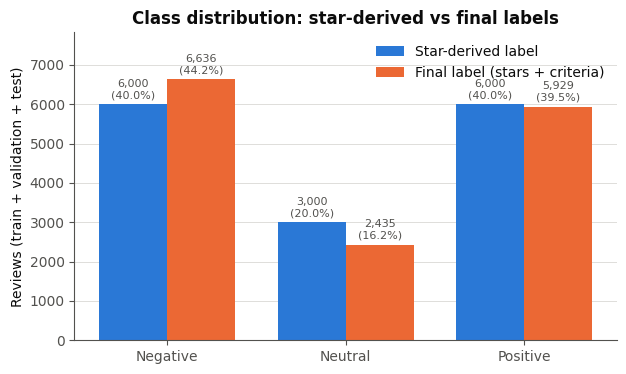

In [ ]:
# Section 3.1 - Class distribution (star vs final labels) and weight derivation
dist_rows = []
for k in ["train", "validation", "test"]:
    vc = df[k]["sentiment"].value_counts().sort_index()          # sentiment = final_label index
    for ci, name in enumerate(CLASS_NAMES):
        n = int(vc.get(ci, 0))
        dist_rows.append({"Partition": k, "Class": name, "n": n,
                          "Proportion": round(n / len(df[k]) * 100, 2)})
dist_df = pd.DataFrame(dist_rows)
pivot = dist_df.pivot(index="Class", columns="Partition", values="n").loc[CLASS_NAMES]
print("Final-label distribution by partition:")
display(pivot)
dist_df.to_csv(f"{PATHS['tables']}/table_class_distribution_final.csv", index=False)

# w_c = N / (C * n_c)   -- Paper Section 3.5.3, recomputed from the NEW (final-label) training counts
train_counts = df["train"]["sentiment"].value_counts().sort_index()
N, C = len(df["train"]), NUM_CLASSES
CLASS_WEIGHTS = torch.tensor(
    [N / (C * int(train_counts[c])) for c in range(C)], dtype=torch.float32)

weight_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "n_c": [int(train_counts[c]) for c in range(C)],
    "Share (%)": [round(int(train_counts[c]) / N * 100, 2) for c in range(C)],
    "w_c": [round(float(CLASS_WEIGHTS[c]), 4) for c in range(C)],
})
display(weight_df)
weight_df.to_csv(f"{PATHS['tables']}/table_class_weights.csv", index=False)

# Figure: star-derived vs final labels, all partitions pooled
cd = pd.DataFrame({"Class": CLASS_NAMES,
                   "Star-derived label": [int((ALL["star_label"] == c).sum()) for c in CLASS_NAMES],
                   "Final label":        [int((ALL["final_label"] == c).sum()) for c in CLASS_NAMES]})
cd["Star-derived share (%)"] = (cd["Star-derived label"] / len(ALL) * 100).round(2)
cd["Final share (%)"]        = (cd["Final label"] / len(ALL) * 100).round(2)
display(cd)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(CLASS_NAMES)); w = 0.38
b1 = ax.bar(x - w/2, cd["Star-derived label"], w, color=C1, label="Star-derived label")
b2 = ax.bar(x + w/2, cd["Final label"],        w, color=C2, label="Final label (stars + criteria)")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{int(b.get_height()):,}\n({b.get_height() / len(ALL) * 100:.1f}%)",
                    (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom",
                    xytext=(0, 3), textcoords="offset points", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("Reviews (train + validation + test)")
ax.set_ylim(0, max(cd["Star-derived label"].max(), cd["Final label"].max()) * 1.18)
ax.set_title("Class distribution: star-derived vs final labels")
ax.legend(loc="upper right")
save_fig(fig, "fig_class_distribution_star_vs_final", cd)

### Explanation — Section 3.1: Class Distribution and Weight Derivation

**Implements:** Paper Section 3.3 (distributional profile); Paper Section 3.5.3 (weight formula)

**What it does.** Profiles the **final-label** distribution across the three partitions, computes
the class-weight vector from the new training counts, and draws the pooled class distribution for
the star-derived labels next to the final labels.

**Why.** Weights are derived at runtime rather than hard-coded, so the values reported in Chapter
4 are guaranteed to be the values actually used in training. They must be recomputed here: the
old weights came from the star-derived counts, where Neutral held about half the support of the
other classes. The final labels move reviews between classes (Section 2.5), so the class balance
and therefore every `w_c` can change, and using the old weights would mis-weight the loss. The
figure shows exactly that shift, class by class, so a reader can see what the criteria did to the
label distribution before any model is trained.

**Key parameters**

| Symbol | Meaning |
|---|---|
| N | Total training samples |
| C | 3 (ternary classification) |
| n_c | Training count of class c under the **final label** |
| w_c | N / (C x n_c) |

**Check:** the `w_c` column, the distribution table, and the figure. Both tables are reported in
Chapter 4 as the empirically derived values referenced by Paper Section 3.5.3. The figure's
source numbers are in `tables/fig_class_distribution_star_vs_final.csv`.

final_label,final Negative (%),final Neutral (%),final Positive (%)
star,,,
1,86.8,5.2,8.0
2,72.3,11.2,16.5
3,34.6,38.1,27.3
4,20.8,18.4,60.8
5,6.7,8.3,85.1


saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_star_to_final_label.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_star_to_final_label.csv


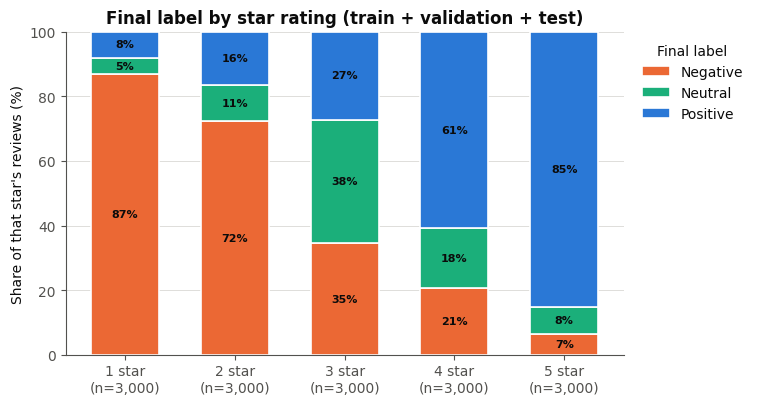

In [ ]:
# Section 3.1b - Figure: how the final label differs from the star rating
ct = pd.crosstab(ALL["star"], ALL["final_label"]).reindex(columns=CLASS_NAMES, fill_value=0)
share = ct.div(ct.sum(axis=1), axis=0) * 100
star_rows = [{"star": int(s), "final_label": c, "reviews": int(ct.loc[s, c]),
              "share_of_star_%": round(float(share.loc[s, c]), 2)}
             for s in ct.index for c in CLASS_NAMES]
star_fig_df = pd.DataFrame(star_rows)
display(share.round(1).rename(columns=lambda c: f"final {c} (%)"))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
xs = np.arange(len(ct)); bottom = np.zeros(len(ct))
for name in CLASS_NAMES:                                   # Negative at the bottom, Positive on top
    vals = share[name].values
    ax.bar(xs, vals, 0.62, bottom=bottom, color=CLASS_COLORS[name],
           edgecolor="white", linewidth=1.2, label=name)
    for i, v in enumerate(vals):
        if v >= 4:
            ax.text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center",
                    fontsize=8, color=INK, fontweight="bold")
    bottom += vals
ax.set_xticks(xs)
ax.set_xticklabels([f"{int(s)} star\n(n={int(ct.loc[s].sum()):,})" for s in ct.index])
ax.set_ylim(0, 100); ax.set_ylabel("Share of that star's reviews (%)")
ax.set_title("Final label by star rating (train + validation + test)")
ax.legend(title="Final label", loc="upper left", bbox_to_anchor=(1.01, 1))
save_fig(fig, "fig_star_to_final_label", star_fig_df)

### Explanation — Section 3.1b: Figure — Final Label by Star Rating

**Implements:** Reporting support for Chapter 4 (not a Paper Section 3 procedure)

**What it does.** For each star rating from 1 to 5, draws one stacked bar showing what share of those
reviews ended up Negative, Neutral or Positive under the final label (criteria label when a rule fired,
otherwise the star label).

**Why.** Section 3.1 shows how the class totals changed; this shows *where* the change came from. If the
final label simply followed the stars, the 1-2 star bars would be all Negative and the 4-5 star bars all
Positive. The mixed bars are the reviews the criteria moved away from their star label, and the 3-star bar
shows how many three-star reviews were judged Positive or Negative from the text.

**Key parameters**

| Element | Meaning |
|---|---|
| Bar | One star rating, rescaled to 100% |
| Segment | Share of that star's reviews with that final label |
| n | Reviews with that star (all partitions pooled) |

**Check:** each bar sums to 100%, and the source numbers are in `tables/fig_star_to_final_label.csv`.

Templated prompt length percentiles: {50: 100, 75: 116, 90: 136, 95: 145, 99: 164, 99.5: 177, 100: 1234}

MAX_LEN (p99, rounded to a multiple of 8) = 168
Template overhead = 68 tokens -> 100 for review text
Truncated: 81 / 10500 (0.77%)
saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_token_length_distribution.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_token_length_distribution.csv


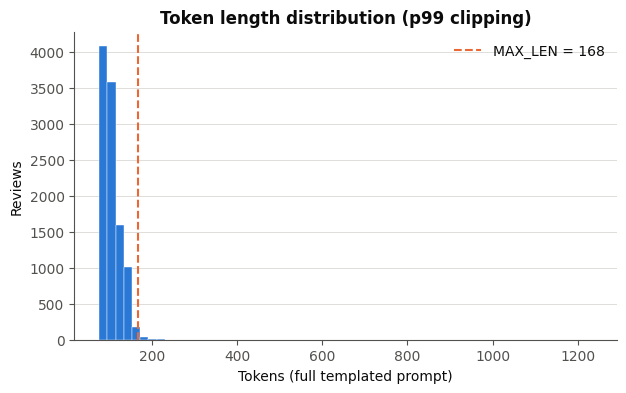

In [ ]:
# Section 3.2 - Token length percentiles and MAX_LEN derivation
def templated_len(text: str) -> int:
    return len(chat_ids(tok_probe, build_user_msg(text))) + 2   # + answer + <end_of_turn>

lens = np.array([templated_len(t) for t in df["train"]["clean_text"]])
pcts = {p: int(np.percentile(lens, p)) for p in [50, 75, 90, 95, 99, 99.5, 100]}
print("Templated prompt length percentiles:", pcts)

MAX_LEN = int(min(MAX_LEN_CAP, int(np.ceil(np.percentile(lens, LENGTH_PCTL) / 8) * 8)))
TEMPLATE_OVERHEAD = templated_len("")
print(f"\nMAX_LEN (p{LENGTH_PCTL}, rounded to a multiple of 8) = {MAX_LEN}")
print(f"Template overhead = {TEMPLATE_OVERHEAD} tokens -> {MAX_LEN - TEMPLATE_OVERHEAD} for review text")
print(f"Truncated: {(lens > MAX_LEN).sum()} / {len(lens)} ({(lens > MAX_LEN).mean()*100:.2f}%)")

counts, edges = np.histogram(lens, bins=60)
hist_df = pd.DataFrame({"bin_left": edges[:-1], "bin_right": edges[1:], "reviews": counts})
hist_df["max_len"] = MAX_LEN
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=C1, edgecolor="white", linewidth=0.3)
ax.axvline(MAX_LEN, color=C2, ls="--", lw=1.5, label=f"MAX_LEN = {MAX_LEN}")
ax.set_xlabel("Tokens (full templated prompt)"); ax.set_ylabel("Reviews")
ax.set_title(f"Token length distribution (p{LENGTH_PCTL} clipping)")
ax.legend()
save_fig(fig, "fig_token_length_distribution", hist_df)

### Explanation — Section 3.2: Token Length Percentiles and MAX_LEN Derivation

**Implements:** Paper Section 3.2 Phase 3; Paper Section 3.3 (percentile clipping)

**What it does.** Measures the tokenised length of every training prompt and derives `MAX_LEN`
from the 99th percentile, rounded up to a multiple of 8.

**Why.** Two decisions are worth defending. First, the percentile is computed over the *fully
templated* sequence — control tokens, instruction, review and answer slot — because templated
length is what actually consumes attention memory. Second, p99 rather than p95: the long tail is
where the multi-clause, code-switch-dense reviews live, which is exactly what the Challenger Set
(3.7.1) targets, so a tighter percentile would preferentially truncate the samples the study
cares most about. Rounding to a multiple of 8 keeps tensor-core alignment.

**Key parameters**

| Value | Source |
|---|---|
| `LENGTH_PCTL` = 99 | Paper Section 3.3 |
| `MAX_LEN_CAP` = 512 | Safety ceiling |
| `TEMPLATE_OVERHEAD` | Measured, not assumed |

**Check:** `MAX_LEN` in the low hundreds and a truncation rate well under one percent. Report
that rate in Chapter 4 as evidence for the semantic-integrity claim in Paper Section 3.2.

In [ ]:
# Section 3.3 - Tokenizer fragmentation
TAGLISH_PROBE = df["train"].sample(6, random_state=42)
for _, r in TAGLISH_PROBE.iterrows():
    toks = tok_probe.tokenize(r["clean_text"])
    ratio = len(toks) / max(1, len(r["clean_text"].split()))
    print(f"[{CLASS_NAMES[r['sentiment']]}, {r['star']} star] {r['clean_text'][:110]}")
    print(f"  -> {toks[:28]}")
    print(f"  -> {len(toks)} tokens / {len(r['clean_text'].split())} words "
          f"(fragmentation ratio {ratio:.2f})\n")

[Positive, 5 star] Good naman lahat, mabait din yung seller at mabilis na ship at naipadala dito sa bahay. Mura na maganda pa goo
  -> ['Good', '▁naman', '▁lahat', ',', '▁mab', 'ait', '▁din', '▁yung', '▁seller', '▁at', '▁mab', 'ilis', '▁na', '▁ship', '▁at', '▁na', 'ipad', 'ala', '▁dito', '▁sa', '▁bahay', '.', '▁Mura', '▁na', '▁mag', 'anda', '▁pa', '▁goods']
  -> 43 tokens / 32 words (fragmentation ratio 1.34)

[Negative, 2 star] Super small ang xl pang maliliit lang d pwede adult
  -> ['Super', '▁small', '▁ang', '▁xl', '▁pang', '▁mal', 'ili', 'it', '▁lang', '▁d', '▁p', 'wede', '▁adult']
  -> 13 tokens / 10 words (fragmentation ratio 1.30)

[Negative, 1 star] ang layu ng kulay gray and black order. dumating yellow, violet, green anoarunong kaba sa kulay daig pa kayu n
  -> ['ang', '▁lay', 'u', '▁ng', '▁ku', 'lay', '▁gray', '▁and', '▁black', '▁order', '.', '▁dum', 'ating', '▁yellow', ',', '▁violet', ',', '▁green', '▁ano', 'ar', 'un', 'ong', '▁k', 'aba', '▁sa', '▁ku', 'lay', '▁da']
  -> 4

### Explanation — Section 3.3: Tokenizer Fragmentation

**Implements:** Paper Section 3.3 (qualitative review)

**What it does.** Inspects tokenizer fragmentation on six Taglish reviews: the tokens each review
becomes and the tokens-per-word ratio. The bracketed tag shows the review's final label.

**Why.** The fragmentation ratio is a reportable finding: a high tokens-per-word ratio on Taglish
is direct evidence for the claim in Paper Section 1.2 that English-centric SentencePiece
vocabularies fragment hybrid morphology. In the original notebook this cell also exported a
150-review sheet for manual discordance annotation. That export is removed: the discordance
sample is reused from the old annotation files (Section 3.4), and nothing is annotated again.

**Key parameters**

| Item | Value |
|---|---|
| Fragmentation probe | 6 reviews, `random_state=42` |

**Check:** the fragmentation ratios per review.

In [ ]:
# Section 3.4 - Star-text discordance from the OLD manual annotations (reused as they are)
disc_path = find_legacy("discordance_sample_150.csv")
disc_base = pd.read_csv(disc_path)
need = {"sample_id", "star", "annotator_1_agrees", "annotator_2_agrees", "adjudicated_agrees"}
assert need <= set(disc_base.columns), f"{disc_path} is missing {sorted(need - set(disc_base.columns))}"

# the reused sample must still describe the same reviews in the rebuilt dataset
chk = disc_base.merge(df["test"][["sample_id", "star"]], on="sample_id", how="left", suffixes=("", "_new"))
assert chk["star_new"].notna().all() and (chk["star"] == chk["star_new"]).all(), \
    "Old discordance sample_ids do not line up with the rebuilt test partition."
print(f"Reusing {disc_path}\n  {len(disc_base)} reviews, sample_ids and stars match the rebuilt test partition.")

same_d     = disc_base["annotator_1_agrees"] == disc_base["annotator_2_agrees"]
KAPPA_DISC = cohen_kappa_score(disc_base["annotator_1_agrees"].astype(int),
                               disc_base["annotator_2_agrees"].astype(int))
n_disc     = int((disc_base["adjudicated_agrees"].astype(int) == 0).sum())
DISC_RATE  = n_disc / len(disc_base) * 100

print(f"Round 1 Cohen's kappa      = {KAPPA_DISC:.4f}  (target 0.70)")
print(f"Disagreements adjudicated  = {int((~same_d).sum())}")
print(f"Discordance rate           = {DISC_RATE:.2f}%  ({n_disc}/{len(disc_base)})")
print("[!] ABOVE the 15% threshold - Paper Section 3.2.1 requires this be reported"
      if DISC_RATE > 15 else "Within the 15% threshold (Paper Section 3.2.1).")

by_star_manual = (disc_base.assign(disc=disc_base["adjudicated_agrees"].astype(int) == 0)
                  .groupby("star")["disc"].agg(["sum", "count"]))
by_star_manual.columns = ["discordant", "n"]
by_star_manual["rate_%"] = (by_star_manual["discordant"] / by_star_manual["n"] * 100).round(1)
print("\nManual discordance by star rating (old annotation, reused):")
display(by_star_manual)

by_star_manual.to_csv(f"{PATHS['tables']}/table_discordance_by_star.csv")
pd.DataFrame([{"round_1_kappa": round(KAPPA_DISC, 4), "sample_size": len(disc_base),
               "adjudicated": int((~same_d).sum()), "discordant": n_disc,
               "discordance_rate_pct": round(DISC_RATE, 2), "threshold_pct": 15,
               "exceeds_threshold": bool(DISC_RATE > 15), "source": "old manual annotation (reused)"}]
            ).to_csv(f"{PATHS['tables']}/table_discordance_summary.csv", index=False)

Reusing /content/drive/MyDrive/taglish_peft_thesis/annotation/discordance_sample_150.csv
  150 reviews, sample_ids and stars match the rebuilt test partition.
Round 1 Cohen's kappa      = 0.2809  (target 0.70)
Disagreements adjudicated  = 34
Discordance rate           = 18.67%  (28/150)
[!] ABOVE the 15% threshold - Paper Section 3.2.1 requires this be reported

Manual discordance by star rating (old annotation, reused):


,discordant,n,rate_%
star,,,
1,1,30,3.3
2,3,20,15.0
3,9,50,18.0
4,11,27,40.7
5,4,23,17.4


### Explanation — Section 3.4: Star-Text Discordance (Old Annotation, Reused)

**Implements:** Paper Section 3.2.1 (star-text discordance check)

**What it does.** Reads the old `discordance_sample_150.csv` as it is — it already holds both
annotators' columns and the adjudicated column — checks that its `sample_id`s and star ratings
still match the rebuilt test partition, and recomputes Cohen's kappa, the discordance rate and the
rate by star. Nothing is annotated again and the old file is not modified (it is read from the old
folder or from the copy that `find_legacy` placed in the new `annotation/` folder).

**Why.** This is the evidence that motivated the revision: the original labels were star-derived,
and two people reading 150 test reviews judged 18.67 percent of them as text that does not match
the star, above the 15 percent threshold of Paper Section 3.2.1. First-round kappa was 0.281,
below the 0.70 target; the disagreement was one-sided (Annotator 1 flagged far more reviews than
Annotator 2), which points to a difference in strictness rather than in understanding. Keep the
two discordance figures apart in Chapter 4. This one is a **manual judgment on 150 reviews against
the old star labels**; the number in Section 2.5 is the **automatic criteria-vs-star disagreement
on every review**.

**Key parameters**

| Item | Value |
|---|---|
| Sample size | 150 (50 per class, from the old star labels) |
| Source | Old annotation file, reused unchanged |
| Paper Section 3.2.1 threshold | 15 percent |

**Check:** the `sample_ids match` line, then the rate (18.67 percent expected, 28 of 150) and the
per-star breakdown.

# Section 4: Dataset Encoding

Applies the Section 2.3 prompt template using the `MAX_LEN` derived in Section 3.2. This is Phase
3 of Paper Section 3.2, placed here because it depends on the EDA result. Produces one tokenised
artifact reused by both configurations, so observed differences are attributable to
fine-tuning method rather than data handling.

In [ ]:
# Section 4.1 - Encode all partitions
def encode_split(frame, tokenizer, max_len, with_answer=True):
    recs = []
    max_text = max_len - TEMPLATE_OVERHEAD - 2
    assert max_text > 8, (
        f"max_text={max_text} is too small. MAX_LEN={max_len}, overhead={TEMPLATE_OVERHEAD}. "
        "Re-run Section 3.2.")
    for _, r in frame.iterrows():
        text = r["clean_text"]
        t_ids = tokenizer.encode(text, add_special_tokens=False)
        if len(t_ids) > max_text:                   # truncate the REVIEW, never the template
            text = tokenizer.decode(t_ids[:max_text], skip_special_tokens=True)
        prompt_ids = chat_ids(tokenizer, build_user_msg(text))
        rec = {"sample_id": r["sample_id"], "prompt_ids": prompt_ids,
               "class_label": int(r["sentiment"]), "n_prompt": len(prompt_ids)}
        if with_answer:
            ans = int(LABEL_TOKEN_IDS[int(r["sentiment"])])
            rec["input_ids"] = prompt_ids + [ans, int(tokenizer.eos_token_id)]
            rec["pred_pos"]  = len(prompt_ids) - 1  # logit index that PREDICTS the answer
        recs.append(rec)
    return recs

ENC = {k: encode_split(df[k], tok_probe, MAX_LEN) for k in ["train", "validation", "test"]}
print({k: len(v) for k, v in ENC.items()})

_e = ENC["train"][0]
print("\nDecoded training example:")
print(tok_probe.decode(_e["input_ids"]))
print(f"\npred_pos = {_e['pred_pos']}, supervised token = "
      f"{tok_probe.convert_ids_to_tokens(_e['input_ids'][_e['pred_pos']+1])}, "
      f"class = {CLASS_NAMES[_e['class_label']]}")

{'train': 10500, 'validation': 2250, 'test': 2250}

Decoded training example:
<bos><start_of_turn>user
You are analyzing product reviews from a Philippine e-commerce platform. The reviews are written in Taglish, a mix of Tagalog and English. Classify the sentiment of the review as Positive, Neutral, or Negative. Answer with one word only.

Review: A cute niya umiilaw nman siya. I will order again para mas lalo maliwanag.
Sentiment:<end_of_turn>
<start_of_turn>model
Positive<eos>

pred_pos = 87, supervised token = Positive, class = Positive


### Explanation — Section 4.1: Encode All Partitions

**Implements:** Paper Section 3.2, Phase 3 (tokenization)

**What it does.** Applies the chat template to every review, appends the single answer token, and
records `pred_pos` — the index of the logit that predicts it.

**Why.** Truncation targets the *review text*, never the assembled sequence: truncating the
assembled sequence would let a long review consume the closing control tokens and leave a
malformed prompt. `pred_pos` deserves attention — causal language models predict position i+1
from position i, so the logit to supervise sits at `len(prompt_ids) - 1`, not at the answer
index. An off-by-one here is a silent bug that trains the model to predict the final prompt token
instead of the label, producing plausible losses that never converge. Encoding once and reusing
the result across both configurations is what lets differences be attributed to the
fine-tuning method.

**Key parameters**

| Field | Meaning |
|---|---|
| `prompt_ids` | Templated prompt, no answer (inference) |
| `input_ids` | Prompt + answer token + end-of-turn (training) |
| `pred_pos` | `len(prompt_ids) - 1` |
| `class_label` | Ternary class index |

**Check:** the decoded example shows the control tokens, instruction, review and a single label
word — and the printed supervised token matches the printed class.

In [ ]:
# Section 4.2 - Collators: right-padded for training, left-padded for inference
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

PAD_ID = tok_probe.pad_token_id if tok_probe.pad_token_id is not None else tok_probe.eos_token_id

class RecordSet(Dataset):
    def __init__(self, recs): self.recs = recs
    def __len__(self):        return len(self.recs)
    def __getitem__(self, i): return self.recs[i]

def train_collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids  = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):                       # RIGHT pad
        n = len(b["input_ids"])
        ids[i, :n]  = torch.tensor(b["input_ids"], dtype=torch.long)
        mask[i, :n] = 1
    return {"input_ids": ids, "attention_mask": mask,
            "pred_pos":    torch.tensor([b["pred_pos"]    for b in batch], dtype=torch.long),
            "class_label": torch.tensor([b["class_label"] for b in batch], dtype=torch.long)}

def infer_collate(batch):
    L = max(len(b["prompt_ids"]) for b in batch)
    ids  = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):                       # LEFT pad
        n = len(b["prompt_ids"])
        ids[i, L-n:]  = torch.tensor(b["prompt_ids"], dtype=torch.long)
        mask[i, L-n:] = 1
    pos_ids = (mask.cumsum(-1) - 1).clamp(min=0)
    return {"input_ids": ids, "attention_mask": mask, "position_ids": pos_ids,
            "class_label": torch.tensor([b["class_label"] for b in batch], dtype=torch.long),
            "sample_id":   [b["sample_id"] for b in batch]}

_b = train_collate([ENC["train"][0], ENC["train"][1]])
print({k: (tuple(v.shape) if torch.is_tensor(v) else v) for k, v in _b.items()})

{'input_ids': (2, 116), 'attention_mask': (2, 116), 'pred_pos': (2,), 'class_label': (2,)}


### Explanation — Section 4.2: Collators

**Implements:** Batching support for Sections 6, 7 and 8

**What it does.** Defines two collators with deliberately opposite padding sides, plus the
`position_ids` correction that left padding requires.

**Why.** This is correctness, not style. Training gathers logits at an explicit per-sample
`pred_pos`, so right padding is safe and slightly cheaper. Inference reads the logit at the
*final* position; under right padding that position holds a pad token for every sample except the
longest in the batch, so the model would be scored on padding. Left padding aligns the true final
prompt token at index -1 for every row. Left padding then requires explicit `position_ids`,
because the default `arange` assigns position 0 to a pad token and shifts every real token's
rotary embedding by the pad count — a quiet degradation that looks like a weak model rather than
a bug.

**Key parameters**

| Collator | Padding side | Used by |
|---|---|---|
| `train_collate` | Right | Section 6 training |
| `infer_collate` | Left | Sections 6, 7, 8 inference |

**Check:** a shape dictionary with `input_ids` and `attention_mask` of equal shape, and
`pred_pos` / `class_label` of length equal to the batch size.

# PART II — PROCESS

Paper Section 3.4, Process stage: base model selection (3.5.1), two parallel fine-tuning tracks
(Gemma-2-2B and Gemma-2-9B), each adapted with 4-bit QLoRA and class-weighted loss (3.5.3), then
evaluated on the held-out test set (3.6). The 16-bit LoRA variants of the original design are
dropped in this revision.

# Section 5: Base Model Selection and Configuration

Implements Paper Section 3.5.1 (model selection), Section 3.5.2 and Table 3.7 (hyperparameters),
and Section 3.5.4 (LoRA reparameterization).

In [ ]:
# Section 5.1 - Configuration registry (Table 3.7) - QLoRA only
@dataclass
class RunConfig:
    name: str
    model_id: str
    quantized: bool
    learning_rate: float
    per_device_bs: int
    grad_accum: int
    epochs: int = 3
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.05
    target_modules: List[str] = field(
        default_factory=lambda: ["q_proj", "k_proj", "v_proj", "o_proj"])
    optim: str = "paged_adamw_32bit"
    weight_decay: float = 0.01
    grad_checkpointing: bool = True
    @property
    def effective_bs(self): return self.per_device_bs * self.grad_accum

CONFIGS = {
    "2b_qlora": RunConfig("2b_qlora", "google/gemma-2-2b-it", True, 2e-4, 8, 2),
    "9b_qlora": RunConfig("9b_qlora", "google/gemma-2-9b-it", True, 1e-4, 4, 4),
}
CONFIG_ORDER = list(CONFIGS)          # ["2b_qlora", "9b_qlora"]

# Hardware overrides. Effective batch size is held at 16 in EVERY case (Table 3.7).
VRAM = HW["total_vram_gb"]
if VRAM < 20:            # T4 16 GB
    CONFIGS["9b_qlora"].per_device_bs, CONFIGS["9b_qlora"].grad_accum = 2, 8
    FEASIBLE = list(CONFIGS)
    NOTE = "T4 16 GB: both feasible, 9b_qlora uses per-device batch 2 x accumulation 8. Debug tier only."
elif VRAM < 30:          # L4 24 GB
    FEASIBLE = list(CONFIGS)
    NOTE = "L4 24 GB: both feasible at the Table 3.7 batch sizes."
else:                    # A100 40 GB or larger
    FEASIBLE = list(CONFIGS)
    NOTE = "A100: both feasible at the Table 3.7 batch sizes."

print(NOTE, "\n")
display(pd.DataFrame([{
    "Variant": c.name, "Model": c.model_id.split('/')[-1],
    "Quantization": "NF4 + double" if c.quantized else "none",
    "LR": c.learning_rate, "Batch": c.per_device_bs, "Accum": c.grad_accum,
    "Effective": c.effective_bs, "r": c.lora_r, "alpha": c.lora_alpha,
    "Feasible here": c.name in FEASIBLE,
} for c in CONFIGS.values()]))

A100: both feasible at the Table 3.7 batch sizes. 



,Variant,Model,Quantization,LR,Batch,Accum,Effective,r,alpha,Feasible here
0,2b_qlora,gemma-2-2b-it,NF4 + double,0.0002,8,2,16,16,32,True
1,9b_qlora,gemma-2-9b-it,NF4 + double,0.0001,4,4,16,16,32,True


### Explanation — Section 5.1: Configuration Registry

**Implements:** Paper Section 3.5.2, Table 3.7

**What it does.** Declares the two QLoRA configurations exactly as Table 3.7 specifies, then
applies a hardware-dependent per-device batch override while holding the effective batch size at
16.

**Why.** Every Table 3.7 value is reproduced verbatim: rank 16, alpha 32, dropout 0.05, the four
attention projections, `paged_adamw_32bit`, weight decay 0.01, three epochs, NF4 with double
quantization, and learning rates of 2e-4 (2B) and 1e-4 (9B). The `2b_lora` and `9b_lora` entries
of the original registry are removed, so nothing downstream can accidentally train or evaluate a
16-bit variant. The batch override needs justification: gradient accumulation sums gradients
across micro-batches before the optimizer step, so 2 x 8 produces a *mathematically identical*
update to 4 x 4 — only memory profile and wall-clock differ. On an A100 no override is applied at
all.

**Key parameters**

| Hyperparameter | 2B | 9B |
|---|---|---|
| Learning rate | 2e-4 | 1e-4 |
| Per-device batch | 8 | 4 |
| Gradient accumulation | 2 | 4 |
| Effective batch | 16 | 16 |
| Rank / alpha / dropout | 16 / 32 / 0.05 | 16 / 32 / 0.05 |

**Check:** on A100, the note reads "both feasible at the Table 3.7 batch sizes" and every
`Feasible here` cell is `True`.

In [ ]:
# Section 5.2 - Model construction and the answer-position forward pass
from transformers import (BitsAndBytesConfig, TrainingArguments, Trainer, TrainerCallback,
                          set_seed as hf_set_seed)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

def build_base_model(cfg: RunConfig, for_training: bool = True):
    # Frozen base ONLY. Quantization must match between training and evaluation.
    kw = dict(token=HF_TOKEN, attn_implementation="eager", device_map={"": 0})
    if cfg.quantized:
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",              # Table 3.7
            bnb_4bit_use_double_quant=True,         # Table 3.7
            bnb_4bit_compute_dtype=COMPUTE_DTYPE)
    else:
        kw[_DTYPE_KW] = COMPUTE_DTYPE
    model = AutoModelForCausalLM.from_pretrained(cfg.model_id, **kw)
    model.config.use_cache = False
    if for_training:
        if cfg.quantized:
            model = prepare_model_for_kbit_training(
                model, use_gradient_checkpointing=cfg.grad_checkpointing)
        if cfg.grad_checkpointing:
            model.gradient_checkpointing_enable()
            model.enable_input_require_grads()
    return model

def build_model(cfg: RunConfig):
    # Base + freshly initialised LoRA adapters, for TRAINING.
    model = build_base_model(cfg, for_training=True)
    lcfg = LoraConfig(r=cfg.lora_r, lora_alpha=cfg.lora_alpha, lora_dropout=cfg.lora_dropout,
                      target_modules=cfg.target_modules, bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(model, lcfg)
    model.print_trainable_parameters()
    return model

def get_causal_lm(model):
    # PeftModel forwards attribute lookups to the model it wraps, so a naive
    # hasattr(model, "lm_head") check stops on the wrapper. The correct module is the one
    # whose .model has NO lm_head of its own (the bare decoder stack).
    m = model
    if hasattr(m, "get_base_model"):
        try: m = m.get_base_model()
        except Exception: pass
    for _ in range(6):
        inner = getattr(m, "model", None)
        if hasattr(m, "lm_head") and inner is not None and not hasattr(inner, "lm_head"):
            return m
        nxt = getattr(m, "base_model", None)
        if nxt is None or nxt is m: nxt = inner
        if nxt is None or nxt is m: break
        m = nxt
    raise ValueError(f"Could not locate the CausalLM module (stopped at {type(m).__name__}).")

def answer_logits(model, input_ids, attention_mask, pred_pos, position_ids=None):
    # Slice hidden states BEFORE the LM head -> [B, vocab] instead of [B, seq, vocab].
    clm = get_causal_lm(model)
    kw = {"input_ids": input_ids, "attention_mask": attention_mask}
    if position_ids is not None: kw["position_ids"] = position_ids
    out = clm.model(**kw)
    h = getattr(out, "last_hidden_state", None)
    if h is None:
        h = out[0] if isinstance(out, (tuple, list)) else None
    if h is None or h.dim() != 3:
        raise RuntimeError(f"Expected hidden states, got {type(out).__name__}.")
    idx = pred_pos.to(h.device).view(-1, 1, 1).expand(-1, 1, h.size(-1))
    h = h.gather(1, idx).squeeze(1)
    logits = clm.lm_head(h).float()                  # fp32 for numerical stability
    cap = getattr(clm.config, "final_logit_softcapping", None)
    if cap:
        logits = torch.tanh(logits / cap) * cap      # Gemma-2 final logit soft-capping
    return logits

### Explanation — Section 5.2: Model Construction and Answer-Position Forward Pass

**Implements:** Paper Section 3.5.4 (LoRA reparameterization); Table 3.7 (NF4 double quantization)

**What it does.** Builds the frozen base with NF4 double quantization for both QLoRA configurations,
injects LoRA adapters into the four attention projections, and defines the forward pass used by
both training and inference.

**Why.** Three points matter here.

`attn_implementation="eager"` is **mandatory**. Gemma-2 applies logit soft-capping inside
attention, and the SDPA and FlashAttention-2 kernels do not implement it — they silently skip the
capping rather than raising. Using them would change results relative to the published
architecture.

Hidden states are sliced *before* the LM head for memory. Gemma-2's vocabulary is 256,000 tokens,
so a full `[batch, seq, vocab]` logit tensor exceeds a gigabyte per copy at modest batch sizes.
Because exactly one position is supervised, slicing first reduces this to `[batch, vocab]`.

`get_causal_lm` descends past the PEFT wrapper explicitly, because `PeftModel` forwards unknown
attribute lookups to the model it wraps — a naive `hasattr` check finds `lm_head` on the wrapper
and stops one level too early.

**Key parameters**

| Setting | Value | Source |
|---|---|---|
| Quantization type | NF4 | Table 3.7 |
| Double quantization | Enabled | Table 3.7 |
| Target modules | q_proj, k_proj, v_proj, o_proj | Table 3.7 |
| Attention implementation | eager | Gemma-2 soft-capping requirement |

**Check:** nothing prints; the cell only defines functions. Trainable parameter counts appear
when Section 6 calls `build_model`.

# Section 6: Fine-Tuning

Implements Paper Section 3.5.3 (class-weighted cross-entropy) and Paper Section 3.1
(validation-guided checkpoint selection).

In [ ]:
# Section 6.1 - Class-weighted loss and training callbacks
class WeightedAnswerTokenTrainer(Trainer):
    def __init__(self, *a, class_weights=None, **kw):
        super().__init__(*a, **kw)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        cls      = inputs["class_label"]
        pred_pos = inputs["pred_pos"]
        logits   = answer_logits(model, inputs["input_ids"], inputs["attention_mask"], pred_pos)
        target   = LABEL_TOKEN_IDS.to(logits.device)[cls]
        per      = F.cross_entropy(logits, target, reduction="none")
        w        = self.class_weights.to(logits.device)[cls]
        loss     = (per * w).sum() / w.sum()
        return (loss, {"logits": logits}) if return_outputs else loss

class NaNGuard(TrainerCallback):
    def on_log(self, args, state, control, logs=None, **kw):
        if logs and "loss" in logs and not np.isfinite(logs["loss"]):
            print(f"\n[FATAL] Non-finite loss at step {state.global_step}. Halting.")
            print("        Switch COMPUTE_DTYPE to torch.float32 for the 16-bit variants,")
            print("        or move to bfloat16-capable hardware.")
            control.should_training_stop = True
        return control

class ValidationSelector(TrainerCallback):
    # Checkpoint selection on validation Macro F1 (Paper Section 3.1, Table 3.1).
    def __init__(self, model, val_recs, out_dir, eval_every=200, bs=32):
        self.model, self.val_recs, self.out_dir = model, val_recs, out_dir
        self.eval_every, self.bs = eval_every, bs
        self.best, self.history = -1.0, []
    def _evaluate(self, step, epoch):
        from sklearn.metrics import f1_score
        preds, gold, _ = predict_labels(self.model, self.val_recs, self.bs)
        f1 = f1_score(gold, preds, average="macro", zero_division=0)
        self.history.append({"step": int(step), "epoch": round(float(epoch or 0), 3),
                             "val_macro_f1": round(float(f1), 5)})
        flag = ""
        if f1 > self.best:
            self.best = f1
            self.model.save_pretrained(self.out_dir)
            flag = "  <- new best, adapter saved"
        print(f"  [step {int(step):5d}] validation Macro F1 = {f1:.4f}{flag}")
        return f1
    def on_step_end(self, args, state, control, **kw):
        if self.eval_every and state.global_step > 0 and state.global_step % self.eval_every == 0:
            self._evaluate(state.global_step, state.epoch)
        return control
    def on_epoch_end(self, args, state, control, **kw):
        self._evaluate(state.global_step, state.epoch)
        return control

### Explanation — Section 6.1: Class-Weighted Loss and Training Callbacks

**Implements:** Paper Section 3.5.3 (weighted cross-entropy); Paper Section 3.1 (checkpoint
selection)

**What it does.** Implements class-weighted cross-entropy at the single supervised token
position, plus a numerical-stability guard and a validation-driven checkpoint selector.

**Why.** Paper Section 3.5.3 writes the loss in the notation of a classification head, while
Paper Section 3.5.1 argues *against* adding one — avoiding a classification head is the stated
reason Gemma-2 was chosen over XLM-R. The resolution keeps the instruction format and the causal
LM objective but supervises exactly one token position and weights its cross-entropy by the true
class. With a single supervised token, token-level and class-level cross-entropy coincide, so
this is the paper's equation with C = 3, realised without contradicting the model-selection
rationale. Normalising by the sum of weights rather than batch size keeps the effective learning
rate stable across batches of differing class composition.

`ValidationSelector` evaluates every 200 steps as well as at epoch boundaries: Paper Section 3.1
assigns validation the checkpoint-selection role without fixing a frequency, and evaluating only
at epoch ends gives three candidates across roughly 1,969 steps. Selection is on **Macro F1**,
because Paper Section 3.6 designates it the imbalance-sensitive metric and selecting on accuracy
would bias toward the majority classes.

**Key parameters**

| Setting | Value |
|---|---|
| Loss | Class-weighted CE at the answer token |
| Weight source | `CLASS_WEIGHTS` from Section 3.1 |
| Selection metric | Validation Macro F1 |
| Evaluation frequency | Every 200 steps and each epoch end |

**Check:** nothing prints here. During training, watch for the periodic validation Macro F1 lines
and the new-best markers.

In [ ]:
# Section 6.2 - Constrained-decoding inference (greedy, temperature 0.0)
@torch.no_grad()
def predict_labels(model, recs, batch_size=32, return_probs=False):
    was_training = model.training
    model.eval()
    dl = DataLoader(RecordSet(recs), batch_size=batch_size, shuffle=False,
                    collate_fn=infer_collate)
    preds, gold, ids, probs = [], [], [], []
    dev = next(model.parameters()).device
    for b in dl:
        n, L = b["input_ids"].size(0), b["input_ids"].size(1)
        logits = answer_logits(model, b["input_ids"].to(dev), b["attention_mask"].to(dev),
                               pred_pos=torch.full((n,), L - 1, dtype=torch.long),
                               position_ids=b["position_ids"].to(dev))
        sel = logits[:, LABEL_TOKEN_IDS.to(logits.device)]   # restrict to the 3 label tokens
        preds.extend(sel.argmax(-1).cpu().tolist())
        gold.extend(b["class_label"].tolist())
        ids.extend(b["sample_id"])
        if return_probs:
            probs.extend(torch.softmax(sel, -1).cpu().tolist())
    if was_training: model.train()
    return (np.array(preds), np.array(gold), ids) if not return_probs else \
           (np.array(preds), np.array(gold), ids, np.array(probs))

### Explanation — Section 6.2: Constrained-Decoding Inference

**Implements:** Paper Section 3.7.1 (greedy decoding at temperature 0.0)

**What it does.** Reads the logits at the answer position and takes the argmax over only the
three label token identifiers.

**Why.** Argmax is exactly what greedy decoding converges to at temperature 0, so restricting it
to the valid label space satisfies the specification while gaining two properties free generation
cannot. First, unparseable outputs become structurally impossible — a 2B model generating freely
will sometimes emit a sentence or a leading newline instead of a bare label, and every
regex rescue is an uncontrolled confound in the metrics, because a genuine prediction
error could no longer be distinguished from a formatting difference. Second, it is roughly
twenty times faster, being a single forward pass; across 2,250 samples x 2 configurations x 3
seeds plus every validation pass, that is hours versus minutes.

`return_probs=True` yields the softmax over the three labels, which Section 8 stores for
every review and Section 14 displays.

**Key parameters**

| Setting | Value |
|---|---|
| Decoding | Argmax over 3 label tokens |
| Temperature | 0.0 (equivalent) |
| Padding | Left, with corrected `position_ids` |

**Check:** nothing prints; the function is called by Sections 6, 7 and 8.

In [ ]:
# Section 6.3 - Training orchestrator (one configuration, one seed)
import time, inspect
from sklearn.metrics import f1_score

_TA_PARAMS = set(inspect.signature(TrainingArguments.__init__).parameters)

def _make_targs(**kw):
    # TrainingArguments has been restructured across major versions. Drop unsupported keys
    # rather than crashing, but REPORT them - a silently dropped flag would change what
    # the experiment actually ran.
    keep = {k: v for k, v in kw.items() if k in _TA_PARAMS}
    drop = sorted(set(kw) - set(keep))
    if drop:
        print(f"[!] TrainingArguments ignored (unsupported in this version): {drop}")
        for critical in ["fp16", "bf16", "optim", "label_names", "remove_unused_columns"]:
            if critical in drop:
                print(f"    [WARNING] '{critical}' is experimentally significant. Verify manually.")
    return TrainingArguments(**keep)

def run_experiment(cfg_name: str, seed: int, resume: bool = True):
    cfg = CONFIGS[cfg_name]
    if cfg_name not in FEASIBLE:
        print(f"[!] '{cfg_name}' is flagged infeasible on this GPU ({HW['name']}, {VRAM} GB).")
        print(f"    {NOTE}")
    tag      = f"{cfg_name}_seed{seed}" + ("_SMOKE" if SMOKE_TEST else "")
    ada_dir  = f"{PATHS['adapters']}/{tag}"
    ckpt_dir = f"{PATHS['checkpoints']}/{tag}"
    done_json = f"{PATHS['metrics']}/{tag}_train.json"
    if resume and os.path.exists(done_json) and os.path.isdir(ada_dir):
        print(f"{tag}: already trained ({done_json}) - skipping.")
        with open(done_json) as f:
            return json.load(f)
    print(f"\n{'='*72}\n{tag}  |  {cfg.model_id}  |  effective batch {cfg.effective_bs}\n{'='*72}")

    set_all_seeds(seed); hf_set_seed(seed)
    tr_recs  = ENC["train"][:200]      if SMOKE_TEST else ENC["train"]
    val_recs = ENC["validation"][:100] if SMOKE_TEST else ENC["validation"]

    model = build_model(cfg)
    targ = dict(
        output_dir=ckpt_dir,
        num_train_epochs=1 if SMOKE_TEST else cfg.epochs,
        max_steps=50 if SMOKE_TEST else -1,
        per_device_train_batch_size=cfg.per_device_bs,
        gradient_accumulation_steps=cfg.grad_accum,
        learning_rate=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
        optim=cfg.optim,
        lr_scheduler_type="cosine", warmup_ratio=0.03,
        logging_steps=10, save_strategy="steps", save_steps=100, save_total_limit=2,
        fp16=(COMPUTE_DTYPE == torch.float16), bf16=(COMPUTE_DTYPE == torch.bfloat16),
        max_grad_norm=1.0, gradient_checkpointing=cfg.grad_checkpointing,
        report_to="none", label_names=["class_label"], remove_unused_columns=False,
        seed=seed, data_seed=seed,
    )
    if "warmup_ratio" not in _TA_PARAMS and "warmup_steps" in _TA_PARAMS:
        targ.pop("warmup_ratio", None)
        targ["warmup_steps"] = 10 if SMOKE_TEST else 60
    args = _make_targs(**targ)

    selector = ValidationSelector(model, val_recs, ada_dir,
                                  eval_every=25 if SMOKE_TEST else EVAL_EVERY)
    trainer = WeightedAnswerTokenTrainer(
        model=model, args=args, train_dataset=RecordSet(tr_recs),
        data_collator=train_collate, class_weights=CLASS_WEIGHTS,
        callbacks=[NaNGuard(), selector])

    ckpt = None
    if resume and os.path.isdir(ckpt_dir) and any(d.startswith("checkpoint-")
                                                  for d in os.listdir(ckpt_dir)):
        ckpt = True
        print("Resuming from checkpoint.")
    t0 = time.time()
    trainer.train(resume_from_checkpoint=ckpt)
    mins = (time.time() - t0) / 60
    peak = torch.cuda.max_memory_allocated() / 1024**3
    print(f"\nDone in {mins:.1f} min | peak VRAM {peak:.2f} GB | "
          f"best validation Macro F1 {selector.best:.4f}")

    meta = {"config": cfg_name, "seed": seed, "minutes": round(mins, 2),
            "peak_vram_gb": round(peak, 2), "best_val_macro_f1": selector.best,
            "history": selector.history, "smoke": SMOKE_TEST,
            "effective_batch": cfg.effective_bs, "dtype": str(COMPUTE_DTYPE),
            "hyperparameters": asdict(cfg)}
    with open(f"{PATHS['metrics']}/{tag}_train.json", "w") as f:
        json.dump(meta, f, indent=2)
    teardown(trainer, model, selector)
    return meta

### Explanation — Section 6.3: Training Orchestrator

**Implements:** Paper Section 3.5.2 (Table 3.7 hyperparameters); Paper Section 3.7.3 (seeds)

**What it does.** Wraps one configuration and one seed into a single idempotent call, releasing
everything afterwards.

**Why.** Resumption is built in rather than bolted on: checkpoints are written to Drive every 100
steps and detected automatically, so an interrupted session costs at most 100 steps rather than a
whole run. `remove_unused_columns=False` and `label_names=["class_label"]` are both required —
Trainer strips dataset columns it does not recognise as model arguments, which would silently
delete `pred_pos` and `class_label`, the two fields the weighted loss depends on. `_make_targs`
filters arguments against the installed `TrainingArguments` signature because the class has been
restructured across major versions; unsupported keys are dropped rather than crashing, but
experimentally significant ones raise a warning, since a silently dropped precision or optimizer
flag would change what the experiment actually ran.

A run that already finished (its `_train.json` and adapter folder exist) is skipped, so the
whole campaign can simply be re-launched after a disconnect.

**Key parameters**

| Setting | Value | Note |
|---|---|---|
| Scheduler | Cosine, 3 percent warmup | Not specified in Table 3.7 |
| `save_steps` | 100 | Interruption insurance |
| `max_grad_norm` | 1.0 | Numerical stability |
| Epochs | 3 | Table 3.7 |

**Check:** trainable parameters near 0.24 percent for the 2B, a decreasing loss, periodic
validation Macro F1 lines, and VRAM after teardown close to zero.

In [ ]:
# Section 6.4 - SMOKE TEST: run this first. Roughly 10 minutes on A100.
#if SMOKE_TEST:
 #   smoke = run_experiment("2b_qlora", seed=42)
  #  print("\nSMOKE TEST PASSED - loss stayed finite and the pipeline is sound.")
   # print("Now set SMOKE_TEST = False in Section 0.5, re-run Section 0.5, and continue to 6.5.")
#else:
 #   print("SMOKE_TEST is False: smoke test skipped (it only runs while SMOKE_TEST = True).")

### Explanation — Section 6.4: Smoke Test

**Implements:** Pipeline validation prior to the full experimental campaign

**Status.** This cell is **active** in the revised notebook (it was commented out in the
original). The project folder is new and everything is retrained, so the pipeline must be
validated again, including the new labels. It runs only while `SMOKE_TEST = True` and prints a
skip message otherwise, so `Runtime > Run all` still works after a restart with `SMOKE_TEST = False`.

**What it does.** Trains `2b_qlora` on 200 samples for 50 optimizer steps, evaluating validation
Macro F1 every 25 steps — the cheapest possible end-to-end exercise of every component built so
far. Its adapter and metrics are tagged `_SMOKE`, so they can never be mistaken for, or skipped in
favour of, a real run.

**Why.** Running this first converts expensive failures into cheap ones. In about ten minutes it
exercises data loading, cleansing, the criteria labels, templating, label token resolution, the
weighted loss (with the recomputed weights), the answer-position forward pass, constrained
inference, checkpoint saving and teardown. On hardware without bfloat16 it also settles the
float16 stability question for Gemma-2, since `NaNGuard` fires immediately if the loss diverges.

**Key parameters**

| Setting | Smoke value | Full value |
|---|---|---|
| Training samples | 200 | 10,500 |
| Validation samples | 100 | 2,250 |
| Steps | 50 | roughly 1,969 |
| Evaluation frequency | 25 | 200 |

**Check:** a finite, generally decreasing loss, at least two validation Macro F1 lines, and no
`NaNGuard` message. Do not proceed until this passes.

In [ ]:
# Section 6.5 - Full training: Gemma-2-2B QLoRA, all three seeds
assert not SMOKE_TEST, "Set SMOKE_TEST = False in Section 0.5 first."
RESULTS = {}
for seed in SEEDS:
    RESULTS[f"2b_qlora_seed{seed}"] = run_experiment("2b_qlora", seed)

print("\nGemma-2-2B QLoRA track complete.")
display(pd.DataFrame(RESULTS).T[["config", "seed", "minutes",
                                 "peak_vram_gb", "best_val_macro_f1"]])

2b_qlora_seed42: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/2b_qlora_seed42_train.json) - skipping.
2b_qlora_seed1337: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/2b_qlora_seed1337_train.json) - skipping.
2b_qlora_seed2024: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/2b_qlora_seed2024_train.json) - skipping.

Gemma-2-2B QLoRA track complete.


,config,seed,minutes,peak_vram_gb,best_val_macro_f1
2b_qlora_seed42,2b_qlora,42,36.29,4.27,0.787904
2b_qlora_seed1337,2b_qlora,1337,36.43,7.49,0.781223
2b_qlora_seed2024,2b_qlora,2024,36.44,7.48,0.773195


### Explanation — Section 6.5: Gemma-2-2B QLoRA Track

**Implements:** Paper Section 3.4 (first parallel fine-tuning track); Paper Section 3.7.3 (seeds)

**What it does.** Trains the 2B QLoRA configuration with each of the three seeds — three runs.

**Why.** This is one of the two parallel tracks in Figure 3.1. The 2B track runs first because it
is the cheaper of the two, so any residual problem surfaces before the 9B runs consume compute.
Both tracks share identical data, labels, seeds and effective batch size, so the only difference
between `2b_qlora` and `9b_qlora` is model scale — and that isolation is what makes the McNemar
comparison in Section 12 interpretable as a scaling effect. Runs already on Drive are skipped, so
this cell is safe to re-run after an interruption.

**Key parameters**

| Item | Value |
|---|---|
| Runs | 1 configuration x 3 seeds = 3 |
| Estimated A100 time | roughly 0.8 hours per run |
| Resumable | Yes: skips finished runs, resumes the interrupted one from its last checkpoint (every 100 steps) |

**Check:** a three-row summary. Compare `best_val_macro_f1` across seeds — tight clustering
indicates stable training, a wide spread is itself a finding for the variance analysis in
Section 9.

In [ ]:
# Section 6.6 - Full training: Gemma-2-9B QLoRA, all three seeds
assert not SMOKE_TEST, "Set SMOKE_TEST = False in Section 0.5 first."
for seed in SEEDS:
    RESULTS[f"9b_qlora_seed{seed}"] = run_experiment("9b_qlora", seed)

print("\nGemma-2-9B QLoRA track complete. All 6 runs finished.")
display(pd.DataFrame(RESULTS).T[["config", "seed", "minutes",
                                 "peak_vram_gb", "best_val_macro_f1"]])

9b_qlora_seed42: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/9b_qlora_seed42_train.json) - skipping.
9b_qlora_seed1337: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/9b_qlora_seed1337_train.json) - skipping.
9b_qlora_seed2024: already trained (/content/drive/MyDrive/Thesis_Revised/metrics/9b_qlora_seed2024_train.json) - skipping.

Gemma-2-9B QLoRA track complete. All 6 runs finished.


,config,seed,minutes,peak_vram_gb,best_val_macro_f1
2b_qlora_seed42,2b_qlora,42,36.29,4.27,0.787904
2b_qlora_seed1337,2b_qlora,1337,36.43,7.49,0.781223
2b_qlora_seed2024,2b_qlora,2024,36.44,7.48,0.773195
9b_qlora_seed42,9b_qlora,42,116.58,12.34,0.805824
9b_qlora_seed1337,9b_qlora,1337,118.27,16.63,0.797315
9b_qlora_seed2024,9b_qlora,2024,46.4,9.13,0.796925


### Explanation — Section 6.6: Gemma-2-9B QLoRA Track

**Implements:** Paper Section 3.4 (second parallel fine-tuning track); Paper Section 3.7.3 (seeds)

**What it does.** Trains the 9B QLoRA configuration with each of the three seeds, completing the
six-run campaign.

**Why.** The 9B base is loaded in 4-bit, so it fits comfortably on a 24 GB card and easily on an
A100. If the session is restarted mid-way (Section 0.5 teardown prints a warning when more than
3 GB of VRAM is still held), restart the runtime and re-run Sections 0 to 5 and this cell: finished
seeds are skipped and the interrupted one resumes from its last checkpoint.

**Key parameters**

| Item | Value |
|---|---|
| Runs | 1 configuration x 3 seeds = 3 |
| Estimated A100 time | roughly 1.3 hours per run |

**Check:** a summary containing all six runs (the table keeps the 2B rows from Section 6.5 only
if that cell ran in the same session; a restarted session shows just the 9B rows, which is
expected).

# Section 7: Zero-Shot Baselines

Implements Paper Section 3.5.4: unmodified base models evaluated with greedy decoding prior to
fine-tuning, establishing the reference point against which PEFT gains are quantified.

In [ ]:
# Section 7.1 - Zero-shot evaluation of the unadapted base models
def run_zero_shot(model_id: str, tag: str, quantized: bool = False, recs=None):
    recs = recs or ENC["test"]
    out_path = f"{PATHS['predictions']}/zeroshot_{tag}_test.csv"
    if os.path.exists(out_path):                       # Drive resume: reuse a finished baseline
        print(f"zero-shot {tag}: cached ({out_path})")
        return pd.read_csv(out_path)
    print(f"\n{'='*72}\nZERO-SHOT: {model_id}{'  (4-bit)' if quantized else ''}\n{'='*72}")
    kw = dict(token=HF_TOKEN, attn_implementation="eager", device_map={"": 0})
    if quantized:
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
    else:
        kw[_DTYPE_KW] = COMPUTE_DTYPE
    model = AutoModelForCausalLM.from_pretrained(model_id, **kw)
    model.config.use_cache = False
    preds, gold, ids = predict_labels(model, recs, batch_size=32)
    out = pd.DataFrame({"sample_id": ids, "gold": gold, "pred": preds})
    out.to_csv(f"{PATHS['predictions']}/zeroshot_{tag}_test.csv", index=False)
    dist = pd.Series(preds).map(dict(enumerate(CLASS_NAMES))).value_counts()
    print("\nPrediction distribution:\n", dist.to_string())
    teardown(model)
    return out

zs_2b = run_zero_shot("google/gemma-2-2b-it", "2b")
zs_9b = run_zero_shot("google/gemma-2-9b-it", "9b")

zero-shot 2b: cached (/content/drive/MyDrive/Thesis_Revised/predictions/zeroshot_2b_test.csv)
zero-shot 9b: cached (/content/drive/MyDrive/Thesis_Revised/predictions/zeroshot_9b_test.csv)


### Explanation — Section 7.1: Zero-Shot Baselines

**Implements:** Paper Section 3.5.4; Paper Section 1.4 (performance relative to the baseline)

**What it does.** Evaluates both unmodified base models on the hold-out test set using the
identical prompt template and constrained-scoring protocol as the fine-tuned runs, and persists
per-sample predictions.

**Why.** The template must be identical. Paper Section 3.5.4 designates the zero-shot result as
the reference point against which PEFT gains are quantified; a different or more heavily
engineered baseline prompt would confound the fine-tuning effect with a prompting effect, and the
Paper Section 1.4 objective could not be answered cleanly. Both baselines load in 16-bit so the
comparison is against the unmodified published model rather than a compressed variant.

**Key parameters**

| Setting | Value |
|---|---|
| Models | `gemma-2-2b-it`, `gemma-2-9b-it` |
| Precision | 16-bit (unmodified) |
| Prompt | Identical to fine-tuned runs |
| Decoding | Constrained argmax, temperature 0.0 |

**Check:** the prediction distribution per model. Instruction-tuned models often collapse onto a
single class zero-shot; if that happens it is a substantive Chapter 4 finding, showing the base
model has no usable ternary decision boundary for Taglish — the deficit PEFT is claimed to repair.

# Section 8: Hold-Out Evaluation

Implements Paper Section 3.6. Produces the per-sample prediction vectors consumed by every output
section that follows.

In [ ]:
# Section 8.1 - Metric computation and adapter evaluation
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, cohen_kappa_score)

def compute_metrics(gold, preds):
    p, r, f1, sup = precision_recall_fscore_support(
        gold, preds, labels=[0, 1, 2], zero_division=0)
    m = {"accuracy":    accuracy_score(gold, preds),
         "macro_f1":    f1_score(gold, preds, average="macro",    zero_division=0),
         "weighted_f1": f1_score(gold, preds, average="weighted", zero_division=0)}
    for i, name in enumerate(CLASS_NAMES):
        key = name.lower()
        m[f"f1_{key}"] = f1[i]; m[f"precision_{key}"] = p[i]
        m[f"recall_{key}"] = r[i]; m[f"support_{key}"] = int(sup[i])
    return m

def evaluate_adapter(cfg_name: str, seed: int, split: str = "test"):
    cfg = CONFIGS[cfg_name]
    tag = f"{cfg_name}_seed{seed}"
    ada = f"{PATHS['adapters']}/{tag}"
    assert os.path.isdir(ada), f"No adapter at {ada}. Train it first."
    base  = build_base_model(cfg, for_training=False)   # clean base, same quantization
    model = PeftModel.from_pretrained(base, ada)        # load the TRAINED adapters
    preds, gold, ids, probs = predict_labels(model, ENC[split], batch_size=32, return_probs=True)
    out = pd.DataFrame({"sample_id": ids, "gold": gold, "pred": preds,
                        "p_negative": probs[:, 0], "p_neutral": probs[:, 1],
                        "p_positive": probs[:, 2]})
    out.to_csv(f"{PATHS['predictions']}/{tag}_{split}.csv", index=False)
    m = compute_metrics(gold, preds); m.update({"config": cfg_name, "seed": seed, "split": split})
    with open(f"{PATHS['metrics']}/{tag}_{split}_eval.json", "w") as f:
        json.dump(m, f, indent=2)
    print(f"\n{tag} [{split}]  accuracy {m['accuracy']:.4f} | Macro F1 {m['macro_f1']:.4f} "
          f"| Weighted F1 {m['weighted_f1']:.4f}")
    print(classification_report(gold, preds, target_names=CLASS_NAMES, zero_division=0))
    teardown(model, base)
    return m, out

### Explanation — Section 8.1: Metric Computation and Adapter Evaluation

**Implements:** Paper Section 3.6 (metric suite)

**What it does.** Defines the metric suite and an evaluation routine that reloads a saved
adapter, scores the hold-out set, and persists both metrics and the per-sample prediction vector.

**Why.** The per-sample CSV is the load-bearing output. Aggregate F1 cannot support Section 11 or
12: the Challenger Set needs the prediction for each individual review, and McNemar's test needs a
paired correctness table aligned row by row. Saving predictions here makes both analyses possible
later without retraining, and makes evaluation resumable across sessions. The adapter is reloaded onto a base
built with the *same quantization used during training* — evaluating a QLoRA adapter on an
unquantized base would measure a model that never existed. Per-class precision and recall are
stored alongside F1 because Section 10 must distinguish a model that over-predicts a class from
one that predicts it rarely but accurately; F1 alone collapses that distinction.

**Key parameters**

| Metric family | Fields |
|---|---|
| Global | accuracy, macro_f1, weighted_f1 |
| Per-class | f1, precision, recall, support for each of 3 classes |
| Predictions | sample_id, gold, pred, and 3 class probabilities |

**Check:** nothing prints here; Section 8.2 calls these functions.

In [ ]:
# Section 8.2 - Evaluate every completed run
EVAL = {}
for cfg_name in CONFIG_ORDER:
    for seed in SEEDS:
        key = f"{cfg_name}_seed{seed}"
        pred_path = f"{PATHS['predictions']}/{key}_test.csv"
        if os.path.exists(pred_path):          # already evaluated - reuse, costs nothing
            p = pd.read_csv(pred_path)
            EVAL[key] = compute_metrics(p["gold"].values, p["pred"].values)
            EVAL[key].update({"config": cfg_name, "seed": seed, "split": "test"})
            print(f"{key}: loaded cached predictions ({len(p)} rows)")
            continue
        if os.path.isdir(f"{PATHS['adapters']}/{key}"):
            EVAL[key], _ = evaluate_adapter(cfg_name, seed)

eval_df = pd.DataFrame(EVAL).T
display(eval_df[["config", "seed", "accuracy", "macro_f1", "weighted_f1",
                 "f1_negative", "f1_neutral", "f1_positive"]])
eval_df.to_csv(f"{PATHS['tables']}/raw_eval_all_runs.csv", index=False)

2b_qlora_seed42: loaded cached predictions (2250 rows)
2b_qlora_seed1337: loaded cached predictions (2250 rows)
2b_qlora_seed2024: loaded cached predictions (2250 rows)
9b_qlora_seed42: loaded cached predictions (2250 rows)
9b_qlora_seed1337: loaded cached predictions (2250 rows)
9b_qlora_seed2024: loaded cached predictions (2250 rows)


,config,seed,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
2b_qlora_seed42,2b_qlora,42,0.827111,0.780097,0.829338,0.879961,0.6,0.860329
2b_qlora_seed1337,2b_qlora,1337,0.828,0.783426,0.831326,0.878773,0.607764,0.863741
2b_qlora_seed2024,2b_qlora,2024,0.826222,0.781108,0.829546,0.876549,0.603217,0.863558
9b_qlora_seed42,9b_qlora,42,0.846667,0.808509,0.849669,0.894763,0.658699,0.872066
9b_qlora_seed1337,9b_qlora,1337,0.847111,0.805687,0.850864,0.89679,0.640316,0.879953
9b_qlora_seed2024,9b_qlora,2024,0.851556,0.810678,0.852131,0.898509,0.660057,0.873469


### Explanation — Section 8.2: Evaluate Every Completed Run

**Implements:** Paper Section 3.6; Table 3.1 (hold-out generalization assessment)

**What it does.** Scores every trained adapter on the 2,250-sample hold-out set and assembles the
per-run results table, reusing cached predictions where they exist.

**Why.** The cache check makes this cell freely re-runnable: if a session ends part-way through,
re-running only evaluates what is missing. Keeping the hold-out set untouched until this point is
what allows the reported F1 scores to reflect genuine generalization rather than memorization, as
Paper Section 3.1 requires.

**Key parameters**

| Item | Value |
|---|---|
| Test partition | 2,250 reviews (held out) |
| Runs evaluated | Up to 6 |
| Caching | By existence of the prediction CSV |

**Check:** up to six rows. Examine `f1_neutral` in particular — Neutral sits between two polarized extremes and mixes balanced reviews with factual ones, so it is usually the lowest per-class score, and it is where any 2B-versus-9B difference is most likely to appear.

In [ ]:
# Section 8.3 - Best seed per configuration and per-split comparison
import pandas as pd, os

# Pick each config's best-performing seed, using the test scores you already have
best_seed = {}
for cfg_name in CONFIG_ORDER:
    scores = {}
    for seed in SEEDS:
        p = pd.read_csv(f"{PATHS['predictions']}/{cfg_name}_seed{seed}_test.csv")
        scores[seed] = compute_metrics(p["gold"].values, p["pred"].values)["macro_f1"]
    best_seed[cfg_name] = max(scores, key=scores.get)
    print(f"{cfg_name}: best seed = {best_seed[cfg_name]} (test Macro F1 {scores[best_seed[cfg_name]]:.4f})")

# For that best seed, get Macro F1 on all three splits
rows = []
for cfg_name, seed in best_seed.items():
    tag = f"{cfg_name}_seed{seed}"
    row = {"Configuration": cfg_name, "Best seed": seed}
    for split in ["train", "validation", "test"]:
        pred_path = f"{PATHS['predictions']}/{tag}_{split}.csv"
        if os.path.exists(pred_path):
            p = pd.read_csv(pred_path)
            m = compute_metrics(p["gold"].values, p["pred"].values)
        else:
            m, _ = evaluate_adapter(cfg_name, seed, split=split)
        row[split.capitalize() + " Macro F1"] = round(m["macro_f1"], 4)
    rows.append(row)

split_table = pd.DataFrame(rows)
display(split_table)
split_table.to_csv(f"{PATHS['tables']}/table_best_split_results.csv", index=False)

2b_qlora: best seed = 1337 (test Macro F1 0.7834)
9b_qlora: best seed = 2024 (test Macro F1 0.8107)


,Configuration,Best seed,Train Macro F1,Validation Macro F1,Test Macro F1
0,2b_qlora,1337,0.9129,0.7812,0.7834
1,9b_qlora,2024,0.9057,0.7961,0.8107


### Explanation — Section 8.3: Best Seed and Per-Split Comparison

**Implements:** Reporting support for Chapter 4 (not a Paper Section 3 procedure)

**What it does.** Identifies each configuration's highest-scoring seed and reports that run's
Macro F1 on all three splits, giving the train / validation / test comparison table.

**Why.** This is a **presentation aid, not a reported result**, and the distinction matters. The
seed is chosen by *test* Macro F1, which is selection on the hold-out set. That is acceptable for
deciding which single run to display, but it is not how the headline numbers are produced: the
figures reported in Section 9 are means and standard deviations across all three seeds, where no
selection occurs. Label this table accordingly in Chapter 4 rather than presenting it as "our
best model."

The three-split view is the useful part. Train Macro F1 well above validation and test is the
expected signature of a fine-tuned adapter; the validation-to-test gap is the quantity that
speaks to generalization.

**Key parameters**

| Column | Meaning |
|---|---|
| Best seed | Highest test Macro F1 for that configuration |
| Train Macro F1 | Reviews the adapter learned from |
| Validation Macro F1 | Reviews used for checkpoint selection |
| Test Macro F1 | Held out; never influenced training |

**Check:** train above validation above test for each configuration. Test scores here must match
the corresponding rows in Section 8.2.

# PART III — OUTPUT

Paper Section 3.4, Output stage. Results are reported in the order Chapter 3 presents them:
the Section 3.6 metric families first — Global Performance (Section 9) and Per-Class
(Section 10) — then Model Validation, with the Challenger Set of Section 3.7.1 in Section 11 and
the significance testing of Section 3.7.3 in Section 12. The Disagreement Rate of Section 3.7.2
is dropped together with the LoRA-vs-QLoRA comparison it served.

# Section 9: Global Performance Metrics

First metric family: Overall Accuracy, Macro F1 and Weighted F1, aggregated across seeds per
Paper Section 3.7.3.

In [ ]:
# Section 9.1 - Multi-seed aggregation of global metrics
def aggregate_seeds(eval_dict, metrics):
    d = pd.DataFrame(eval_dict).T
    rows = []
    for cfg_name, grp in d.groupby("config"):
        r = {"Configuration": cfg_name, "Seeds": len(grp)}
        for m in metrics:
            v = grp[m].astype(float)
            sd = v.std(ddof=1) if len(v) > 1 else 0.0
            r[f"{m}_mean"] = round(v.mean(), 4)
            r[f"{m}_std"]  = round(sd, 4)
            r[m] = f"{v.mean():.4f} +/- {sd:.4f}"
        rows.append(r)
    return pd.DataFrame(rows)

GLOBAL_METRICS = ["accuracy", "macro_f1", "weighted_f1"]
agg_global = aggregate_seeds(EVAL, GLOBAL_METRICS)
display(agg_global[["Configuration", "Seeds"] + GLOBAL_METRICS])
agg_global.to_csv(f"{PATHS['tables']}/table_global_performance.csv", index=False)

# Zero-shot reference points (Paper Section 3.5.4)
zs_rows = []
for f in sorted(os.listdir(PATHS["predictions"])):
    if f.startswith("zeroshot_"):
        p = pd.read_csv(f"{PATHS['predictions']}/{f}")
        m = compute_metrics(p["gold"].values, p["pred"].values)
        m["Configuration"] = f.replace("zeroshot_", "").replace("_test.csv", "") + " zero-shot"
        zs_rows.append(m)
if zs_rows:
    zs_df = pd.DataFrame(zs_rows)[["Configuration"] + GLOBAL_METRICS]
    display(zs_df)
    zs_df.to_csv(f"{PATHS['tables']}/table_zeroshot_baseline.csv", index=False)

,Configuration,Seeds,accuracy,macro_f1,weighted_f1
0,2b_qlora,3,0.8271 +/- 0.0009,0.7815 +/- 0.0017,0.8301 +/- 0.0011
1,9b_qlora,3,0.8484 +/- 0.0027,0.8083 +/- 0.0025,0.8509 +/- 0.0012


,Configuration,accuracy,macro_f1,weighted_f1
0,2b zero-shot,0.656000,0.574562,0.656456
1,9b zero-shot,0.677333,0.573324,0.660994


### Explanation — Section 9.1: Global Performance Metrics

**Implements:** Paper Section 3.6 (global metrics); Paper Section 3.7.3 (mean and standard
deviation across seeds)

**What it does.** Reports mean ± standard deviation across the three seeds for accuracy, Macro F1
and Weighted F1, with the zero-shot reference points alongside.

**Why.** Paper Section 3.7.3 defines a *practically meaningful* advantage as one configuration's
mean exceeding a competitor's by more than one full standard deviation. Apply that rule before
writing any comparative claim: if two configurations differ by 0.004 in Macro F1 while the seed
standard deviation is 0.011, the difference is seed noise and must be described as such,
regardless of which number is larger. Paper Section 3.7.2 designates Weighted F1 the primary
ranking metric, with Macro F1 as the imbalance-sensitive secondary — report both, rank on
Weighted F1. These standard deviations also calibrate Section 12: high seed variance can produce
a significant result on one seed and not another, and that instability is itself a finding about
training stability under quantization.

**Key parameters**

| Metric | Role |
|---|---|
| Weighted F1 | Primary ranking (Paper Section 3.7.2) |
| Macro F1 | Imbalance-sensitive secondary |
| Accuracy | Overall correctness |

**Check:** two configuration rows plus two zero-shot rows. The gap between each fine-tuned
configuration and its zero-shot baseline answers the Paper Section 1.4 objective directly.

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_macro_f1_2b_vs_9b.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_macro_f1_2b_vs_9b.csv


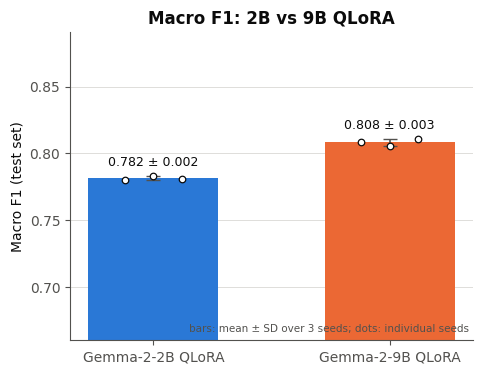

In [ ]:
# Section 9.2 - Figure: 2B vs 9B Macro F1 (test set, three seeds)
rows = []
for key, m in EVAL.items():
    rows.append({"config": m["config"], "seed": m["seed"], "macro_f1": float(m["macro_f1"])})
mf = pd.DataFrame(rows)
summ = mf.groupby("config")["macro_f1"].agg(["mean", "std"]).reindex(CONFIG_ORDER).reset_index()
summ["std"] = summ["std"].fillna(0.0)

fig, ax = plt.subplots(figsize=(5.2, 4))
for i, cfg in enumerate(CONFIG_ORDER):
    r = summ[summ["config"] == cfg].iloc[0]
    ax.bar(i, r["mean"], 0.55, color=CONFIG_COLORS[cfg], yerr=r["std"], capsize=5,
           error_kw={"ecolor": INK2, "lw": 1.2}, label=CONFIG_TITLES[cfg])
    pts = mf[mf["config"] == cfg]["macro_f1"].values
    ax.scatter(np.full(len(pts), i) + np.linspace(-0.12, 0.12, len(pts)), pts, s=22, color="white",
               edgecolor=INK, zorder=3, lw=0.9)
    ax.annotate(f"{r['mean']:.3f} ± {r['std']:.3f}", (i, r["mean"] + r["std"]), ha="center", va="bottom",
                xytext=(0, 5), textcoords="offset points", fontsize=9, color=INK)
ax.set_xticks(range(len(CONFIG_ORDER))); ax.set_xticklabels([CONFIG_TITLES[c] for c in CONFIG_ORDER])
ax.set_ylabel("Macro F1 (test set)")
lo = max(0.0, float(mf["macro_f1"].min()) - 0.12); hi = min(1.0, float(mf["macro_f1"].max()) + 0.08)
ax.set_ylim(lo, hi)
ax.set_title("Macro F1: 2B vs 9B QLoRA")
ax.text(0.99, 0.02, "bars: mean ± SD over 3 seeds; dots: individual seeds", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=7.5, color=INK2)
out = mf.merge(summ.rename(columns={"mean": "macro_f1_mean", "std": "macro_f1_std"}), on="config")
save_fig(fig, "fig_macro_f1_2b_vs_9b", out)

### Explanation — Section 9.2: Figure — 2B vs 9B Macro F1

**Implements:** Paper Section 3.6 (Macro F1); Paper Section 3.7.3 (mean and standard deviation
across seeds)

**What it does.** Draws the test-set Macro F1 of the two configurations as bars (mean across the
three seeds) with error bars of one sample standard deviation, and overlays the three individual
seed scores as dots.

**Why.** Paper Section 3.7.3 calls a difference practically meaningful only if it exceeds one
standard deviation, so the error bars are the point of the figure: if the bars overlap by more
than their error bars, the difference is seed noise. The dots show all three seeds because a
standard deviation over three points is itself a coarse estimate. The y-axis does not start at
zero, to make a small difference visible; the labels carry the exact numbers.

**Key parameters**

| Element | Meaning |
|---|---|
| Bar | Mean Macro F1 over seeds 42, 1337, 2024 |
| Error bar | Sample standard deviation (n = 3) |
| Dots | Individual seeds |

**Check:** the labels match `table_global_performance.csv` from Section 9.1; the source numbers
are in `tables/fig_macro_f1_2b_vs_9b.csv`.

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_zero_shot_vs_finetuned.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_zero_shot_vs_finetuned.csv


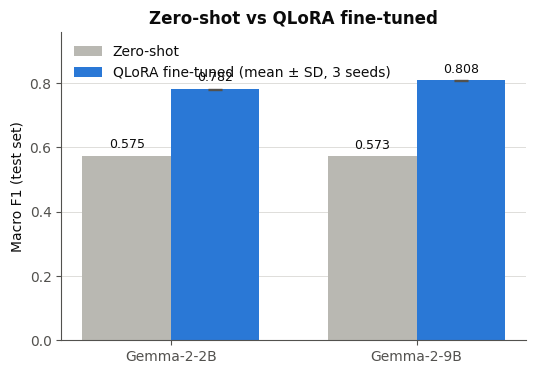

In [ ]:
# Section 9.3 - Figure: zero-shot vs fine-tuned (Macro F1 on the test set)
zs = {}
for size in ["2b", "9b"]:
    f = f"{PATHS['predictions']}/zeroshot_{size}_test.csv"
    if os.path.exists(f):
        p = pd.read_csv(f)
        zs[size] = compute_metrics(p["gold"].values, p["pred"].values)["macro_f1"]
assert zs, "No zero-shot predictions found. Run Section 7.1 first."

SIZES = [("2b", "Gemma-2-2B"), ("9b", "Gemma-2-9B")]
rows = []
for size, title in SIZES:
    ft = mf[mf["config"] == f"{size}_qlora"]["macro_f1"]
    rows.append({"model": title, "zero_shot_macro_f1": zs.get(size, np.nan),
                 "qlora_macro_f1_mean": ft.mean(), "qlora_macro_f1_std": ft.std(ddof=1) if len(ft) > 1 else 0.0})
zdf = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(SIZES)); w = 0.36
b1 = ax.bar(x - w/2, zdf["zero_shot_macro_f1"], w, color="#b9b8b2", label="Zero-shot")
b2 = ax.bar(x + w/2, zdf["qlora_macro_f1_mean"], w, color=C1, yerr=zdf["qlora_macro_f1_std"], capsize=5,
            error_kw={"ecolor": INK2, "lw": 1.2}, label="QLoRA fine-tuned (mean ± SD, 3 seeds)")
for b, v in zip(b1, zdf["zero_shot_macro_f1"]):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", fontsize=9)
for b, v, s in zip(b2, zdf["qlora_macro_f1_mean"], zdf["qlora_macro_f1_std"]):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v + s), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(zdf["model"]); ax.set_ylabel("Macro F1 (test set)")
ax.set_ylim(0, min(1.0, float(np.nanmax(zdf[["zero_shot_macro_f1", "qlora_macro_f1_mean"]].values)) + 0.15))
ax.set_title("Zero-shot vs QLoRA fine-tuned")
ax.legend(loc="upper left")
save_fig(fig, "fig_zero_shot_vs_finetuned", zdf)

### Explanation — Section 9.3: Figure — Zero-Shot vs Fine-Tuned

**Implements:** Paper Section 3.5.4 (zero-shot baseline as reference); Paper Section 1.4
(performance relative to the baseline)

**What it does.** For each model size, places the zero-shot Macro F1 from Section 7.1 next to the
mean QLoRA Macro F1 from Section 9.1 (error bar: standard deviation over three seeds).

**Why.** Paper Section 3.5.4 makes the zero-shot result the reference point against which the gain
from parameter-efficient fine-tuning is quantified, and this figure is that comparison. Zero-shot
has no error bar because it involves no training and no seed, only the constrained argmax over the
three label tokens. Both baselines are scored on the **final-label** test set, the same gold
labels as the fine-tuned runs, so the gap is attributable to fine-tuning and not to a change of
labels. The y-axis starts at zero here because the quantity of interest is the size of the gain.

**Key parameters**

| Element | Meaning |
|---|---|
| Grey bar | Unmodified base model, same prompt, constrained decoding |
| Blue bar | QLoRA adapter, mean over three seeds |

**Check:** the zero-shot values match `table_zeroshot_baseline.csv` from Section 9.1.

# Section 10: Per-Class Metrics

Second metric family: F1, precision and recall for the Positive, Neutral and Negative classes.

,Configuration,Seeds,f1_negative,f1_neutral,f1_positive
0,2b_qlora,3,0.8784 +/- 0.0017,0.6037 +/- 0.0039,0.8625 +/- 0.0019
1,9b_qlora,3,0.8967 +/- 0.0019,0.6530 +/- 0.0110,0.8752 +/- 0.0042


Precision  Recall      F1
Config   Class                              
2b_qlora Negative     0.8835  0.8736  0.8784
         Neutral      0.5649  0.6483  0.6037
         Positive     0.8830  0.8432  0.8625
9b_qlora Negative     0.8956  0.8980  0.8967
         Neutral      0.6134  0.6995  0.6530
         Positive     0.9028  0.8492  0.8752

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_per_class_f1.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_per_class_f1.csv


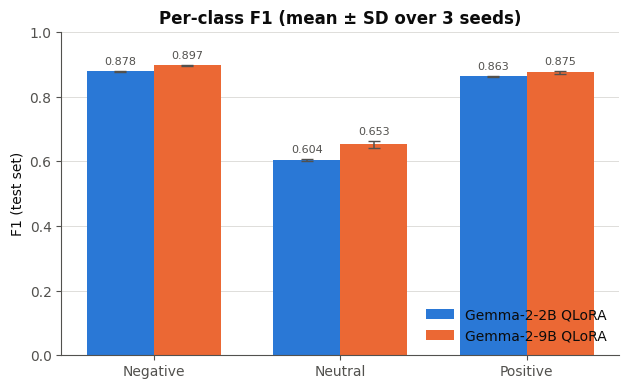

In [ ]:
# Section 10.1 - Per-class F1, precision and recall, with the per-class F1 figure
PER_CLASS_METRICS = ["f1_negative", "f1_neutral", "f1_positive"]
agg_class = aggregate_seeds(EVAL, PER_CLASS_METRICS)
display(agg_class[["Configuration", "Seeds"] + PER_CLASS_METRICS])
agg_class.to_csv(f"{PATHS['tables']}/table_per_class_f1.csv", index=False)

# Precision/recall detail
detail_rows = []
for key, m in EVAL.items():
    for name in CLASS_NAMES:
        k = name.lower()
        detail_rows.append({"Run": key, "Class": name,
                            "Precision": round(m[f"precision_{k}"], 4),
                            "Recall":    round(m[f"recall_{k}"], 4),
                            "F1":        round(m[f"f1_{k}"], 4),
                            "Support":   m[f"support_{k}"]})
detail_df = pd.DataFrame(detail_rows)
detail_df.to_csv(f"{PATHS['tables']}/table_per_class_detail.csv", index=False)
detail_df["Config"] = detail_df["Run"].str.replace(r"_seed\d+$", "", regex=True)
display(detail_df.groupby(["Config", "Class"])[["Precision", "Recall", "F1"]].mean().round(4))

# Figure: per-class F1, bars = mean over seeds, error bars = SD over seeds
rows = []
for cfg in CONFIG_ORDER:
    for name in CLASS_NAMES:
        v = np.array([m[f"f1_{name.lower()}"] for m in EVAL.values() if m["config"] == cfg], dtype=float)
        rows.append({"config": cfg, "class": name, "f1_mean": v.mean(),
                     "f1_std": v.std(ddof=1) if len(v) > 1 else 0.0, "n_seeds": len(v)})
pcf = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
x = np.arange(len(CLASS_NAMES)); w = 0.36
for j, cfg in enumerate(CONFIG_ORDER):
    s = pcf[pcf["config"] == cfg].set_index("class").loc[CLASS_NAMES]
    xs = x + (j - 0.5) * w
    ax.bar(xs, s["f1_mean"], w, color=CONFIG_COLORS[cfg], yerr=s["f1_std"], capsize=4,
           error_kw={"ecolor": INK2, "lw": 1.1}, label=CONFIG_TITLES[cfg])
    for xi, mean, sd in zip(xs, s["f1_mean"], s["f1_std"]):
        ax.annotate(f"{mean:.3f}", (xi, mean + sd), ha="center", va="bottom", xytext=(0, 3),
                    textcoords="offset points", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("F1 (test set)"); ax.set_ylim(0, min(1.0, float(pcf["f1_mean"].max() + pcf["f1_std"].max()) + 0.15))
ax.set_title("Per-class F1 (mean ± SD over 3 seeds)")
ax.legend(loc="lower right")
save_fig(fig, "fig_per_class_f1", pcf)

### Explanation — Section 10.1: Per-Class Metrics

**Implements:** Paper Section 3.6 (per-class metrics)

**What it does.** Reports per-class F1 aggregated across seeds, the precision and recall behind
those scores, and a confusion matrix.

**Why.** This section carries the third research question. Neutral occupies the boundary between the
two polarized classes, and under the revised labels it also mixes genuinely balanced reviews with
factual ones and with three-star reviews that no rule could decide. Both factors make a low Neutral
F1 plausible; the interesting question is whether the larger 9B model narrows that gap. Precision and recall are reported separately because F1 alone cannot distinguish two very
different failure modes — a model that predicts Neutral rarely but accurately fails differently
from one that over-applies it, and only the confusion matrix reveals which neighbouring class
absorbs the errors.

**Key parameters**

| Class | Final label means | Expected difficulty |
|---|---|---|
| Negative | Criteria Negative, or star 1-2 when no rule fired | Moderate |
| Neutral | Balanced / factual text, or star 3 when no rule fired | Highest (boundary class) |
| Positive | Criteria Positive, or star 4-5 when no rule fired | Lowest |

**Check:** the per-class figure (error bars show seed variability: a gap smaller than the bars is
not a finding), and whether Neutral errors fall predominantly into Positive, into Negative, or split
evenly. An asymmetric pattern is a concrete Chapter 4 observation rather than a generic statement
about class imbalance.

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_confusion_matrices.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_confusion_matrices.csv


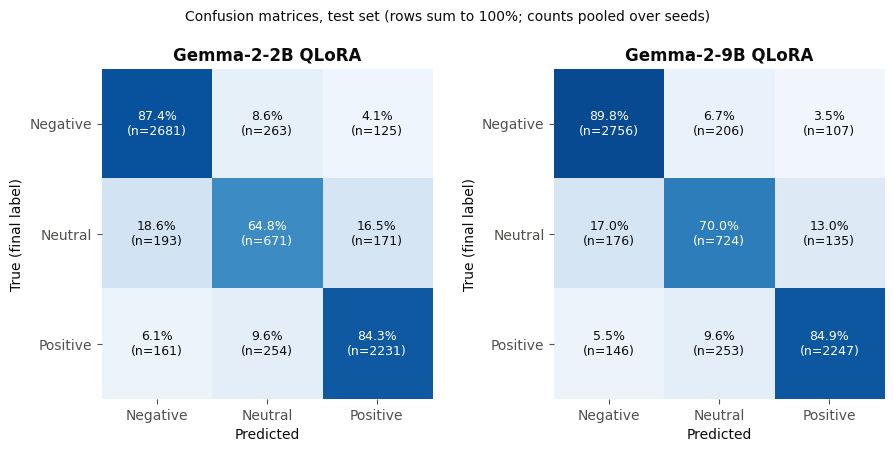

In [ ]:
# Section 10.2 - Figure: confusion matrices (seeds pooled, row-normalised)
cm_rows = []
fig, axes = plt.subplots(1, len(CONFIG_ORDER), figsize=(4.6 * len(CONFIG_ORDER), 4.4))
axes = np.atleast_1d(axes)
for ax, cfg in zip(axes, CONFIG_ORDER):
    cm = np.zeros((3, 3), dtype=int); n_runs = 0
    for s in SEEDS:
        f = f"{PATHS['predictions']}/{cfg}_seed{s}_test.csv"
        if os.path.exists(f):
            p = pd.read_csv(f)
            cm += confusion_matrix(p["gold"], p["pred"], labels=[0, 1, 2]); n_runs += 1
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct[i, j]:.1f}%\n(n={cm[i, j]})", ha="center", va="center", fontsize=9,
                    color="white" if pct[i, j] > 55 else INK)
            cm_rows.append({"config": cfg, "true": CLASS_NAMES[i], "pred": CLASS_NAMES[j],
                            "count_pooled_seeds": int(cm[i, j]), "row_pct": round(float(pct[i, j]), 2),
                            "seeds_pooled": n_runs})
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True (final label)")
    ax.set_title(f"{CONFIG_TITLES[cfg]}")
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("Confusion matrices, test set (rows sum to 100%; counts pooled over seeds)", fontsize=10, y=1.0)
fig.tight_layout()
save_fig(fig, "fig_confusion_matrices", pd.DataFrame(cm_rows))

### Explanation — Section 10.2: Figure — Confusion Matrices

**Implements:** Paper Section 3.6 (per-class analysis; confusion structure)

**What it does.** Draws one confusion matrix per configuration on the test set. The counts of the
three seeds are pooled and each row is shown as a percentage of that true class, with the pooled
count in brackets.

**Why.** F1 says how well a class is recognized; the confusion matrix says *where the mistakes
go*. Rows are normalized so a class with fewer reviews is not visually dominated by a larger one.
The true class is the **final label**, so a review the criteria moved from its star label is
judged against the criteria, not the star. Pooling the seeds gives one stable picture per
configuration instead of three noisy ones; the per-seed matrices can be rebuilt from
`predictions/`.

**Key parameters**

| Element | Meaning |
|---|---|
| Cell colour | Share of the true class (row) predicted as the column class |
| Bracketed n | Pooled count over all seeds |

**Check:** whether Neutral errors are absorbed mostly by Positive, by Negative, or evenly, and
whether the pattern is the same for 2B and 9B.

# Section 11: Linguistic Focus Metrics

Implements Paper Section 3.7.1: the curated Challenger Set and its Macro F1. The Challenger Set
is the **old 244-review set, reused as it is**, and scored against the new `final_label`. The
Disagreement Rate (Paper Section 3.7.2) is dropped with the LoRA-vs-QLoRA comparison.

In [ ]:
# Section 11.1 - Load the Challenger Set (REUSED from the old annotation, nothing re-annotated)
ch_path = find_legacy("challenger_candidates.csv")
ch_old  = pd.read_csv(ch_path)
need = {"sample_id", "star", "annotator_1_include", "annotator_2_include", "adjudicated_include"}
assert need <= set(ch_old.columns), f"{ch_path} is missing {sorted(need - set(ch_old.columns))}"

CHALLENGER_IDS = (ch_old.loc[ch_old["adjudicated_include"].fillna(0).astype(int) == 1, "sample_id"]
                  .astype(str).tolist())
test_lookup = df["test"].set_index("sample_id")
missing = [s for s in CHALLENGER_IDS if s not in test_lookup.index]
assert not missing, f"{len(missing)} old Challenger ids are not in the rebuilt test partition: {missing[:5]}"
star_old = ch_old.set_index("sample_id").loc[CHALLENGER_IDS, "star"].astype(int)
assert (star_old.values == test_lookup.loc[CHALLENGER_IDS, "star"].astype(int).values).all(), \
    "Old Challenger stars do not match the rebuilt test partition."
assert len(CHALLENGER_IDS) == 244, f"Expected the old 244 Challenger ids, found {len(CHALLENGER_IDS)}"

KAPPA_CHAL = cohen_kappa_score(ch_old["annotator_1_include"].astype(int), ch_old["annotator_2_include"].astype(int))
print(f"Reusing {ch_path}")
print(f"Challenger Set: {len(CHALLENGER_IDS)} reviews (all in the test partition, stars match).")
print(f"Historical round-1 Cohen's kappa of the old annotation = {KAPPA_CHAL:.4f} (target 0.70; not re-annotated)")

chal = test_lookup.loc[CHALLENGER_IDS]
comp = pd.DataFrame({"Class": CLASS_NAMES,
                     "star_label": [int((chal["star_label"] == c).sum()) for c in CLASS_NAMES],
                     "final_label": [int((chal["final_label"] == c).sum()) for c in CLASS_NAMES]})
print(f"\nLabel of the 244 Challenger reviews: {int((chal['final_label'] != chal['star_label']).sum())} "
      f"changed from the star label to the final label.")
display(comp)
comp.to_csv(f"{PATHS['tables']}/table_challenger_composition.csv", index=False)

Reusing /content/drive/MyDrive/taglish_peft_thesis/annotation/challenger_candidates.csv
Challenger Set: 244 reviews (all in the test partition, stars match).
Historical round-1 Cohen's kappa of the old annotation = 0.0600 (target 0.70; not re-annotated)

Label of the 244 Challenger reviews: 117 changed from the star label to the final label.


,Class,star_label,final_label
0,Negative,92,111
1,Neutral,65,44
2,Positive,87,89


### Explanation — Section 11.1: Loading the Challenger Set (Reused)

**Implements:** Paper Section 3.7.1 (curated Challenger Set)

**What it does.** Reads the old, already-merged `challenger_candidates.csv`, takes the reviews
whose adjudicated include flag is 1, and verifies that there are exactly 244, that every one is in
the rebuilt test partition, and that the star ratings in the old file match the rebuilt data. It
then shows how many of the 244 changed label under the new `final_label`.

**Why.** Paper Section 3.7.1 prescribes manual curation of the Challenger Set by two independent
annotators, and that curation was already done. Re-ranking and re-annotating would give a
different set (the old candidate ranking used the entropy of the old models' predictions) and
would make the revised results incomparable with the old ones, so the 244 ids are kept exactly.
What changes is the *gold label*: the set is scored against `final_label`. The old kappa
(0.06 round 1, resolved by adjudication) is reported as history only. The two checks (ids in the
test partition, stars matching) guard against loading a file that belongs to a different build of
the dataset.

**Key parameters**

| Item | Value |
|---|---|
| Source | Old annotation file, reused unchanged |
| Size | 244 |
| Gold label | `final_label` (class index in `sentiment`) |

**Check:** `Challenger Set: 244 reviews`, the star-versus-final label table, and the number of
Challenger reviews whose label changed. The Challenger Set is made of multi-clause, mixed reviews,
so a larger share of label changes than in the full data is expected.

In [ ]:
# Section 11.2 - Challenger Set Macro F1 (final-label gold)
def challenger_metrics(run_key, ids):
    p = pd.read_csv(f"{PATHS['predictions']}/{run_key}_test.csv")
    s = p[p["sample_id"].isin(ids)]
    assert len(s) == len(ids), f"{run_key}: {len(s)} of {len(ids)} Challenger reviews have predictions"
    m = compute_metrics(s["gold"].values, s["pred"].values)
    m.update({"run": run_key, "n": len(s)})
    return m

ch_df = pd.DataFrame([challenger_metrics(k, CHALLENGER_IDS) for k in EVAL])
ch_df["config"] = ch_df["run"].str.replace(r"_seed\d+$", "", regex=True)
display(ch_df[["run", "n", "accuracy", "macro_f1", "f1_negative", "f1_neutral", "f1_positive"]])
ch_df.to_csv(f"{PATHS['tables']}/table_challenger_set.csv", index=False)

# Aggregate across seeds, and contrast against full hold-out performance
ch_agg = (ch_df.groupby("config")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))
ch_agg.columns = ["ch_accuracy_mean", "ch_accuracy_std", "ch_macro_f1_mean", "ch_macro_f1_std"]
ch_agg = ch_agg.reset_index()

full = (pd.DataFrame(EVAL).T.groupby("config")["macro_f1"].mean().round(4)
        .rename("full_macro_f1").reset_index())
contrast = ch_agg.merge(full, on="config")
contrast["degradation"] = (contrast["full_macro_f1"] - contrast["ch_macro_f1_mean"]).round(4)
print("\nChallenger Set vs full hold-out (Macro F1):")
display(contrast[["config", "full_macro_f1", "ch_macro_f1_mean", "ch_macro_f1_std", "degradation"]])
contrast.to_csv(f"{PATHS['tables']}/table_challenger_contrast.csv", index=False)

,run,n,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive
0,2b_qlora_seed42,244,0.758197,0.715279,0.843049,0.526316,0.776471
1,2b_qlora_seed1337,244,0.795082,0.762125,0.866359,0.606061,0.813953
2,2b_qlora_seed2024,244,0.778689,0.752491,0.820755,0.613861,0.822857
3,9b_qlora_seed42,244,0.807377,0.790580,0.851852,0.712871,0.807018
4,9b_qlora_seed1337,244,0.790984,0.763109,0.857143,0.627451,0.804734
5,9b_qlora_seed2024,244,0.811475,0.786719,0.872727,0.680412,0.807018



Challenger Set vs full hold-out (Macro F1):


,config,full_macro_f1,ch_macro_f1_mean,ch_macro_f1_std,degradation
0,2b_qlora,0.781544,0.7433,0.0247,0.038244
1,9b_qlora,0.808291,0.7801,0.0149,0.028191


### Explanation — Section 11.2: Challenger Set Macro F1

**Implements:** Paper Section 3.7.1 (Challenger Set Macro F1)

**What it does.** Scores every run on the 244 reused Challenger reviews against the final label,
aggregates over seeds, and contrasts the result with the same configuration's Macro F1 on the full
2,250-review test set.

**Why.** The primary output is Challenger Set Macro F1, defined in Paper Section 3.7.1 as standard
Macro F1 computed only on the curated subset. Its diagnostic value comes from the `degradation`
contrast with full hold-out performance. With the LoRA/QLoRA comparison dropped, the question this
section now answers is about **scale**: does the 9B model keep more of its accuracy than the 2B on
dense code-mixed, slang-heavy and affixed constructions, or do both degrade by a similar amount?
The assertion that every run has a prediction for all 244 reviews makes a silent partial
evaluation impossible. `gold` in the prediction files is the final label, so the Challenger Set
is judged by the same labels as the rest of the test set.

**Key parameters**

| Item | Value |
|---|---|
| Subset | 244 reused ids |
| Metric | Macro F1 on the subset, contrasted with full hold-out |
| Seeds | 42, 1337, 2024 (mean and SD reported) |

**Check:** the `degradation` column per configuration. The standard deviation over only three
seeds on a 244-review subset is wide, so apply the one-standard-deviation rule of Paper Section
3.7.3 before calling one model more robust than the other.

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_challenger_vs_full.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_challenger_vs_full.csv


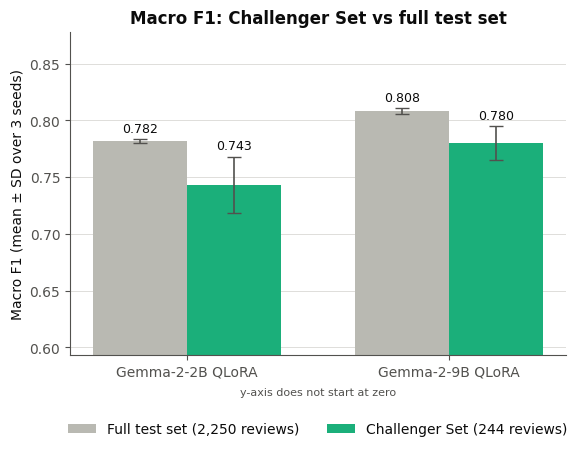

In [ ]:
# Section 11.3 - Figure: Challenger Set vs full test set (Macro F1)
rows = []
for cfg in CONFIG_ORDER:
    full = np.array([m["macro_f1"] for m in EVAL.values() if m["config"] == cfg], dtype=float)
    chal = ch_df.loc[ch_df["config"] == cfg, "macro_f1"].values.astype(float)
    rows.append({"config": cfg,
                 "full_test_macro_f1_mean": full.mean(),
                 "full_test_macro_f1_std": full.std(ddof=1) if len(full) > 1 else 0.0,
                 "challenger_macro_f1_mean": chal.mean(),
                 "challenger_macro_f1_std": chal.std(ddof=1) if len(chal) > 1 else 0.0})
chf = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.4, 4.2))
x = np.arange(len(CONFIG_ORDER)); w = 0.36
for off, col, key, lab in [(-w / 2, "#b9b9b2", "full_test", "Full test set (2,250 reviews)"),
                           (+w / 2, C3, "challenger", "Challenger Set (244 reviews)")]:
    m, s = chf[f"{key}_macro_f1_mean"].values, chf[f"{key}_macro_f1_std"].values
    ax.bar(x + off, m, w, color=col, yerr=s, capsize=5, error_kw={"ecolor": INK2, "lw": 1.2}, label=lab)
    for xi, mi, si in zip(x + off, m, s):
        ax.annotate(f"{mi:.3f}", (xi, mi + si), ha="center", va="bottom",
                    xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK)
ax.set_xticks(x); ax.set_xticklabels([CONFIG_TITLES[c] for c in CONFIG_ORDER])
lo = float(chf[["full_test_macro_f1_mean", "challenger_macro_f1_mean"]].values.min()) - 0.15
ax.set_ylim(max(0.0, lo), float(chf[["full_test_macro_f1_mean", "challenger_macro_f1_mean"]].values.max()) + 0.07)
ax.set_title("Macro F1: Challenger Set vs full test set")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.17))
ax.set_ylabel("Macro F1 (mean ± SD over 3 seeds)")
ax.set_xlabel("y-axis does not start at zero", fontsize=8, color=INK2, labelpad=6)
save_fig(fig, "fig_challenger_vs_full", chf)

### Explanation — Section 11.3: Figure — Challenger Set vs Full Test Set

**Implements:** Paper Section 3.7.1 (Challenger Set Macro F1)

**What it does.** Draws, for each model, the mean Macro F1 on the full test set next to the mean Macro F1 on
the 244 Challenger reviews, with one standard deviation over the three seeds as the error bar.

**Why.** Section 11.2 reports the drop as a number; this puts it where the two models can be compared at a
glance. Per Paper Section 3.7.3, a difference between models that is smaller than the error bars is seed
noise, not a finding. The y-axis does not start at zero so the gap is visible, and the labels carry the exact
values.

**Key parameters**

| Element | Meaning |
|---|---|
| Grey bar | Full 2,250-review test set |
| Green bar | 244-review Challenger Set |
| Error bar | Sample SD over seeds 42, 1337, 2024 |

**Check:** the labels match `table_challenger_contrast.csv` from Section 11.2.

# Section 12: Statistical Significance Metrics

Implements Paper Section 3.7.3: McNemar's test on paired contingency tables with continuity
correction and a Bonferroni-corrected threshold. In the revised experiment the single planned
comparison is **2B QLoRA vs 9B QLoRA**, tested once per seed.

In [ ]:
# Section 12.1 - McNemar's test with Bonferroni correction (2B QLoRA vs 9B QLoRA, per seed)
from statsmodels.stats.contingency_tables import mcnemar

PLANNED = [("2b_qlora", "9b_qlora", "RQ2: scaling under 4-bit QLoRA (2B vs 9B)")]
ALPHA   = 0.05
N_TESTS = len(PLANNED) * len(SEEDS)        # one test per seed = 3
ALPHA_CORR = ALPHA / N_TESTS
print(f"Bonferroni: alpha = {ALPHA} / {N_TESTS} tests = {ALPHA_CORR:.5f}")

def mcnemar_pair(run_a, run_b, label, seed):
    fa = f"{PATHS['predictions']}/{run_a}_test.csv"
    fb = f"{PATHS['predictions']}/{run_b}_test.csv"
    if not (os.path.exists(fa) and os.path.exists(fb)): return None
    a, b = pd.read_csv(fa), pd.read_csv(fb)
    m = a.merge(b, on="sample_id", suffixes=("_a", "_b"))
    assert len(m) == len(a) == len(b), "2B and 9B predictions are not aligned on sample_id"
    ca = (m["pred_a"] == m["gold_a"]).values
    cb = (m["pred_b"] == m["gold_b"]).values
    n11 = int((ca & cb).sum());      n10 = int((ca & ~cb).sum())
    n01 = int((~ca & cb).sum());     n00 = int((~ca & ~cb).sum())
    disc  = n01 + n10
    exact = disc < 25                  # exact binomial when discordant count is small
    res = mcnemar([[n11, n10], [n01, n00]], exact=exact, correction=not exact)
    return {"Comparison": label, "Seed": seed, "Model A": run_a, "Model B": run_b,
            "a (both correct)": n11, "b (A only)": n10, "c (B only)": n01,
            "d (both wrong)": n00, "Discordant": disc,
            "Test": "exact binomial" if exact else "chi2 with continuity",
            "Statistic": round(float(res.statistic), 4), "p-value": float(res.pvalue),
            "Alpha (Bonferroni)": round(ALPHA_CORR, 5), "Significant": bool(res.pvalue < ALPHA_CORR)}

rows = [r for A, B, label in PLANNED for s in SEEDS
        if (r := mcnemar_pair(f"{A}_seed{s}", f"{B}_seed{s}", label, s))]
mc_df = pd.DataFrame(rows)
if len(mc_df):
    show = mc_df.copy(); show["p-value"] = show["p-value"].apply(lambda p: f"{p:.3e}")
    display(show)
    mc_df.to_csv(f"{PATHS['tables']}/table_mcnemar.csv", index=False)
else:
    print("No comparable prediction pairs available yet.")

Bonferroni: alpha = 0.05 / 3 tests = 0.01667


,Comparison,Seed,Model A,Model B,a (both correct),b (A only),c (B only),d (both wrong),Discordant,Test,Statistic,p-value,Alpha (Bonferroni),Significant
0,RQ2: scaling under 4-bit QLoRA (2B vs 9B),42,2b_qlora_seed42,9b_qlora_seed42,1778,83,127,262,210,chi2 with continuity,8.8048,3.004e-03,0.01667,True
1,RQ2: scaling under 4-bit QLoRA (2B vs 9B),1337,2b_qlora_seed1337,9b_qlora_seed1337,1771,92,135,252,227,chi2 with continuity,7.7709,5.309e-03,0.01667,True
2,RQ2: scaling under 4-bit QLoRA (2B vs 9B),2024,2b_qlora_seed2024,9b_qlora_seed2024,1777,82,139,252,221,chi2 with continuity,14.1900,1.652e-04,0.01667,True


### Explanation — Section 12.1: McNemar's Test with Bonferroni Correction

**Implements:** Paper Section 3.7.3, Table 3.9

**What it does.** For each seed, builds the paired contingency table of 2B QLoRA against 9B QLoRA
(same seed, same 2,250 test reviews, same final-label gold) and applies McNemar's test with
continuity correction, switching to the exact binomial form when the discordant count is below 25.

**The Bonferroni threshold, recomputed.** The original notebook pre-registered four comparisons
(two precision contrasts, two scaling contrasts) and used alpha = 0.05 / 4 = 0.0125. Three of those
four involved LoRA and are gone, so that threshold no longer applies. The revised design has one
planned comparison, tested separately for each of the three seeds, which is three tests of the same
hypothesis. Dividing by one comparison would leave alpha at 0.05 and make the correction vacuous,
so the correction is applied over the **three tests that are actually interpreted**:
**alpha = 0.05 / 3 = 0.01667**. This is the more conservative reading; if you and your adviser
prefer to count the comparison only once, change `N_TESTS` to `len(PLANNED)` and note it in
Chapter 3. Paper Section 3.7.3 says only that the threshold is 0.05 divided by the number of
comparisons.

**Why.** McNemar's test looks only at the discordant cells b and c (one model right, the other
wrong). Comparisons are matched within seed, so the test isolates the effect of model size rather
than folding in seed variance. The exact-binomial switch is not optional: the continuity-corrected
chi-squared approximation is unreliable when the discordant count is small. With a few hundred
discordant reviews between a 2B and a 9B model this branch will rarely be used, but it stays so the
cell is correct for any pair.

**Key parameters**

| Cell | Meaning |
|---|---|
| a | Both configurations correct |
| b | Only 2B correct |
| c | Only 9B correct |
| d | Both wrong |
| Test statistic | Computed from b and c only |
| Alpha | 0.05 / 3 = 0.01667 |

**Check:** the discordant counts b and c, not only the p-value. Paper Section 3.7.3 requires
reporting the counts, the statistic, the exact p-value, and the decision against the corrected
threshold. A comparison that fails to reach significance must be described as numerically
different but not statistically distinguishable. If the seeds disagree (significant for one,
not for another), report that instability instead of picking one seed.

saved  /content/drive/MyDrive/Thesis_Revised/figures/fig_mcnemar_discordant.png  (300 dpi)
       /content/drive/MyDrive/Thesis_Revised/tables/fig_mcnemar_discordant.csv


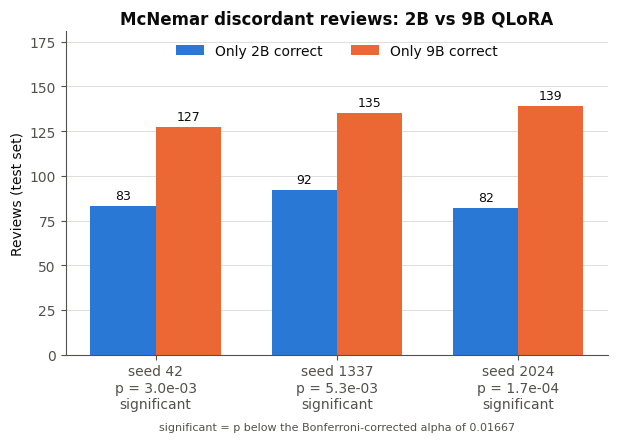

In [ ]:
# Section 12.2 - Figure: McNemar discordant counts per seed (only 2B correct vs only 9B correct)
assert len(mc_df), "Run Section 12.1 first (no McNemar results)."
md_ = mc_df.copy()
md_["only_2b_correct"] = md_["b (A only)"].astype(int)     # model A = 2B QLoRA
md_["only_9b_correct"] = md_["c (B only)"].astype(int)     # model B = 9B QLoRA
mcf = md_[["Seed", "only_2b_correct", "only_9b_correct", "p-value", "Alpha (Bonferroni)", "Significant"]].copy()

fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(mcf)); w = 0.36
b1 = ax.bar(x - w / 2, mcf["only_2b_correct"], w, color=CONFIG_COLORS["2b_qlora"], label="Only 2B correct")
b2 = ax.bar(x + w / 2, mcf["only_9b_correct"], w, color=CONFIG_COLORS["9b_qlora"], label="Only 9B correct")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{int(b.get_height())}", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK)
ax.set_xticks(x)
ax.set_xticklabels([f"seed {int(r['Seed'])}\np = {r['p-value']:.1e}\n" + ("significant" if r["Significant"] else "not significant")
                    for _, r in mcf.iterrows()])
ax.set_ylabel("Reviews (test set)")
ax.set_ylim(0, float(max(mcf["only_2b_correct"].max(), mcf["only_9b_correct"].max())) * 1.3)
ax.set_title("McNemar discordant reviews: 2B vs 9B QLoRA")
ax.legend(loc="upper center", ncol=2)
ax.set_xlabel(f"significant = p below the Bonferroni-corrected alpha of {float(mcf['Alpha (Bonferroni)'].iloc[0]):.5f}", fontsize=8, color=INK2, labelpad=8)
save_fig(fig, "fig_mcnemar_discordant", mcf)

### Explanation — Section 12.2: Figure — McNemar Discordant Counts

**Implements:** Paper Section 3.7.3 (McNemar's test, cells b and c)

**What it does.** For each seed, draws the two cells that McNemar's test actually uses: the reviews only the
2B model got right (b) and the reviews only the 9B model got right (c).

**Why.** The p-value alone hides the direction of the difference. When one bar is clearly taller, that model
is the one winning the disagreements; when the bars are about equal, the test finds no difference. The label
under each seed states whether its p-value passed the Bonferroni-corrected threshold from Section 12.1.

**Key parameters**

| Element | Meaning |
|---|---|
| Blue bar | b: only 2B QLoRA correct |
| Orange bar | c: only 9B QLoRA correct |
| Label | p-value and decision against the corrected alpha |

**Check:** the counts match the `a (both correct)`/`b`/`c` columns of `table_mcnemar.csv`.

# Section 13: Results Export

Assembles the Chapter 4 tables and the reproducibility manifest.

In [ ]:
# Section 13.1 - Chapter 4 table export
def export_chapter4():
    out = {}
    g = agg_global[["Configuration"] + GLOBAL_METRICS].copy()
    g.columns = ["Configuration", "Accuracy", "Macro F1", "Weighted F1"]
    out["table_global_performance"] = g

    pc = agg_class[["Configuration"] + PER_CLASS_METRICS].copy()
    pc.columns = ["Configuration", "F1 Negative", "F1 Neutral", "F1 Positive"]
    out["table_per_class_f1"] = pc

    if zs_rows:      out["table_zeroshot_baseline"]  = zs_df
    out["table_challenger_contrast"] = contrast
    if len(mc_df):   out["table_mcnemar"]            = mc_df
    out["table_class_weights"]       = weight_df
    out["table_criteria_vs_star"]    = cmp_df
    out["table_rule_fired"]          = rule_counts

    for name, t in out.items():
        t.to_csv(f"{PATHS['tables']}/{name}.csv", index=False)
        print(f"\n### {name}"); display(t)
    return out

TABLES = export_chapter4()
print(f"\nAll tables written to {PATHS['tables']}")
print(f"All figures are in    {PATHS['figures']}")


### table_global_performance


,Configuration,Accuracy,Macro F1,Weighted F1
0,2b_qlora,0.8271 +/- 0.0009,0.7815 +/- 0.0017,0.8301 +/- 0.0011
1,9b_qlora,0.8484 +/- 0.0027,0.8083 +/- 0.0025,0.8509 +/- 0.0012



### table_per_class_f1


,Configuration,F1 Negative,F1 Neutral,F1 Positive
0,2b_qlora,0.8784 +/- 0.0017,0.6037 +/- 0.0039,0.8625 +/- 0.0019
1,9b_qlora,0.8967 +/- 0.0019,0.6530 +/- 0.0110,0.8752 +/- 0.0042



### table_zeroshot_baseline


,Configuration,accuracy,macro_f1,weighted_f1
0,2b zero-shot,0.656000,0.574562,0.656456
1,9b zero-shot,0.677333,0.573324,0.660994


... (7 outputs left out)

,group,reviews,rule_fired,disagree,rule_fired_%,disagree_%_of_reviews,disagree_%_of_rule_fired
0,1 star,3000,2316,396,77.20,13.20,17.10
1,2 star,3000,2287,830,76.23,27.67,36.29
2,3 star,3000,2414,1856,80.47,61.87,76.88
3,4 star,3000,2629,1177,87.63,39.23,44.77
4,5 star,3000,2673,448,89.10,14.93,16.76
5,All reviews,15000,12319,4707,82.13,31.38,38.21



### table_rule_fired


,rule_fired,reviews,share_%
0,R3_positive,4561,30.41
1,R1_serious_unresolved,3236,21.57
2,none,2681,17.87
3,R4_mixed_balanced,1524,10.16
4,R3_negative,1043,6.95
5,R1_verdict_negative,767,5.11
6,R4_mixed_positive_dominates,670,4.47
7,R5_neutral_expression,270,1.80
8,R4_mixed_negative_dominates,172,1.15
9,R5_factual_no_evaluation,55,0.37



All tables written to /content/drive/MyDrive/Thesis_Revised/tables
All figures are in    /content/drive/MyDrive/Thesis_Revised/figures


### Explanation — Section 13.1: Chapter 4 Table Export

**Implements:** Reporting support for Chapter 4

**What it does.** Collects the aggregated tables produced across Sections 9 to 12 and writes each
to `tables/` as a CSV, displaying it inline for verification.

**Why.** Exporting from the same in-memory objects that produced the on-screen results removes
the transcription step between notebook and manuscript, which is where numbers usually drift. Any
table that is missing simply means its source section has not been run.

**Key parameters**

| Table | Source section |
|---|---|
| `table_global_performance` | Section 9.1 |
| `table_per_class_f1` | Section 10.1 |
| `table_zeroshot_baseline` | Section 7.1 |
| `table_challenger_contrast` | Section 11.2 |
| `table_criteria_vs_star`, `table_rule_fired` | Section 2.5 |
| `table_mcnemar` | Section 12.1 |
| `table_class_weights` | Section 3.1 |

**Check:** each table displayed inline, and the confirmation that files were written to
`tables/`.

In [ ]:
# Section 13.2 - Run manifest for the reproducibility appendix
manifest = {
    "generated": pd.Timestamp.now().isoformat(),
    "dataset": DATASET_ID,
    "partitions": {k: len(v) for k, v in df.items()},
    "instruction": INSTRUCTION,
    "max_len": int(MAX_LEN), "length_percentile": LENGTH_PCTL,
    "template_overhead": int(TEMPLATE_OVERHEAD),
    "class_weights": {CLASS_NAMES[i]: round(float(CLASS_WEIGHTS[i]), 4) for i in range(3)},
    "label_token_ids": LABEL_TOKEN_IDS.tolist(),
    "seeds": SEEDS, "eval_every": EVAL_EVERY, "smoke_test": SMOKE_TEST,
    "compute_dtype": str(COMPUTE_DTYPE), "hardware": HW,
    "bonferroni": {"alpha": ALPHA, "n_tests": N_TESTS, "corrected": ALPHA_CORR},
    "project_root": PROJECT_ROOT,
    "labels": {"labeler": "annotation_guide_v1", "n_reviews": N_ALL, "rule_fired": N_FIRED,
               "criteria_star_disagree": N_DIS,
               "criteria_star_disagree_pct": round(N_DIS / N_ALL * 100, 2)},
    "legacy_files_reused": ["challenger_candidates.csv", "discordance_sample_150.csv"],
    "challenger_set_size": len(CHALLENGER_IDS),
    "completed_runs": sorted(EVAL.keys()),
    "configs": {k: asdict(v) for k, v in CONFIGS.items()},
    "environment": versions,
}
manifest["runs"] = {}
for _k in EVAL:
    _f = f"{PATHS['metrics']}/{_k}_train.json"
    if os.path.exists(_f):
        _t = json.load(open(_f))
        manifest["runs"][_k] = {x: _t.get(x) for x in ["minutes", "peak_vram_gb", "best_val_macro_f1"]}
with open(f"{PATHS['metrics']}/run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print(json.dumps(manifest, indent=2, default=str)[:2500])

{
  "generated": "2026-10-17T09:00:43.241520",
  "dataset": "scaredmeow/shopee-reviews-tl-stars",
  "partitions": {
    "train": 10500,
    "validation": 2250,
    "test": 2250
  },
  "instruction": "You are analyzing product reviews from a Philippine e-commerce platform. The reviews are written in Taglish, a mix of Tagalog and English. Classify the sentiment of the review as Positive, Neutral, or Negative. Answer with one word only.",
  "max_len": 168,
  "length_percentile": 99,
  "template_overhead": 68,
  "class_weights": {
    "Negative": 0.7558,
    "Neutral": 2.0231,
    "Positive": 0.8456
  },
  "label_token_ids": [
    39654,
    70874,
    35202
  ],
  "seeds": [
    42,
    1337,
    2024
  ],
  "eval_every": 200,
  "smoke_test": false,
  "compute_dtype": "torch.bfloat16",
  "hardware": {
    "name": "NVIDIA A100-SXM4-80GB",
    "total_vram_gb": 79.25,
    "compute_capability": "8.0",
    "bf16_native": true,
    "torch": "2.11.0+cu130",
    "python": "3.13.15"
  },
  "bonfer

### Explanation — Section 13.2: Run Manifest

**Implements:** Paper Section 3.1 (reproducibility)

**What it does.** Writes a single manifest recording every run's configuration, seed, wall-clock
time, peak VRAM and best validation Macro F1, alongside the resolved environment.

**Why.** The manifest is what a reader needs to judge whether the experiment could be repeated,
and it is the natural companion to `environment.json` from Section 0.4. Recording peak VRAM and
wall-clock per run also substantiates the efficiency side of the 2B-versus-9B QLoRA comparison,
which the F1 tables alone do not address.

**Check:** one entry per completed run, and a manifest file written to `metrics/`.

# Section 14: Defense Demo

Not part of the paper. One Gradio app for the oral defense with three tabs: the revised
experiment's **results**, a **replay** of stored test-set predictions, and a **text box** that
classifies a review you type with the 2B or the 9B QLoRA adapter.

In [ ]:
# Section 14.1 - Demo app: results, test-set replay, and live classification of a typed review
import sys, random, subprocess
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

C_OK, C_BAD, C_MUTE = "#1a7f37", "#b42318", "#6b7280"
CLASS_CHIP = {"Negative": "#b42318", "Neutral": "#6b7280", "Positive": "#1a7f37"}

def _chip(text, colour):
    return (f"<span style='background:{colour};color:#fff;padding:3px 11px;border-radius:999px;"
            f"font-size:0.9em;font-weight:700;white-space:nowrap'>{text}</span>")

# --- best seed per configuration (display choice only, same rule as Section 8.3) -------------------
def _best_seed(cfg):
    best, best_f1 = None, -1.0
    for s in SEEDS:
        f = f"{PATHS['predictions']}/{cfg}_seed{s}_test.csv"
        if os.path.exists(f):
            p = pd.read_csv(f)
            f1 = compute_metrics(p["gold"].values, p["pred"].values)["macro_f1"]
            if f1 > best_f1: best, best_f1 = s, f1
    return best

BEST_SEED = {c: _best_seed(c) for c in CONFIG_ORDER}
assert all(v is not None for v in BEST_SEED.values()), \
    f"Missing test predictions for {[c for c, v in BEST_SEED.items() if v is None]}. Run Section 8 first."

# --- test-set replay data -----------------------------------------------------------------------------
PROB_COLS = ["p_negative", "p_neutral", "p_positive"]
DEMO = pd.read_csv(f"{PATHS['data']}/test_processed.csv")[
    ["sample_id", "clean_text", "star", "star_label", "criteria_label", "final_label", "rule_fired"]].copy()
for cfg in CONFIG_ORDER:
    p = pd.read_csv(f"{PATHS['predictions']}/{cfg}_seed{BEST_SEED[cfg]}_test.csv")[["sample_id", "pred"] + PROB_COLS]
    p = p.rename(columns={"pred": f"{cfg}__pred", **{c: f"{cfg}__{c}" for c in PROB_COLS}})
    DEMO = DEMO.merge(p, on="sample_id", how="inner")
DEMO = DEMO.reset_index(drop=True)
DEMO_IX  = DEMO.set_index("sample_id", drop=False)
TEST_IDS = DEMO["sample_id"].tolist()
CHAL_IDS = [s for s in CHALLENGER_IDS if s in DEMO_IX.index]
POOL_TEST = f"Full test set ({len(TEST_IDS)})"
POOL_CHAL = f"Challenger Set ({len(CHAL_IDS)})"
POOLS = {POOL_TEST: TEST_IDS, POOL_CHAL: CHAL_IDS}

def _pool_acc(ids):
    sub = DEMO_IX.loc[ids]; gold = sub["final_label"].map(IDX_OF).astype(int)
    return {cfg: float((sub[f"{cfg}__pred"].astype(int) == gold).mean()) for cfg in CONFIG_ORDER}
POOL_ACC = {k: _pool_acc(v) for k, v in POOLS.items()}

def _choice_label(sid):
    t = " ".join(str(DEMO_IX.at[sid, "clean_text"]).split())
    return f"{sid} | {t[:70] + '...' if len(t) > 70 else t}"
CHOICES = {k: [_choice_label(s) for s in v] for k, v in POOLS.items()}
LABEL_OF = {s: _choice_label(s) for s in TEST_IDS}

def pool_strip(pool):
    acc = POOL_ACC[pool]
    cells = "".join(f"<div style='text-align:center;padding:0 18px'><div style='font-size:0.8em;opacity:0.7'>"
                    f"{CONFIG_TITLES[c]}</div><div style='font-size:1.3em;font-weight:800'>{acc[c]*100:.1f}%</div></div>"
                    for c in CONFIG_ORDER)
    return (f"<div style='border:1px solid rgba(128,128,128,0.35);border-radius:10px;padding:10px 12px'>"
            f"<div style='display:flex;justify-content:center;flex-wrap:wrap'>{cells}</div>"
            f"<div style='text-align:center;font-size:0.8em;opacity:0.7;margin-top:6px'>"
            f"Accuracy against the final label on this pool (best seed per model)</div></div>")

def render_review(sid):
    n_out = 2 + 2 * len(CONFIG_ORDER)
    if not sid or sid not in DEMO_IX.index:
        return tuple([""] + ["<div style='opacity:0.7;padding:8px'>Pick a review or press Random review.</div>"]
                     + [x for _ in CONFIG_ORDER for x in ("", None)])
    r = DEMO_IX.loc[sid]
    crit = r["criteria_label"] if isinstance(r["criteria_label"], str) else "no rule fired"
    meta = (f"<div style='border:1px solid rgba(128,128,128,0.35);border-radius:10px;padding:12px 14px'>"
            f"<div style='font-family:monospace;font-size:0.85em;opacity:0.65'>{sid}"
            f"{' &nbsp; ' + _chip('Challenger Set', '#a35a00') if sid in set(CHAL_IDS) else ''}</div>"
            f"<div style='font-size:1.5em;font-weight:800;margin:8px 0 4px'>Final label: {r['final_label']}</div>"
            f"<div style='opacity:0.85'>Star rating {int(r['star'])}/5 &rarr; star label <b>{r['star_label']}</b>"
            f" &nbsp;|&nbsp; criteria label <b>{crit}</b> &nbsp;|&nbsp; rule: <code>{r['rule_fired']}</code></div></div>")
    out = [str(r["clean_text"]), meta]
    gold = IDX_OF[r["final_label"]]
    for cfg in CONFIG_ORDER:
        pred = int(r[f"{cfg}__pred"]); ok = pred == gold
        out.append(f"<div style='font-size:1.25em;font-weight:800'>{CONFIG_TITLES[cfg]}</div>"
                   f"<div style='font-size:0.8em;opacity:0.6;margin-bottom:6px'>seed {BEST_SEED[cfg]}</div>"
                   f"{_chip(('&#10003; ' if ok else '&#10007; ') + CLASS_NAMES[pred], C_OK if ok else C_BAD)}"
                   f"<div style='font-size:0.82em;opacity:0.75;margin-top:6px'>"
                   f"{'matches the final label' if ok else 'final label is ' + r['final_label']}</div>")
        out.append({CLASS_NAMES[i]: float(r[f"{cfg}__{PROB_COLS[i]}"]) for i in range(3)})
    return tuple(out)

def on_random(pool):
    sid = random.choice(POOLS[pool]); return (gr.update(value=LABEL_OF[sid]),) + render_review(sid)
def on_select(choice): return render_review(choice.split(" | ", 1)[0].strip() if choice else "")
def on_pool(pool): return gr.update(choices=CHOICES[pool], value=None), pool_strip(pool)

# --- live classification: load both QLoRA adapters once --------------------------------------------------
LIVE = {}
for cfg in CONFIG_ORDER:
    ada = f"{PATHS['adapters']}/{cfg}_seed{BEST_SEED[cfg]}"
    if not os.path.isdir(ada):
        print(f"[!] No adapter at {ada}; '{cfg}' will be unavailable in the live tab."); continue
    print(f"Loading {CONFIG_TITLES[cfg]} (seed {BEST_SEED[cfg]}) ...", flush=True)
    _base = build_base_model(CONFIGS[cfg], for_training=False)       # same quantisation as training
    LIVE[cfg] = PeftModel.from_pretrained(_base, ada)
    LIVE[cfg].eval()
print(f"Live models ready: {list(LIVE)}")

EXAMPLES = [["Grabe ang pangit ng gamit, sira agad after one use. Sayang pera ko."],
            ["Okay naman, pero medyo mahina ang tela."],
            ["Sobrang ganda, sulit na sulit! Ang bilis pa ng delivery, bibili ulit ako."]]

def _prob_fig(probs):
    # grouped bars: one group per class, one bar per model (same colours as every other figure)
    from matplotlib.figure import Figure
    fig = Figure(figsize=(6.4, 3.4)); ax = fig.subplots()
    n = max(len(probs), 1); w = 0.8 / n
    for j, cfg in enumerate(CONFIG_ORDER):
        if cfg not in probs: continue
        xs = np.arange(3) + (j - (n - 1) / 2) * w
        vals = [probs[cfg][c] * 100 for c in CLASS_NAMES]
        bars = ax.bar(xs, vals, w, color=CONFIG_COLORS[cfg], label=CONFIG_TITLES[cfg])
        for b in bars:
            ax.annotate(f"{b.get_height():.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=8, color=INK)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_ylim(0, 112); ax.set_ylabel("Probability (%)")
    ax.set_title("Class probabilities: 2B vs 9B QLoRA")
    ax.legend(loc="upper right", ncol=2, fontsize=8)
    fig.tight_layout()
    return fig

def classify_both(text):
    """Classify one typed review with every loaded adapter. Returns one head per config, the chart, a note."""
    clean = cleanse(text or "")
    if not clean:
        return (*["<div style='opacity:0.7;padding:6px'>Type a review first.</div>"] * len(CONFIG_ORDER), None, "")
    # same preprocessing, prompt and constrained decoding as training and evaluation (Sections 2.1, 4.1, 6.2)
    rec = encode_split(pd.DataFrame([{"sample_id": "typed", "clean_text": clean, "sentiment": 0}]),
                       tok_probe, MAX_LEN, with_answer=False)[0]
    heads, probs = [], {}
    for cfg in CONFIG_ORDER:
        if cfg not in LIVE:
            heads.append(f"<div style='color:#b42318'>{CONFIG_TITLES[cfg]}: adapter not loaded.</div>"); continue
        preds, _, _, pr = predict_labels(LIVE[cfg], [rec], batch_size=1, return_probs=True)
        pred = CLASS_NAMES[int(preds[0])]
        probs[cfg] = {CLASS_NAMES[i]: float(pr[0][i]) for i in range(3)}
        heads.append(f"<div style='border:1px solid rgba(128,128,128,0.35);border-radius:10px;padding:12px 14px'>"
                     f"<div style='font-size:0.8em;opacity:0.7'>{CONFIG_TITLES[cfg]} (seed {BEST_SEED[cfg]}) predicts</div>"
                     f"<div style='margin-top:6px'>{_chip(pred, CLASS_CHIP[pred])}</div></div>")
    return (*heads, _prob_fig(probs), f"Text sent to the models: {clean}")

# --- results tables ----------------------------------------------------------------------------------------
def _read(name):
    f = f"{PATHS['tables']}/{name}.csv"
    return pd.read_csv(f) if os.path.exists(f) else None
def _img(name):
    f = f"{PATHS['figures']}/{name}.png"
    return f if os.path.exists(f) else None

_cmp = _read("table_criteria_vs_star")
if _cmp is not None:
    _all = _cmp[_cmp["group"] == "All reviews"].iloc[0]
    label_note = (f"**Labels.** The final label is the expert-criteria label when a rule fires, otherwise the star label. "
                  f"A rule fired on {_all['rule_fired_%']:.1f}% of {int(_all['reviews']):,} reviews; criteria and star "
                  f"disagree on {_all['disagree_%_of_reviews']:.1f}% of all reviews.")
else:
    label_note = ""
RESULT_TABLES = [
    ("Global performance (test set, mean ± SD over 3 seeds)", "table_global_performance"),
    ("Per-class F1 (test set, mean ± SD over 3 seeds)", "table_per_class_f1"),
    ("Zero-shot baselines (test set)", "table_zeroshot_baseline"),
    ("Challenger Set (244 reviews) vs full test set, Macro F1", "table_challenger_contrast"),
    ("McNemar's test, 2B vs 9B QLoRA, per seed", "table_mcnemar"),
]

# --- app --------------------------------------------------------------------------------------------------------
with gr.Blocks(title="Taglish Sentiment: 2B vs 9B QLoRA") as demo:
    gr.Markdown("## Fine-Tuning of Sentiment Analysis in Taglish E-Commerce Reviews\n"
                "### Gemma-2-2B QLoRA vs Gemma-2-9B QLoRA (revised experiment)\n"
                "The models read the review text only; the star rating is never given to them.")
    with gr.Tabs():
        with gr.Tab("Results"):
            if label_note: gr.Markdown(label_note)
            for title, name in RESULT_TABLES:
                t = _read(name)
                if t is not None:
                    gr.Markdown(f"**{title}**")
                    gr.Dataframe(value=t, interactive=False, wrap=True)
            with gr.Row():
                for name in ["fig_macro_f1_2b_vs_9b", "fig_zero_shot_vs_finetuned"]:
                    if _img(name): gr.Image(value=_img(name), show_label=False, interactive=False)
            with gr.Row():
                for name in ["fig_per_class_f1", "fig_confusion_matrices"]:
                    if _img(name): gr.Image(value=_img(name), show_label=False, interactive=False)
            with gr.Row():
                for name in ["fig_star_to_final_label", "fig_challenger_vs_full"]:
                    if _img(name): gr.Image(value=_img(name), show_label=False, interactive=False)
            with gr.Row():
                for name in ["fig_mcnemar_discordant"]:
                    if _img(name): gr.Image(value=_img(name), show_label=False, interactive=False)

        with gr.Tab("Browse test reviews"):
            with gr.Row():
                pool = gr.Radio(list(POOLS), value=POOL_TEST, label="Sample pool", scale=2)
                picker = gr.Dropdown(choices=CHOICES[POOL_TEST], value=None, filterable=True,
                                     label="Pick a specific review", scale=5)
                rand_btn = gr.Button("Random review", variant="primary", scale=1)
            strip = gr.HTML(pool_strip(POOL_TEST))
            review_box = gr.Textbox(label="Review text (all the model sees)", lines=4, interactive=False)
            meta_html = gr.HTML()
            panels = []
            with gr.Row():
                for cfg in CONFIG_ORDER:
                    with gr.Column():
                        with gr.Group():
                            head = gr.HTML(); lab = gr.Label(num_top_classes=3, label="Confidence per class")
                            panels += [head, lab]
            outs = [review_box, meta_html] + panels
            rand_btn.click(on_random, inputs=[pool], outputs=[picker] + outs)
            picker.change(on_select, inputs=[picker], outputs=outs)
            pool.change(on_pool, inputs=[pool], outputs=[picker, strip])

        with gr.Tab("Try your own review"):
            gr.Markdown("Type a review in Taglish or English. Both models classify it at once, using the same "
                        "cleansing, prompt and constrained decoding as the experiment.")
            text_in = gr.Textbox(label="Review", lines=4, placeholder="Type a review here...")
            go = gr.Button("Classify", variant="primary")
            with gr.Row():
                try_heads = [gr.HTML() for _ in CONFIG_ORDER]
            prob_plot = gr.Plot(label="Class probabilities")
            note = gr.Markdown()
            gr.Examples(examples=EXAMPLES, inputs=[text_in], label="Examples")
            go.click(classify_both, inputs=[text_in], outputs=try_heads + [prob_plot, note])
            text_in.submit(classify_both, inputs=[text_in], outputs=try_heads + [prob_plot, note])

_kw = dict(share=True, show_error=True)
try:
    if int(gr.__version__.split(".")[0]) >= 6:
        _kw["theme"] = gr.themes.Soft()
except Exception:
    pass
try:
    demo.launch(**_kw)
except TypeError as e:
    print(f"[!] launch() rejected a keyword ({e}); retrying with share only.")
    demo.launch(share=True)

Loading Gemma-2-2B QLoRA (seed 1337) ...


model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/464 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Live models ready: ['2b_qlora', '9b_qlora']
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7fac4ea2f3dfb139f0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Explanation — Section 14.1: Defense Demo App

**Implements:** Nothing in Chapter 3 — this is a presentation artifact. It revises the original
Section 14 app, which compared four LoRA/QLoRA configurations.

**What it does.** Launches one Gradio app with three tabs.

1. **Results.** The revised experiment's tables (global, per-class, zero-shot, Challenger Set,
   McNemar) and four of the figures, read from `tables/` and `figures/`, with one line stating how
   often the criteria and the star disagree.
2. **Browse test reviews.** The original replay: pick a test review or press *Random review* (from
   the full test set or from the 244-review Challenger Set) and see its star, star label, criteria
   label, final label and the rule that fired, next to what 2B QLoRA and 9B QLoRA predicted, with
   the three class probabilities. This tab is a pure lookup of the stored prediction files.
3. **Try your own review.** A text box and a choice of the 2B or 9B QLoRA adapter. The typed text
   is cleansed with `cleanse` (Section 2.1), turned into a prompt by `encode_split` (Section 4.1)
   and scored by `predict_labels` (Section 6.2), the constrained-decoding function from the
   notebook, so the predicted label and the three probabilities come from exactly the code path
   used for evaluation. No external service is called.

**Why.** The two QLoRA adapters (about 2 GB and 6 GB in 4-bit) are loaded once, when the cell runs,
so that the first click in the demo is instant. Each adapter is the best seed by test Macro F1, as
in Section 8.3: a display choice only, the reported numbers remain the three-seed aggregates. In the
replay tab, "correct" means *equal to the final label*, the same gold used everywhere else.

**Running it.** It needs the notebook's definitions, so after a runtime restart choose
`Runtime > Run all` with `SMOKE_TEST = False`: finished training runs, zero-shot baselines and
evaluations are skipped from Drive and nothing is retrained. It needs a GPU for the third tab.

**Key parameters**

| Setting | Value |
|---|---|
| Replay source | `predictions/{config}_seed{best}_test.csv` joined to `data/test_processed.csv` |
| Pools | Full test set and the 244-review Challenger Set |
| Live models | `adapters/2b_qlora_seed{best}`, `adapters/9b_qlora_seed{best}` |
| Requirements | Drive mounted, GPU for the live tab |

**Check:** the printed `Live models ready: ['2b_qlora', '9b_qlora']`, then in the app: the
Results tab tables match Sections 9 to 12, and in the third tab the three probabilities sum to 1
and the highest one is the predicted label.